<a href="https://colab.research.google.com/github/Timoteo369/GTSRB-Clasificacion-DeepLearning/blob/main/Proyecto_VC_GTSRB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PROYECTO DE VISIÓN COMPUTACIONAL

## Análisis Exploratorio y Preprocesamiento del Dataset GTSRB para el Reconocimiento de Señales de Tránsito

**Universidad:** Universidad Nacional de San Antonio Abad del Cusco (UNSAAC)

**Escuela Profesional:** Ingeniería Informática y de Sistemas

**Curso:** Visión Computacional

**Docente:** Dr. Hans Harley Ccacyahuillca Bejar

**Integrantes:**
- Aracely Fiorela Corampa Palacios
- Timoteo Quispe Merma

**Dataset:** German Traffic Sign Recognition Benchmark (GTSRB)

**Entorno de desarrollo:** Python - Google Colab

**Fecha:** 18 de noviembre de 2026

---

### Descripción del proyecto

El proyecto tiene como objetivo analizar y preprocesar el dataset GTSRB, compuesto por 43 clases de señales de tránsito, para preparar imágenes estandarizadas que permitan posteriormente entrenar y evaluar modelos de clasificación mediante redes neuronales convolucionales (CNN).

In [2]:

# PASO 1: Clonar el repositorio del proyecto
# de Visión Computacional desde GitHub.

!git clone https://github.com/Aracely271004/GTSRB-Preprocesamiento.git


Cloning into 'GTSRB-Preprocesamiento'...
remote: Enumerating objects: 32, done.
remote: Counting objects: 100% (32/32), done.
remote: Compressing objects: 100% (29/29), done.
remote: Total 32 (delta 1), reused 32 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (32/32), 5.94 MiB | 11.25 MiB/s, done.
Resolving deltas: 100% (1/1), done.


### Interpretación del Paso 1: Clonación del repositorio

El repositorio `GTSRB-Preprocesamiento` se clonó correctamente en Google Colab, descargando 32 objetos (5.94 MiB) sin errores. Esto confirma que los archivos del proyecto están disponibles para continuar con la verificación de su estructura y la preparación del dataset.

In [3]:

# PASO 2: Verificar el repositorio descargado

from pathlib import Path

# Ruta del proyecto en Google Colab
ROOT = Path("/content/GTSRB-Preprocesamiento")

# Comprobar que existe
print("¿Existe el proyecto?:", ROOT.exists())

# Mostrar carpetas y archivos principales
print("\nContenido del repositorio:")
for elemento in sorted(ROOT.iterdir()):
    tipo = "📁 Carpeta" if elemento.is_dir() else "📄 Archivo"
    print(f"{tipo}: {elemento.name}")

# Comprobar archivos importantes
print("\nVerificación de archivos:")
archivos = [
    "README.md",
    "requirements.txt",
    "notebooks/01_Analisis_Exploratorio_GTSRB.ipynb",
    "data/splits/train.csv",
    "data/splits/val.csv"
]

for archivo in archivos:
    estado = "OK" if (ROOT / archivo).is_file() else "NO ENCONTRADO"
    print(f"{estado}: {archivo}")


¿Existe el proyecto?: True

Contenido del repositorio:
📁 Carpeta: .git
📄 Archivo: .gitignore
📄 Archivo: README.md
📁 Carpeta: data
📁 Carpeta: notebooks
📁 Carpeta: presentacion
📄 Archivo: requirements.txt
📁 Carpeta: results

Verificación de archivos:
OK: README.md
OK: requirements.txt
OK: notebooks/01_Analisis_Exploratorio_GTSRB.ipynb
OK: data/splits/train.csv
OK: data/splits/val.csv


### Interpretación del Paso 2: Verificación del repositorio

Se verificó correctamente la estructura del repositorio `GTSRB-Preprocesamiento` en Google Colab. Los archivos principales, incluyendo el notebook de análisis exploratorio, las dependencias y los CSV de entrenamiento y validación, se encuentran disponibles para continuar con el proyecto.

In [4]:

# PASO 3: Instalación y verificación de dependencias

import sys
import subprocess
from pathlib import Path

ROOT = Path("/content/GTSRB-Preprocesamiento")

# Instalar las dependencias del proyecto
subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "-r", str(ROOT / "requirements.txt")
    ],
    check=True
)

# Comprobar las bibliotecas principales
import numpy
import pandas
import cv2
import matplotlib
import sklearn
import PIL

print("\nDEPENDENCIAS VERIFICADAS")
print("Python:", sys.version.split()[0])
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("OpenCV:", cv2.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Pillow:", PIL.__version__)




DEPENDENCIAS VERIFICADAS
Python: 3.13.16
NumPy: 2.4.6
Pandas: 3.0.6
OpenCV: 4.14.0
Matplotlib: 3.10.0
Scikit-learn: 1.9.1
Pillow: 11.3.0


### Interpretación del Paso 3: Verificación de dependencias

Se instalaron y verificaron correctamente las bibliotecas necesarias para el proyecto GTSRB en Google Colab. No se presentaron errores de importación, por lo que el entorno está preparado para continuar con la descarga y preparación del dataset.

In [5]:

# PASO 4: Descargar el dataset GTSRB original

from pathlib import Path
import subprocess
import zipfile

ROOT = Path("/content/GTSRB-Preprocesamiento")
RAW = ROOT / "data" / "raw"
RAW.mkdir(parents=True, exist_ok=True)

BASE_URL = (
    "https://sid.erda.dk/public/archives/"
    "daaeac0d7ce1152aea9b61d9f1e19370"
)

archivos = [
    "GTSRB_Final_Training_Images.zip",
    "GTSRB_Final_Test_Images.zip",
    "GTSRB_Final_Test_GT.zip"
]

for nombre in archivos:
    destino = RAW / nombre

    if not zipfile.is_zipfile(destino):
        print(f"\nDescargando: {nombre}")

        subprocess.run(
            [
                "wget", "-c", "--show-progress",
                "-O", str(destino),
                f"{BASE_URL}/{nombre}"
            ],
            check=True
        )

    if not zipfile.is_zipfile(destino):
        raise RuntimeError(f"Archivo ZIP inválido: {nombre}")

    tamaño_mb = destino.stat().st_size / (1024 ** 2)
    print(f"OK: {nombre} ({tamaño_mb:.2f} MB)")



Descargando: GTSRB_Final_Training_Images.zip
OK: GTSRB_Final_Training_Images.zip (263.50 MB)

Descargando: GTSRB_Final_Test_Images.zip
OK: GTSRB_Final_Test_Images.zip (84.86 MB)

Descargando: GTSRB_Final_Test_GT.zip
OK: GTSRB_Final_Test_GT.zip (0.10 MB)


### Interpretación del Paso 4: Descarga del dataset GTSRB

Se descargaron correctamente los tres archivos oficiales de GTSRB: imágenes de entrenamiento, imágenes de prueba y anotaciones. Los archivos ZIP fueron validados satisfactoriamente y están disponibles para su extracción y posterior procesamiento.

In [6]:

# PASO 5: Extracción y verificación del dataset GTSRB

from pathlib import Path
import zipfile

ROOT = Path("/content/GTSRB-Preprocesamiento")
RAW = ROOT / "data" / "raw"
EXTRACTED = ROOT / "data" / "extracted"

archivos = {
    "train": "GTSRB_Final_Training_Images.zip",
    "test": "GTSRB_Final_Test_Images.zip",
    "test_gt": "GTSRB_Final_Test_GT.zip"
}

# 1. Extraer los tres archivos ZIP
for conjunto, nombre in archivos.items():
    origen = RAW / nombre
    destino = EXTRACTED / conjunto

    destino.mkdir(parents=True, exist_ok=True)

    print(f"Extrayendo: {nombre}")

    with zipfile.ZipFile(origen, "r") as zip_ref:
        zip_ref.extractall(destino)

    print(f"OK: {conjunto}")

# 2. Verificar las imágenes originales
train = list((EXTRACTED / "train").rglob("*.ppm"))
test = list((EXTRACTED / "test").rglob("*.ppm"))

# 3. Verificar anotaciones
train_csv = list(
    (EXTRACTED / "train").rglob("GT-*.csv")
)

test_gt = list(
    (EXTRACTED / "test_gt").rglob("GT-final_test.csv")
)

print("\nRESULTADOS DE VERIFICACIÓN")
print("Imágenes de entrenamiento:", len(train))
print("Imágenes de prueba:", len(test))
print("CSV de clases de entrenamiento:", len(train_csv))
print("CSV de anotaciones de prueba:", len(test_gt))

# 4. Comprobar integridad estructural
assert len(train) == 39209, "Cantidad incorrecta en train"
assert len(test) == 12630, "Cantidad incorrecta en test"
assert len(train_csv) == 43, "Faltan CSV de clases"
assert len(test_gt) == 1, "Falta CSV de test"



Extrayendo: GTSRB_Final_Training_Images.zip
OK: train
Extrayendo: GTSRB_Final_Test_Images.zip
OK: test
Extrayendo: GTSRB_Final_Test_GT.zip
OK: test_gt

RESULTADOS DE VERIFICACIÓN
Imágenes de entrenamiento: 39209
Imágenes de prueba: 12630
CSV de clases de entrenamiento: 43
CSV de anotaciones de prueba: 1


### Interpretación del Paso 5: Extracción del dataset

Se extrajeron y verificaron 51 839 imágenes del dataset GTSRB, distribuidas en 39 209 de entrenamiento y 12 630 de prueba. También se confirmó la disponibilidad de los 43 CSV de clases y las anotaciones oficiales, sin detectar inconsistencias en las cantidades esperadas.

In [7]:

# PASO 6: Validación de anotaciones y clases

from pathlib import Path
import pandas as pd

ROOT = Path("/content/GTSRB-Preprocesamiento")
EXTRACTED = ROOT / "data" / "extracted"

# Leer los 43 CSV originales de entrenamiento
archivos_csv = sorted(
    (EXTRACTED / "train").rglob("GT-*.csv")
)

train_df = pd.concat(
    [pd.read_csv(archivo, sep=";") for archivo in archivos_csv],
    ignore_index=True
)

# Leer las anotaciones oficiales de prueba
test_csv = next(
    (EXTRACTED / "test_gt").rglob("GT-final_test.csv")
)
test_df = pd.read_csv(test_csv, sep=";")

# Validaciones
assert len(train_df) == 39209
assert len(test_df) == 12630
assert set(train_df["ClassId"]) == set(range(43))
assert set(test_df["ClassId"]) == set(range(43))
assert train_df["ClassId"].notna().all()
assert test_df["ClassId"].notna().all()

# Resumen
print("ANOTACIONES DEL DATASET GTSRB")
print("Train:", len(train_df))
print("Test:", len(test_df))
print("Clases en train:", train_df["ClassId"].nunique())
print("Clases en test:", test_df["ClassId"].nunique())
print("Etiquetas nulas en train:", train_df["ClassId"].isna().sum())
print("Etiquetas nulas en test:", test_df["ClassId"].isna().sum())

print("\nDistribución de clases en entrenamiento:")
print(train_df["ClassId"].value_counts().sort_index().to_string())


ANOTACIONES DEL DATASET GTSRB
Train: 39209
Test: 12630
Clases en train: 43
Clases en test: 43
Etiquetas nulas en train: 0
Etiquetas nulas en test: 0

Distribución de clases en entrenamiento:
ClassId
0      210
1     2220
2     2250
3     1410
4     1980
5     1860
6      420
7     1440
8     1410
9     1470
10    2010
11    1320
12    2100
13    2160
14     780
15     630
16     420
17    1110
18    1200
19     210
20     360
21     330
22     390
23     510
24     270
25    1500
26     600
27     240
28     540
29     270
30     450
31     780
32     240
33     689
34     420
35    1200
36     390
37     210
38    2070
39     300
40     360
41     240
42     240


### Interpretación del Paso 6: Validación de etiquetas y clases

Se verificaron las anotaciones de las 51 839 imágenes, confirmando la presencia de 43 clases sin etiquetas nulas. Se identificó un desbalance significativo entre clases, con frecuencias de 210 a 2 250 imágenes, aspecto que deberá considerarse durante el entrenamiento y la evaluación de los modelos.

In [8]:

# PASO 7: Inspección de las particiones originales

from pathlib import Path
import pandas as pd

ROOT = Path("/content/GTSRB-Preprocesamiento")

train_split = pd.read_csv(ROOT / "data/splits/train.csv")
val_split = pd.read_csv(ROOT / "data/splits/val.csv")

# Tamaño de cada conjunto
print("PARTICIONES DEL PROYECTO")
print("Entrenamiento:", len(train_split))
print("Validación:", len(val_split))
print("Total:", len(train_split) + len(val_split))

# Comprobar cantidades originales
assert len(train_split) == 30869
assert len(val_split) == 8340
assert len(train_split) + len(val_split) == 39209

# Examinar estructura para verificar después
# las rutas y la separación por secuencias
print("\nCOLUMNAS DE LOS CSV")
print("Train:", train_split.columns.tolist())
print("Validation:", val_split.columns.tolist())

print("\nVALORES NULOS")
print("Train:", train_split.isna().sum().sum())
print("Validation:", val_split.isna().sum().sum())

print("\nPRIMERAS FILAS DE ENTRENAMIENTO")
display(train_split.head(3))

print("\nPRIMERAS FILAS DE VALIDACIÓN")
display(val_split.head(3))


PARTICIONES DEL PROYECTO
Entrenamiento: 30869
Validación: 8340
Total: 39209

COLUMNAS DE LOS CSV
Train: ['RutaRelativa', 'ClassId', 'Grupo', 'Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2']
Validation: ['RutaRelativa', 'ClassId', 'Grupo', 'Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2']

VALORES NULOS
Train: 0
Validation: 0

PRIMERAS FILAS DE ENTRENAMIENTO


,RutaRelativa,ClassId,Grupo,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2
0,data/extracted/train/GTSRB/Final_Training/Imag...,0,0_00002,27,26,6,5,22,21
1,data/extracted/train/GTSRB/Final_Training/Imag...,0,0_00002,27,28,5,6,22,23
2,data/extracted/train/GTSRB/Final_Training/Imag...,0,0_00002,27,28,5,6,22,23



PRIMERAS FILAS DE VALIDACIÓN


,RutaRelativa,ClassId,Grupo,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2
0,data/extracted/train/GTSRB/Final_Training/Imag...,0,0_00000,29,30,5,6,24,25
1,data/extracted/train/GTSRB/Final_Training/Imag...,0,0_00000,30,30,5,5,25,25
2,data/extracted/train/GTSRB/Final_Training/Imag...,0,0_00000,30,30,5,5,25,25


### Interpretación del Paso 7: Verificación de particiones

Se verificaron las particiones originales del proyecto, con 30 869 imágenes de entrenamiento y 8 340 de validación. Ambos conjuntos contienen nueve columnas, incluyendo etiquetas, grupos y coordenadas ROI, sin presentar valores nulos.

In [9]:

# PASO 8: Verificación de integridad y separación por grupos

from pathlib import Path
import pandas as pd

ROOT = Path("/content/GTSRB-Preprocesamiento")

# Cargar particiones originales
train_split = pd.read_csv(ROOT / "data/splits/train.csv")
val_split = pd.read_csv(ROOT / "data/splits/val.csv")

# 1. Verificar existencia física de imágenes
rutas_train = [
    ROOT / ruta for ruta in train_split["RutaRelativa"]
]
rutas_val = [
    ROOT / ruta for ruta in val_split["RutaRelativa"]
]

faltantes_train = sum(not p.is_file() for p in rutas_train)
faltantes_val = sum(not p.is_file() for p in rutas_val)

# 2. Verificar que no se compartan imágenes
imagenes_compartidas = (
    set(train_split["RutaRelativa"])
    & set(val_split["RutaRelativa"])
)

# 3. Verificar independencia de grupos
grupos_train = set(train_split["Grupo"])
grupos_val = set(val_split["Grupo"])

grupos_compartidos = grupos_train & grupos_val

# 4. Verificar clases representadas
clases_train = set(train_split["ClassId"])
clases_val = set(val_split["ClassId"])

# 5. Comprobar duplicados internos
duplicados_train = train_split["RutaRelativa"].duplicated().sum()
duplicados_val = val_split["RutaRelativa"].duplicated().sum()

# Resumen
print("INTEGRIDAD DE LAS PARTICIONES")
print("Rutas inexistentes en train:", faltantes_train)
print("Rutas inexistentes en val:", faltantes_val)
print("Imágenes compartidas:", len(imagenes_compartidas))
print("Grupos compartidos:", len(grupos_compartidos))
print("Duplicados internos train:", duplicados_train)
print("Duplicados internos val:", duplicados_val)

print("\nDISTRIBUCIÓN DE GRUPOS Y CLASES")
print("Grupos train:", len(grupos_train))
print("Grupos val:", len(grupos_val))
print("Clases train:", len(clases_train))
print("Clases val:", len(clases_val))

# Validaciones automáticas
assert faltantes_train == 0
assert faltantes_val == 0
assert len(imagenes_compartidas) == 0
assert len(grupos_compartidos) == 0
assert duplicados_train == 0
assert duplicados_val == 0
assert clases_train == clases_val == set(range(43))


INTEGRIDAD DE LAS PARTICIONES
Rutas inexistentes en train: 0
Rutas inexistentes en val: 0
Imágenes compartidas: 0
Grupos compartidos: 0
Duplicados internos train: 0
Duplicados internos val: 0

DISTRIBUCIÓN DE GRUPOS Y CLASES
Grupos train: 1029
Grupos val: 278
Clases train: 43
Clases val: 43


### Interpretación del Paso 8: Integridad de las particiones

Se verificó la independencia entre entrenamiento y validación, sin encontrar imágenes duplicadas por ruta, grupos compartidos ni archivos faltantes. Ambos conjuntos contienen las 43 clases, lo que confirma una separación estructural adecuada para el entrenamiento de los modelos.

In [10]:

# PASO 9: Validar dimensiones y coordenadas ROI

import pandas as pd
from PIL import Image
from pathlib import Path

ROOT = Path("/content/GTSRB-Preprocesamiento")

# Unificar temporalmente las anotaciones
df = pd.concat(
    [train_split, val_split],
    ignore_index=True
)

# Verificar dimensiones positivas
dim_invalidas = (
    (df["Width"] <= 0) |
    (df["Height"] <= 0)
)

# Verificar coordenadas ROI
roi_invalidas = (
    (df["Roi.X1"] < 0) |
    (df["Roi.Y1"] < 0) |
    (df["Roi.X2"] < df["Roi.X1"]) |
    (df["Roi.Y2"] < df["Roi.Y1"]) |
    (df["Roi.X2"] >= df["Width"]) |
    (df["Roi.Y2"] >= df["Height"])
)

# Comparar dimensiones anotadas con archivos originales
discrepancias = []
errores_lectura = []
modos = {}

for ruta, ancho, alto in zip(
    df["RutaRelativa"],
    df["Width"],
    df["Height"]
):
    try:
        with Image.open(ROOT / ruta) as imagen:
            modos[imagen.mode] = modos.get(imagen.mode, 0) + 1

            if imagen.size != (int(ancho), int(alto)):
                discrepancias.append(ruta)
    except Exception as error:
        errores_lectura.append((ruta, str(error)))

print("VALIDACIÓN DE DIMENSIONES Y ROI")
print("Imágenes revisadas:", len(df))
print("Dimensiones inválidas:", dim_invalidas.sum())
print("ROI inválidas:", roi_invalidas.sum())
print("Dimensiones inconsistentes:", len(discrepancias))
print("Errores de lectura:", len(errores_lectura))
print("Modos de imagen:", modos)

assert dim_invalidas.sum() == 0
assert roi_invalidas.sum() == 0
assert len(discrepancias) == 0
assert len(errores_lectura) == 0


VALIDACIÓN DE DIMENSIONES Y ROI
Imágenes revisadas: 39209
Dimensiones inválidas: 0
ROI inválidas: 0
Dimensiones inconsistentes: 0
Errores de lectura: 0
Modos de imagen: {'RGB': 39209}


### Interpretación del Paso 9: Validación de dimensiones y ROI

Se verificaron las 39 209 imágenes de entrenamiento y validación, sin detectar errores en sus dimensiones, coordenadas ROI o lectura. Todas presentan tres canales RGB, confirmando la consistencia de las anotaciones originales.

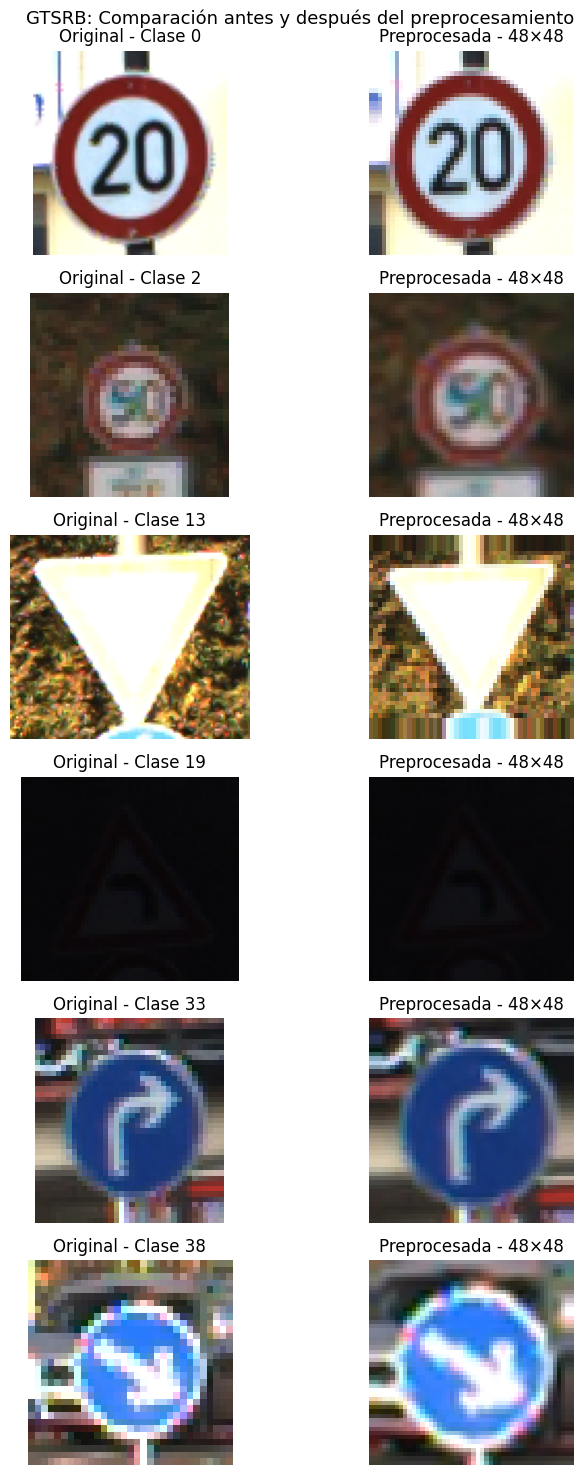

In [11]:

# PASO 10: Vista previa del preprocesamiento GTSRB

import cv2
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("/content/GTSRB-Preprocesamiento")
TAMANO = 48
MARGEN = 0.10

def preprocesar_imagen(imagen, registro):
    alto, ancho = imagen.shape[:2]

    x1 = int(registro["Roi.X1"])
    y1 = int(registro["Roi.Y1"])
    x2 = int(registro["Roi.X2"])
    y2 = int(registro["Roi.Y2"])

    # Recorte ROI con margen del 10 %
    mx = round((x2 - x1 + 1) * MARGEN)
    my = round((y2 - y1 + 1) * MARGEN)

    xi = max(0, x1 - mx)
    yi = max(0, y1 - my)
    xf = min(ancho, x2 + mx + 1)
    yf = min(alto, y2 + my + 1)

    roi = imagen[yi:yf, xi:xf]
    if roi.size == 0:
        raise ValueError("ROI vacía")

    # Redimensionar conservando proporciones
    h, w = roi.shape[:2]
    escala = min(TAMANO / w, TAMANO / h)

    nw = min(TAMANO, max(1, round(w * escala)))
    nh = min(TAMANO, max(1, round(h * escala)))

    interpolacion = (
        cv2.INTER_AREA if escala < 1
        else cv2.INTER_CUBIC
    )

    resultado = cv2.resize(
        roi, (nw, nh), interpolation=interpolacion
    )

    # Relleno centrado mediante replicación
    dx, dy = TAMANO - nw, TAMANO - nh
    izquierda, arriba = dx // 2, dy // 2

    resultado = cv2.copyMakeBorder(
        resultado,
        arriba, dy - arriba,
        izquierda, dx - izquierda,
        cv2.BORDER_REPLICATE
    )

    assert resultado.shape == (48, 48, 3)
    return resultado


# Seleccionar seis clases diferentes
clases = [0, 2, 13, 19, 33, 38]

fig, axes = plt.subplots(6, 2, figsize=(8, 15))

for i, clase in enumerate(clases):
    registro = train_split[
        train_split["ClassId"] == clase
    ].sample(1, random_state=42).iloc[0]

    imagen = cv2.imread(
        str(ROOT / registro["RutaRelativa"])
    )
    assert imagen is not None

    procesada = preprocesar_imagen(imagen, registro)

    # Convertir BGR a RGB solo para visualizar
    original_rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)
    procesada_rgb = cv2.cvtColor(procesada, cv2.COLOR_BGR2RGB)

    axes[i, 0].imshow(original_rgb)
    axes[i, 0].set_title(f"Original - Clase {clase}")

    axes[i, 1].imshow(procesada_rgb)
    axes[i, 1].set_title(f"Preprocesada - 48×48")

    for ax in axes[i]:
        ax.axis("off")

plt.suptitle(
    "GTSRB: Comparación antes y después del preprocesamiento",
    fontsize=13
)
plt.tight_layout()
plt.show()


### Interpretación del Paso 10: Evaluación visual del preprocesamiento

Las seis imágenes evaluadas conservaron su estructura, orientación y características visuales principales después del preprocesamiento a 48×48 píxeles. Se identificaron variaciones de iluminación y desenfoque procedentes de las imágenes originales, las cuales deberán considerarse durante el entrenamiento y evaluación de los modelos.

In [12]:

# PASO 11: Generación del dataset preprocesado GTSRB
# Conserva las particiones y etiquetas originales.

from pathlib import Path
from tqdm.auto import tqdm
import pandas as pd
import numpy as np
import cv2
import json

ROOT = Path("/content/GTSRB-Preprocesamiento")
SALIDA = ROOT / "data" / "processed"
SALIDA.mkdir(parents=True, exist_ok=True)

# Configuración del preprocesamiento
CONFIG = {
    "tamano": 48,
    "margen_roi": 0.10,
    "interpolacion_reduccion": "INTER_AREA",
    "interpolacion_ampliacion": "INTER_CUBIC",
    "relleno": "BORDER_REPLICATE",
    "formato": "PNG",
    "canales": 3
}

# Evitar reutilizar imágenes de otra configuración
archivo_config = SALIDA / "preprocessing_config.json"
archivos_previos = list(SALIDA.glob("*/*/*.png"))

if archivo_config.exists():
    anterior = json.loads(
        archivo_config.read_text(encoding="utf-8")
    )
    if anterior != CONFIG:
        raise RuntimeError(
            "La configuración ha cambiado. "
            "Revisar data/processed antes de continuar."
        )
elif archivos_previos:
    raise RuntimeError(
        "Existen imágenes sin configuración registrada."
    )
else:
    archivo_config.write_text(
        json.dumps(CONFIG, indent=2),
        encoding="utf-8"
    )

# Cargar particiones guardadas en GitHub
df_train = pd.read_csv(ROOT / "data/splits/train.csv")
df_val = pd.read_csv(ROOT / "data/splits/val.csv")

# Cargar anotaciones oficiales de prueba
csv_test = list(
    (ROOT / "data/extracted/test_gt")
    .rglob("GT-final_test.csv")
)

assert len(csv_test) == 1

df_test = pd.read_csv(csv_test[0], sep=";")

# Vincular imágenes originales con anotaciones de test
imagenes_test = list(
    (ROOT / "data/extracted/test").rglob("*.ppm")
)

mapa_test = {p.name: p for p in imagenes_test}

assert len(mapa_test) == 12630

df_test["RutaRelativa"] = df_test["Filename"].map(
    lambda nombre: (
        mapa_test[nombre].relative_to(ROOT).as_posix()
        if nombre in mapa_test else None
    )
)

assert df_test["RutaRelativa"].notna().all()

# Verificar cantidades antes del procesamiento
assert len(df_train) == 30869
assert len(df_val) == 8340
assert len(df_test) == 12630

# Utilizar la función validada en el Paso 10
assert callable(preprocesar_imagen)


def procesar_conjunto(df, conjunto):
    registros = []
    nuevas = 0
    reutilizadas = 0

    for r in tqdm(
        df.to_dict("records"),
        desc=f"Procesando {conjunto}"
    ):
        clase = int(r["ClassId"])
        origen = ROOT / r["RutaRelativa"]

        carpeta = SALIDA / conjunto / f"{clase:02d}"
        carpeta.mkdir(parents=True, exist_ok=True)

        destino = carpeta / f"{origen.stem}.png"

        if destino.exists():
            # Comprobar antes de reutilizar
            imagen_previa = cv2.imread(str(destino))

            if (imagen_previa is not None
                    and imagen_previa.shape == (48, 48, 3)
                    and imagen_previa.dtype == np.uint8):
                reutilizadas += 1
            else:
                destino.unlink()

        if not destino.exists():
            imagen = cv2.imread(str(origen))

            if imagen is None:
                raise ValueError(f"Error de lectura: {origen}")

            resultado = preprocesar_imagen(imagen, r)

            assert resultado.shape == (48, 48, 3)
            assert resultado.dtype == np.uint8

            # Escritura segura mediante archivo temporal
            temporal = destino.with_suffix(".tmp.png")

            correcto = cv2.imwrite(
                str(temporal),
                resultado,
                [cv2.IMWRITE_PNG_COMPRESSION, 3]
            )

            if not correcto:
                raise IOError(f"No se pudo guardar: {temporal}")

            temporal.replace(destino)
            nuevas += 1

        registros.append({
            "Conjunto": conjunto,
            "RutaOriginal": r["RutaRelativa"],
            "RutaProcesada": destino.relative_to(ROOT).as_posix(),
            "ClassId": clase
        })

    manifiesto = pd.DataFrame(registros)

    manifiesto.to_csv(
        SALIDA / f"{conjunto}_manifest.csv",
        index=False
    )

    return {
        "Conjunto": conjunto,
        "Imágenes": len(manifiesto),
        "Nuevas": nuevas,
        "Reutilizadas": reutilizadas,
        "Clases": manifiesto["ClassId"].nunique()
    }


# Procesar las tres particiones
resumen = pd.DataFrame([
    procesar_conjunto(df_train, "train"),
    procesar_conjunto(df_val, "val"),
    procesar_conjunto(df_test, "test")
])

print("\nRESUMEN DEL PREPROCESAMIENTO")
display(resumen)

assert resumen["Imágenes"].sum() == 51839
assert (resumen["Clases"] == 43).all()


Procesando train:   0%|          | 0/30869 [00:00<?, ?it/s]

Procesando val:   0%|          | 0/8340 [00:00<?, ?it/s]

Procesando test:   0%|          | 0/12630 [00:00<?, ?it/s]


RESUMEN DEL PREPROCESAMIENTO


,Conjunto,Imágenes,Nuevas,Reutilizadas,Clases
0,train,30869,30869,0,43
1,val,8340,8340,0,43
2,test,12630,12630,0,43


### Interpretación del Paso 11: Preprocesamiento del dataset

Se preprocesaron satisfactoriamente las 51 839 imágenes de GTSRB: 30 869 de entrenamiento, 8 340 de validación y 12 630 de prueba. Se aplicó recorte ROI, redimensionamiento a 48×48 píxeles y conservación de proporciones, manteniendo las 43 clases originales.

In [13]:

# PASO 12: Validación exhaustiva del dataset procesado

from pathlib import Path
from tqdm.auto import tqdm
import pandas as pd
import numpy as np
import cv2

ROOT = Path("/content/GTSRB-Preprocesamiento")
PROCESSED = ROOT / "data" / "processed"

esperados = {
    "train": 30869,
    "val": 8340,
    "test": 12630
}

resultados = []
rutas_globales = set()

for conjunto, cantidad_esperada in esperados.items():

    manifiesto = pd.read_csv(
        PROCESSED / f"{conjunto}_manifest.csv"
    )

    errores_lectura = 0
    errores_formato = 0
    errores_etiqueta = 0
    rutas_repetidas = 0

    for registro in tqdm(
        manifiesto.itertuples(index=False),
        total=len(manifiesto),
        desc=f"Validando {conjunto}"
    ):
        ruta_relativa = registro.RutaProcesada
        clase = int(registro.ClassId)

        # Verificar que no existan rutas repetidas
        if ruta_relativa in rutas_globales:
            rutas_repetidas += 1

        rutas_globales.add(ruta_relativa)

        # Verificar etiqueta y carpeta de clase
        ruta = ROOT / ruta_relativa

        if (
            clase not in range(43)
            or ruta.parent.name != f"{clase:02d}"
        ):
            errores_etiqueta += 1

        # Decodificar completamente la imagen
        imagen = cv2.imread(
            str(ruta),
            cv2.IMREAD_UNCHANGED
        )

        if imagen is None:
            errores_lectura += 1
            continue

        # Verificar dimensiones, canales y tipo de dato
        if (
            imagen.shape != (48, 48, 3)
            or imagen.dtype != np.uint8
        ):
            errores_formato += 1

    # Comparar cantidad de archivos con el manifiesto
    archivos_png = list(
        (PROCESSED / conjunto).rglob("*.png")
    )

    resultados.append({
        "Conjunto": conjunto,
        "Esperadas": cantidad_esperada,
        "Manifiesto": len(manifiesto),
        "PNG encontrados": len(archivos_png),
        "Errores lectura": errores_lectura,
        "Errores formato": errores_formato,
        "Errores etiqueta": errores_etiqueta,
        "Rutas repetidas": rutas_repetidas
    })

resumen_validacion = pd.DataFrame(resultados)

print("VALIDACIÓN EXHAUSTIVA DEL DATASET")
display(resumen_validacion)

# Comprobaciones finales
assert (
    resumen_validacion["Esperadas"]
    == resumen_validacion["Manifiesto"]
).all()

assert (
    resumen_validacion["Esperadas"]
    == resumen_validacion["PNG encontrados"]
).all()

columnas_errores = [
    "Errores lectura",
    "Errores formato",
    "Errores etiqueta",
    "Rutas repetidas"
]

assert (
    resumen_validacion[columnas_errores].sum().sum()
    == 0
), "Se detectaron inconsistencias en el dataset"


Validando train:   0%|          | 0/30869 [00:00<?, ?it/s]

Validando val:   0%|          | 0/8340 [00:00<?, ?it/s]

Validando test:   0%|          | 0/12630 [00:00<?, ?it/s]

VALIDACIÓN EXHAUSTIVA DEL DATASET


,Conjunto,Esperadas,Manifiesto,PNG encontrados,Errores lectura,Errores formato,Errores etiqueta,Rutas repetidas
0,train,30869,30869,30869,0,0,0,0
1,val,8340,8340,8340,0,0,0,0
2,test,12630,12630,12630,0,0,0,0


### Interpretación del Paso 12: Validación del dataset preprocesado

Se validaron exhaustivamente las 51 839 imágenes preprocesadas, sin detectar errores de lectura, dimensiones, formato, etiquetas ni rutas duplicadas. Los resultados confirman la integridad estructural del dataset para continuar con el análisis y entrenamiento.

In [14]:

# PASO 13: Análisis de brillo, contraste y nitidez
# del dataset GTSRB preprocesado.

from pathlib import Path
from tqdm.auto import tqdm
import pandas as pd
import numpy as np
import cv2

# Directorios principales del proyecto
ROOT = Path("/content/GTSRB-Preprocesamiento")
PROCESSED = ROOT / "data" / "processed"


def calcular_metricas(imagen):
    """
    Calcula tres características de una imagen en gris:
    brillo promedio, contraste y nitidez estimada.
    """

    # Intensidad promedio de los píxeles.
    brillo = float(np.mean(imagen))

    # Desviación estándar de las intensidades.
    # Valores pequeños pueden indicar bajo contraste.
    contraste = float(np.std(imagen))

    # Varianza del Laplaciano como medida aproximada
    # del contenido de altas frecuencias de la imagen.
    laplaciano = cv2.Laplacian(
        imagen, cv2.CV_64F
    )
    nitidez = float(laplaciano.var())

    return brillo, contraste, nitidez


# Recorrer únicamente entrenamiento y validación.
resultados = []

for conjunto in ["train", "val"]:

    manifiesto = pd.read_csv(
        PROCESSED / f"{conjunto}_manifest.csv"
    )

    for registro in tqdm(
        manifiesto.itertuples(index=False),
        total=len(manifiesto),
        desc=f"Analizando {conjunto}"
    ):

        # Leer la imagen procesada en escala de grises.
        ruta = ROOT / registro.RutaProcesada
        imagen = cv2.imread(
            str(ruta), cv2.IMREAD_GRAYSCALE
        )

        if imagen is None:
            raise RuntimeError(f"Error de lectura: {ruta}")

        # Calcular las tres métricas.
        brillo, contraste, nitidez = calcular_metricas(
            imagen
        )

        resultados.append({
            "Conjunto": conjunto,
            "ClassId": int(registro.ClassId),
            "Brillo": brillo,
            "Contraste": contraste,
            "Nitidez": nitidez
        })


# Crear un DataFrame con los resultados individuales.
metricas_df = pd.DataFrame(resultados)

# Resumir las distribuciones por conjunto.
resumen_calidad = (
    metricas_df
    .groupby("Conjunto")
    .agg(
        Imagenes=("Brillo", "size"),
        Brillo_medio=("Brillo", "mean"),
        Brillo_mediano=("Brillo", "median"),
        Contraste_medio=("Contraste", "mean"),
        Nitidez_mediana=("Nitidez", "median")
    )
    .round(2)
)

print("RESUMEN DE CALIDAD DEL DATASET")
display(resumen_calidad)


# Analizar las clases con menor brillo mediano
# utilizando únicamente las imágenes de entrenamiento.
calidad_por_clase = (
    metricas_df[metricas_df["Conjunto"] == "train"]
    .groupby("ClassId")
    .agg(
        Imagenes=("Brillo", "size"),
        Brillo_mediano=("Brillo", "median"),
        Contraste_mediano=("Contraste", "median"),
        Nitidez_mediana=("Nitidez", "median")
    )
    .round(2)
)

print("\nCINCO CLASES CON MENOR BRILLO MEDIANO")
display(
    calidad_por_clase
    .sort_values("Brillo_mediano")
    .head(5)
)


Analizando train:   0%|          | 0/30869 [00:00<?, ?it/s]

Analizando val:   0%|          | 0/8340 [00:00<?, ?it/s]

RESUMEN DE CALIDAD DEL DATASET


,Imagenes,Brillo_medio,Brillo_mediano,Contraste_medio,Nitidez_mediana
Conjunto,,,,,
train,30869,81.33,74.39,40.98,387.62
val,8340,83.96,77.52,41.91,438.62



CINCO CLASES CON MENOR BRILLO MEDIANO


,Imagenes,Brillo_mediano,Contraste_mediano,Nitidez_mediana
ClassId,,,,
8,1110,35.34,18.71,96.82
10,1590,37.42,18.84,72.44
42,180,41.19,18.99,72.97
6,330,41.57,17.84,72.04
26,480,46.72,26.25,212.69


### Interpretación del Paso 13: Análisis de calidad visual

El análisis de 39 209 imágenes evidenció diferencias moderadas de brillo y contraste entre entrenamiento y validación. Se identificaron clases con baja iluminación y nitidez, lo que justifica evaluar técnicas de aumento de datos orientadas a mejorar la robustez de los modelos.

PERCENTILES DE CALIDAD EN ENTRENAMIENTO


,P5,Mediana,P95
Brillo,18.75,74.39,170.50
Contraste,7.60,38.54,81.31
Nitidez,18.84,387.62,3501.31


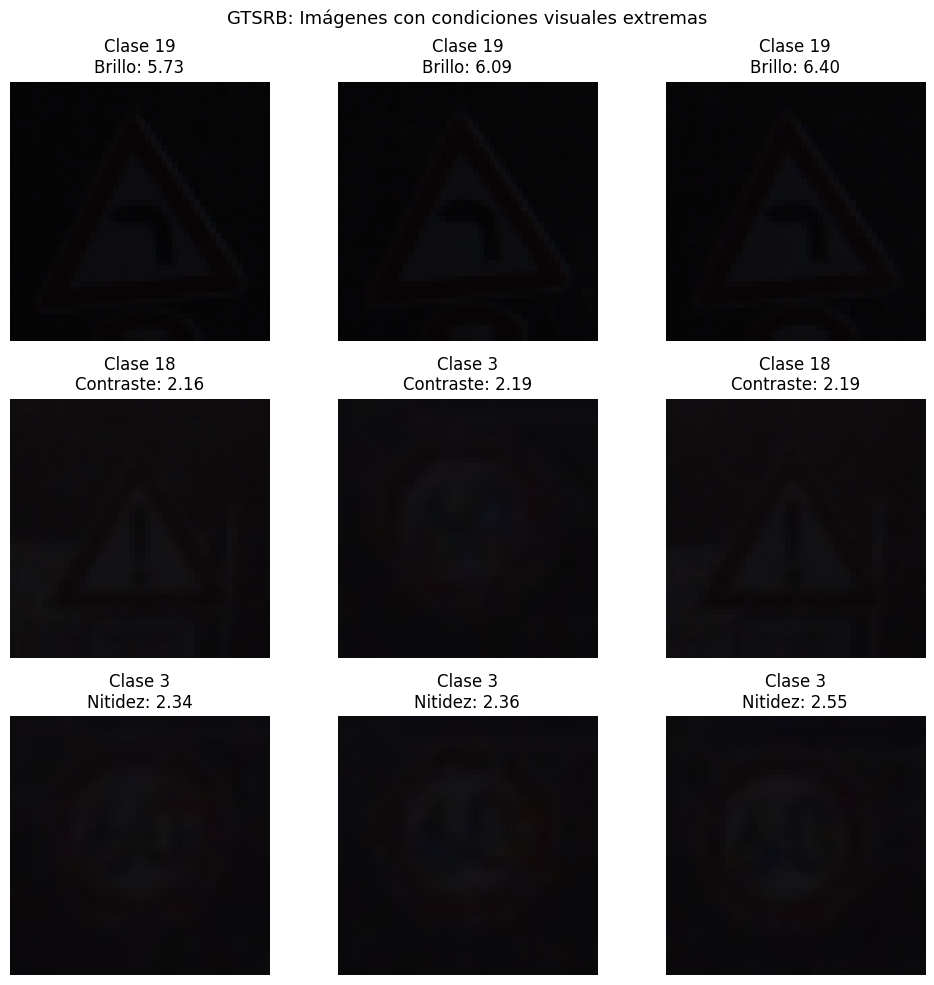

In [15]:

# PASO 14: Inspección de imágenes con baja calidad visual

from pathlib import Path
import pandas as pd
import cv2
import matplotlib.pyplot as plt

ROOT = Path("/content/GTSRB-Preprocesamiento")
PROCESSED = ROOT / "data" / "processed"

# 1. Recuperar las rutas originales de los manifiestos.
# El orden coincide con el utilizado en el Paso 13.
metadatos = pd.concat(
    [
        pd.read_csv(
            PROCESSED / f"{conjunto}_manifest.csv"
        ).assign(Conjunto=conjunto)
        for conjunto in ["train", "val"]
    ],
    ignore_index=True
)

# 2. Verificar que los registros coincidan antes
# de relacionar las métricas con las rutas.
assert len(metadatos) == len(metricas_df)

assert (
    metadatos["ClassId"].to_numpy()
    == metricas_df["ClassId"].to_numpy()
).all()

assert (
    metadatos["Conjunto"].to_numpy()
    == metricas_df["Conjunto"].to_numpy()
).all()

# 3. Incorporar las rutas a las métricas calculadas.
calidad = metricas_df.copy().reset_index(drop=True)

calidad["RutaProcesada"] = (
    metadatos["RutaProcesada"].to_numpy()
)

# 4. Trabajar solamente con entrenamiento.
train_calidad = calidad[
    calidad["Conjunto"] == "train"
].copy()

# 5. Calcular los percentiles de cada métrica.
# Los percentiles permiten examinar las distribuciones
# sin establecer umbrales arbitrarios.
metricas = ["Brillo", "Contraste", "Nitidez"]

percentiles = train_calidad[metricas].quantile(
    [0.05, 0.50, 0.95]
).T

percentiles.columns = ["P5", "Mediana", "P95"]

print("PERCENTILES DE CALIDAD EN ENTRENAMIENTO")
display(percentiles.round(2))

# 6. Seleccionar tres ejemplos extremos por métrica.
# Evitamos repetir una misma imagen en la figura.
seleccionadas = []
rutas_usadas = set()

for metrica in metricas:
    contador = 0

    for _, registro in train_calidad.sort_values(
        metrica
    ).iterrows():

        ruta = registro["RutaProcesada"]

        if ruta in rutas_usadas:
            continue

        seleccionadas.append((metrica, registro))
        rutas_usadas.add(ruta)
        contador += 1

        if contador == 3:
            break

# 7. Visualizar las nueve imágenes seleccionadas.
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for i, (metrica, registro) in enumerate(seleccionadas):
    fila, columna = divmod(i, 3)

    ruta = ROOT / registro["RutaProcesada"]

    imagen = cv2.imread(str(ruta))
    if imagen is None:
        raise RuntimeError(f"No se pudo leer: {ruta}")

    # OpenCV carga BGR; Matplotlib requiere RGB.
    imagen_rgb = cv2.cvtColor(
        imagen, cv2.COLOR_BGR2RGB
    )

    axes[fila, columna].imshow(
        imagen_rgb,
        interpolation="nearest"
    )

    axes[fila, columna].set_title(
        f"Clase {int(registro['ClassId'])}\n"
        f"{metrica}: {registro[metrica]:.2f}"
    )

    axes[fila, columna].axis("off")

# 8. Incorporar un título general.
fig.suptitle(
    "GTSRB: Imágenes con condiciones visuales extremas",
    fontsize=13
)

plt.tight_layout()
plt.show()


### Interpretación del Paso 14: Análisis de condiciones visuales extremas

Se identificaron imágenes con iluminación muy baja, contraste reducido y escasa nitidez, principalmente en las clases 19, 18 y 3. Estos resultados evidencian condiciones visuales desafiantes que deberán considerarse al diseñar el aumento de datos y evaluar la robustez de los modelos.

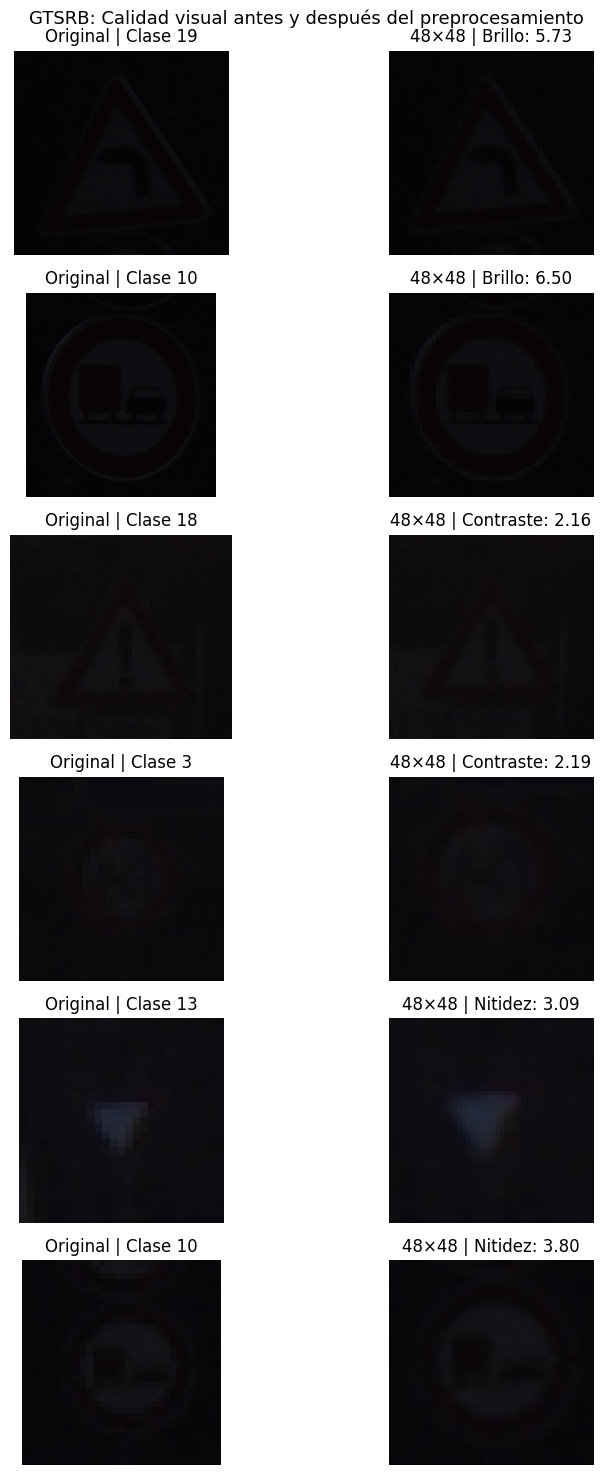

In [16]:

# PASO 15: Comparación de imágenes originales y procesadas
# con condiciones visuales extremas.

from pathlib import Path
import pandas as pd
import cv2
import matplotlib.pyplot as plt

# 1. Definir rutas del proyecto.
ROOT = Path("/content/GTSRB-Preprocesamiento")
PROCESSED = ROOT / "data" / "processed"

# 2. Cargar el manifiesto de entrenamiento.
manifest = pd.read_csv(
    PROCESSED / "train_manifest.csv"
)

# 3. Recuperar las métricas calculadas en el Paso 13.
# Se verifica que los registros conserven el mismo orden.
metricas_train = (
    metricas_df[metricas_df["Conjunto"] == "train"]
    .reset_index(drop=True)
)

assert len(manifest) == len(metricas_train)

assert (
    manifest["ClassId"].to_numpy()
    == metricas_train["ClassId"].to_numpy()
).all()

# 4. Unir rutas, métricas e identificadores de grupo.
datos = manifest.copy()

for metrica in ["Brillo", "Contraste", "Nitidez"]:
    datos[metrica] = metricas_train[metrica].to_numpy()

# Recuperar la columna Grupo del split original.
datos = datos.merge(
    train_split[["RutaRelativa", "Grupo"]],
    left_on="RutaOriginal",
    right_on="RutaRelativa",
    how="left",
    validate="one_to_one"
)

assert datos["Grupo"].notna().all()

# 5. Seleccionar dos imágenes por característica.
# Evitar grupos repetidos para mejorar la diversidad
# de ejemplos visualizados.
seleccion = []
grupos_usados = set()

for metrica in ["Brillo", "Contraste", "Nitidez"]:

    contador = 0

    for _, registro in datos.sort_values(
        metrica
    ).iterrows():

        grupo = registro["Grupo"]

        if grupo in grupos_usados:
            continue

        seleccion.append((metrica, registro))
        grupos_usados.add(grupo)

        contador += 1

        if contador == 2:
            break

assert len(seleccion) == 6

# 6. Comparar imágenes originales y procesadas.
fig, axes = plt.subplots(6, 2, figsize=(9, 15))

for i, (metrica, registro) in enumerate(seleccion):

    # Leer las dos versiones de la misma imagen.
    original = cv2.imread(
        str(ROOT / registro["RutaOriginal"])
    )

    procesada = cv2.imread(
        str(ROOT / registro["RutaProcesada"])
    )

    if original is None or procesada is None:
        raise RuntimeError("No se pudo leer una imagen")

    # Convertir BGR a RGB para Matplotlib.
    original = cv2.cvtColor(
        original, cv2.COLOR_BGR2RGB
    )

    procesada = cv2.cvtColor(
        procesada, cv2.COLOR_BGR2RGB
    )

    # Mostrar la comparación.
    axes[i, 0].imshow(original)
    axes[i, 1].imshow(procesada)

    clase = int(registro["ClassId"])
    valor = registro[metrica]

    axes[i, 0].set_title(
        f"Original | Clase {clase}"
    )

    axes[i, 1].set_title(
        f"48×48 | {metrica}: {valor:.2f}"
    )

    for ax in axes[i]:
        ax.axis("off")

fig.suptitle(
    "GTSRB: Calidad visual antes y después del preprocesamiento",
    fontsize=13
)

plt.tight_layout()
plt.show()


### Interpretación del Paso 15: Comparación de calidad visual

Las imágenes originales ya presentaban problemas de iluminación, contraste y nitidez. El preprocesamiento conservó las características principales de las señales, aunque algunas perdieron detalles por el redimensionamiento. Se recomienda evaluar aumentos de datos moderados durante el entrenamiento.

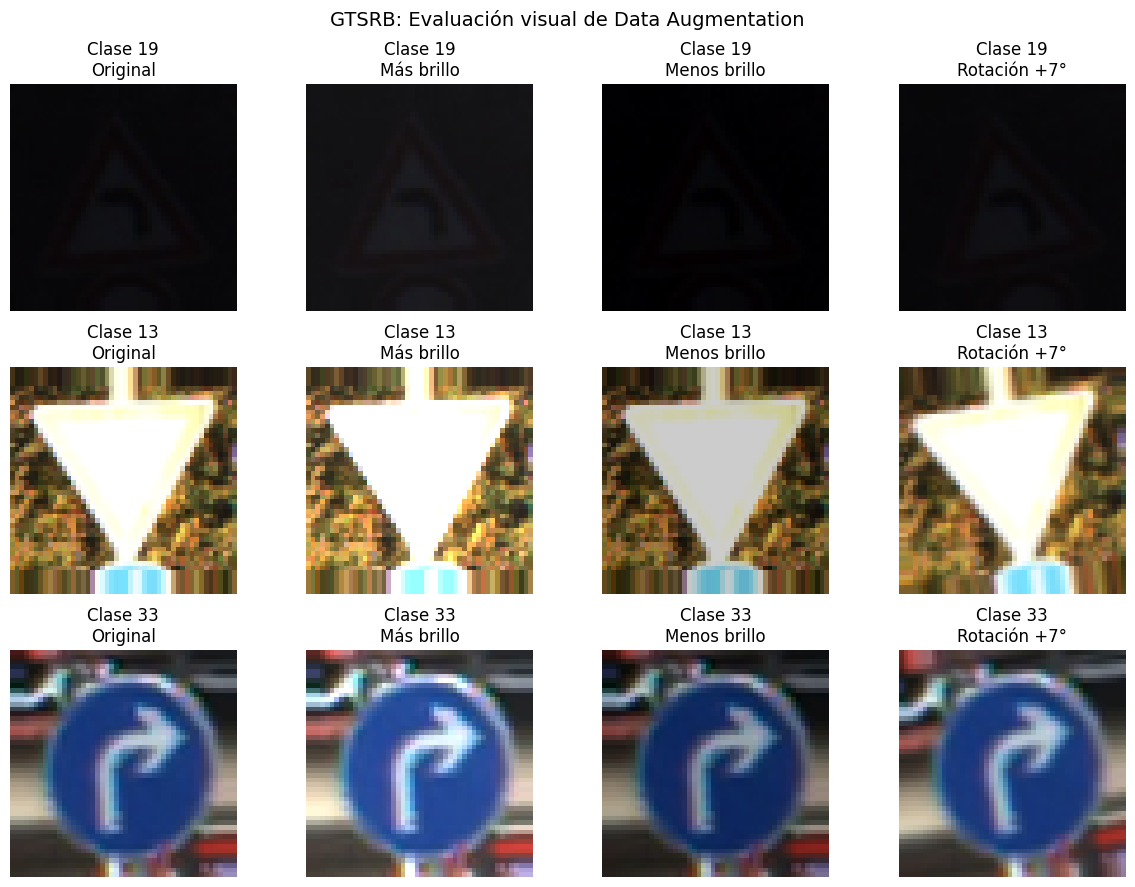

In [17]:

# PASO 16: Comparación visual de aumentos de datos
# Las transformaciones son demostrativas.
# No modifican ni sobrescriben el dataset original.

from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

ROOT = Path("/content/GTSRB-Preprocesamiento")

# Cargar exclusivamente imágenes de entrenamiento.
manifest = pd.read_csv(
    ROOT / "data/processed/train_manifest.csv"
)

# Seleccionar ejemplos de tres clases diferentes.
clases = [19, 13, 33]

def modificar_luminosidad(imagen, alpha, beta):
    """
    Ajusta contraste y brillo:
    salida = alpha * imagen + beta.

    Se utiliza float32 para evitar desbordamiento
    de los valores uint8 durante el cálculo.
    """
    resultado = imagen.astype(np.float32) * alpha + beta

    return np.clip(resultado, 0, 255).astype(np.uint8)


def rotar_imagen(imagen, angulo):
    """
    Aplica una pequeña rotación alrededor del centro.
    Replica los bordes para evitar franjas negras.
    """
    alto, ancho = imagen.shape[:2]

    matriz = cv2.getRotationMatrix2D(
        (ancho / 2, alto / 2),
        angulo,
        1.0
    )

    return cv2.warpAffine(
        imagen,
        matriz,
        (ancho, alto),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REPLICATE
    )


fig, axes = plt.subplots(
    len(clases), 4, figsize=(12, 9)
)

for fila, clase in enumerate(clases):

    # Selección reproducible de una imagen por clase.
    registro = manifest[
        manifest["ClassId"] == clase
    ].sample(1, random_state=42).iloc[0]

    ruta = ROOT / registro["RutaProcesada"]

    imagen = cv2.imread(str(ruta))

    if imagen is None:
        raise RuntimeError(f"No se pudo leer: {ruta}")

    # Generar variantes sin alterar las etiquetas.
    variantes = [
        ("Original", imagen),
        ("Más brillo", modificar_luminosidad(
            imagen, 1.18, 10
        )),
        ("Menos brillo", modificar_luminosidad(
            imagen, 0.82, -5
        )),
        ("Rotación +7°", rotar_imagen(
            imagen, 7
        ))
    ]

    for columna, (nombre, variante) in enumerate(variantes):

        # Convertir de BGR a RGB para visualización.
        rgb = cv2.cvtColor(
            variante, cv2.COLOR_BGR2RGB
        )

        axes[fila, columna].imshow(
            rgb, interpolation="nearest"
        )

        axes[fila, columna].set_title(
            f"Clase {clase}\n{nombre}"
        )
        axes[fila, columna].axis("off")

fig.suptitle(
    "GTSRB: Evaluación visual de Data Augmentation",
    fontsize=14
)

plt.tight_layout()
plt.show()


### Interpretación del Paso 16: Evaluación de Data Augmentation

Se evaluaron transformaciones de brillo, contraste y rotación sobre imágenes de GTSRB. Las señales conservaron sus características principales, aunque el aumento de brillo intensificó la sobreexposición en algunas imágenes. Se recomienda aplicar aumentos moderados únicamente durante el entrenamiento.

In [18]:

# PASO 17: Cálculo de media y desviación estándar RGB
# Los estadísticos se calculan únicamente con train.

from pathlib import Path
from tqdm.auto import tqdm
import pandas as pd
import numpy as np
import cv2

ROOT = Path("/content/GTSRB-Preprocesamiento")

# 1. Cargar el manifiesto de entrenamiento.
manifest = pd.read_csv(
    ROOT / "data/processed/train_manifest.csv"
)

# 2. Inicializar acumuladores para los tres canales RGB.
# float64 reduce errores numéricos acumulativos.
suma = np.zeros(3, dtype=np.float64)
suma_cuadrados = np.zeros(3, dtype=np.float64)
total_pixeles = 0

# 3. Recorrer todas las imágenes de entrenamiento.
for registro in tqdm(
    manifest.itertuples(index=False),
    total=len(manifest),
    desc="Calculando estadísticas RGB"
):

    ruta = ROOT / registro.RutaProcesada

    # OpenCV carga las imágenes en BGR.
    imagen = cv2.imread(str(ruta))

    if imagen is None:
        raise RuntimeError(f"No se pudo leer: {ruta}")

    # Convertir BGR a RGB.
    imagen = cv2.cvtColor(
        imagen, cv2.COLOR_BGR2RGB
    )

    # Escalar intensidades de [0,255] a [0,1].
    imagen = imagen.astype(np.float64) / 255.0

    # Acumular suma y suma de cuadrados por canal.
    suma += imagen.sum(axis=(0, 1))
    suma_cuadrados += np.square(imagen).sum(axis=(0, 1))

    # Contabilizar píxeles, sin multiplicar por canales.
    total_pixeles += imagen.shape[0] * imagen.shape[1]

# 4. Calcular media y desviación estándar poblacional.
media = suma / total_pixeles

varianza = (
    suma_cuadrados / total_pixeles
    - np.square(media)
)

desviacion = np.sqrt(np.maximum(varianza, 0))

# 5. Presentar los resultados.
estadisticas_rgb = pd.DataFrame({
    "Canal": ["Rojo", "Verde", "Azul"],
    "Media": media,
    "Desviación estándar": desviacion
})

print("ESTADÍSTICAS RGB DEL CONJUNTO DE ENTRENAMIENTO")
display(estadisticas_rgb.round(6))

print("\nImágenes analizadas:", len(manifest))
print("Media RGB:", np.round(media, 6).tolist())
print("Std RGB:", np.round(desviacion, 6).tolist())

# 6. Comprobar que los resultados sean válidos.
assert len(manifest) == 30869
assert np.isfinite(media).all()
assert np.isfinite(desviacion).all()
assert (desviacion > 0).all()


Calculando estadísticas RGB:   0%|          | 0/30869 [00:00<?, ?it/s]

ESTADÍSTICAS RGB DEL CONJUNTO DE ENTRENAMIENTO


,Canal,Media,Desviación estándar
0,Rojo,0.339805,0.273966
1,Verde,0.310865,0.263290
2,Azul,0.322538,0.271450



Imágenes analizadas: 30869
Media RGB: [0.339805, 0.310865, 0.322538]
Std RGB: [0.273966, 0.26329, 0.27145]


### Interpretación del Paso 17: Normalización RGB

Se calcularon la media y desviación estándar de los canales RGB utilizando las 30 869 imágenes de entrenamiento. Los resultados permiten establecer una normalización por canal sin utilizar información de validación o prueba, evitando fugas de datos.

In [19]:

# PASO 18: Construcción de Dataset y DataLoader
# para clasificación GTSRB con PyTorch.

from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image

# 1. Directorio principal del proyecto.
ROOT = Path("/content/GTSRB-Preprocesamiento")

# 2. Estadísticas calculadas exclusivamente
# sobre entrenamiento en el Paso 17.
MEAN = np.array(
    [0.339805, 0.310865, 0.322538],
    dtype=np.float32
)

STD = np.array(
    [0.273966, 0.263290, 0.271450],
    dtype=np.float32
)

# 3. Definir un Dataset personalizado.
class GTSRBDataset(Dataset):
    """
    Carga imágenes RGB de 48x48 píxeles.

    Aplica:
    - Conversión a float32.
    - Escalado de [0,255] a [0,1].
    - Normalización por canal RGB.
    - Conversión a tensor (C,H,W).
    """

    def __init__(self, manifest_path, transform=None):
        self.df = pd.read_csv(manifest_path)

        # Transformaciones opcionales para entrenamiento.
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        # Recuperar ruta y etiqueta.
        registro = self.df.iloc[idx]
        ruta = ROOT / registro["RutaProcesada"]
        etiqueta = int(registro["ClassId"])

        # PIL garantiza que trabajamos en orden RGB.
        with Image.open(ruta) as img:
            imagen = img.convert("RGB")

            # Reservado para aumentos dinámicos.
            if self.transform is not None:
                imagen = self.transform(imagen)

            # Convertir a matriz float32.
            imagen = np.asarray(
                imagen, dtype=np.float32
            ) / 255.0

        # Aplicar normalización usando train.
        imagen = (imagen - MEAN) / STD

        # Convertir (H,W,C) a (C,H,W).
        imagen = np.transpose(
            imagen, (2, 0, 1)
        ).copy()

        tensor = torch.from_numpy(imagen)

        return tensor, etiqueta


# 4. Crear los tres conjuntos independientes.
train_dataset = GTSRBDataset(
    ROOT / "data/processed/train_manifest.csv"
)

val_dataset = GTSRBDataset(
    ROOT / "data/processed/val_manifest.csv"
)

test_dataset = GTSRBDataset(
    ROOT / "data/processed/test_manifest.csv"
)

# 5. Configurar carga de lotes.
BATCH_SIZE = 64
NUM_WORKERS = 2

# Semilla para reproducir el orden inicial.
torch.manual_seed(42)
generador = torch.Generator().manual_seed(42)

# Train mezcla las imágenes en cada época.
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    generator=generador
)

# Validación y prueba mantienen orden fijo.
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

# 6. Verificar las cantidades de muestras.
print("DATASETS")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

# 7. Verificar las cantidades de lotes.
print("\nLOTES")
print("Train:", len(train_loader))
print("Validation:", len(val_loader))
print("Test:", len(test_loader))

# 8. Inspeccionar un lote de entrenamiento.
imagenes, etiquetas = next(iter(train_loader))

print("\nVERIFICACIÓN DEL LOTE")
print("Dimensiones:", imagenes.shape)
print("Tipo de dato:", imagenes.dtype)
print("Etiquetas:", etiquetas.shape)
print("Rango de clases:",
      etiquetas.min().item(),
      etiquetas.max().item())

print("Valores finitos:",
      torch.isfinite(imagenes).all().item())

# 9. Comprobaciones automáticas.
assert len(train_dataset) == 30869
assert len(val_dataset) == 8340
assert len(test_dataset) == 12630

assert imagenes.shape == (64, 3, 48, 48)
assert imagenes.dtype == torch.float32
assert torch.isfinite(imagenes).all()
assert etiquetas.min() >= 0
assert etiquetas.max() < 43


DATASETS
Train: 30869
Validation: 8340
Test: 12630

LOTES
Train: 483
Validation: 131
Test: 198

VERIFICACIÓN DEL LOTE
Dimensiones: torch.Size([64, 3, 48, 48])
Tipo de dato: torch.float32
Etiquetas: torch.Size([64])
Rango de clases: 1 41
Valores finitos: True


### Interpretación del Paso 18: Preparación de datos en PyTorch

Se construyeron y verificaron los Dataset y DataLoader de entrenamiento, validación y prueba. Las imágenes se cargaron correctamente como tensores normalizados de 48×48 píxeles, con tres canales RGB y lotes de 64 muestras, sin detectar errores.

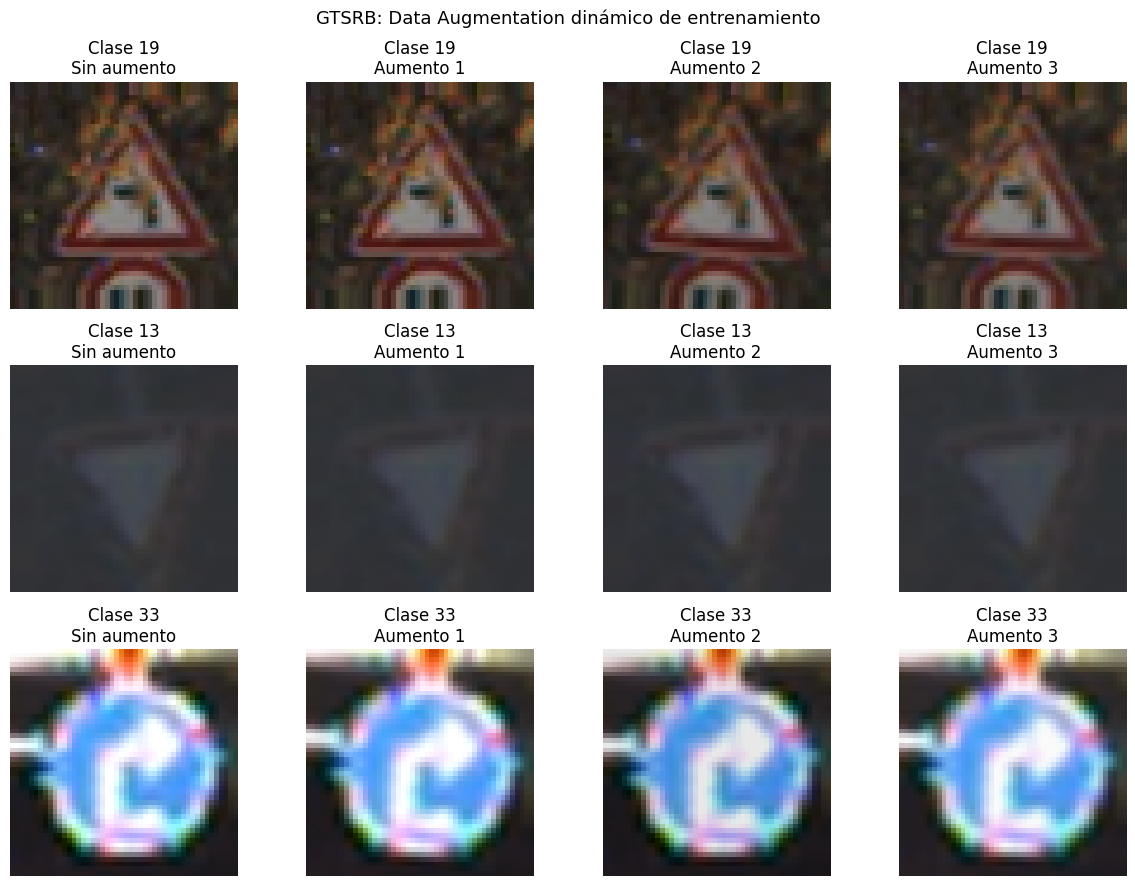

Imágenes de entrenamiento: 30869
Lotes de entrenamiento: 483
Dimensiones del lote: (64, 3, 48, 48)
Data Augmentation: solo entrenamiento


In [20]:

# PASO 19: Data Augmentation dinámico para GTSRB
# Las transformaciones se aplican al cargar imágenes.
# No se modifican los archivos almacenados.

import random
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image, ImageEnhance
from torch.utils.data import DataLoader


# 1. Definir las transformaciones de entrenamiento.
class GTSRBAugmentation:
    """
    Aplica aumentos moderados que conservan
    la semántica de las señales de tránsito.
    """

    def __call__(self, imagen):

        # Convertir la imagen RGB a NumPy.
        img = np.array(imagen)

        # Rotación aleatoria con probabilidad del 50 %.
        if random.random() < 0.5:

            angulo = random.uniform(-7, 7)

            h, w = img.shape[:2]

            matriz = cv2.getRotationMatrix2D(
                ((w - 1) / 2, (h - 1) / 2),
                angulo,
                1.0
            )

            # Replicar bordes para evitar franjas negras.
            img = cv2.warpAffine(
                img,
                matriz,
                (w, h),
                flags=cv2.INTER_LINEAR,
                borderMode=cv2.BORDER_REPLICATE
            )

        # Convertir nuevamente a PIL.
        imagen = Image.fromarray(img)

        # Variación de brillo de ±10 %.
        if random.random() < 0.5:
            factor = random.uniform(0.90, 1.10)

            imagen = ImageEnhance.Brightness(
                imagen
            ).enhance(factor)

        # Variación de contraste de ±10 %.
        if random.random() < 0.5:
            factor = random.uniform(0.90, 1.10)

            imagen = ImageEnhance.Contrast(
                imagen
            ).enhance(factor)

        return imagen


# 2. Crear el Dataset aumentado.
# Reutiliza la clase GTSRBDataset del Paso 18.
ROOT = Path("/content/GTSRB-Preprocesamiento")

train_dataset_aug = GTSRBDataset(
    ROOT / "data/processed/train_manifest.csv",
    transform=GTSRBAugmentation()
)


# 3. Actualizar únicamente el DataLoader de entrenamiento.
# Validation y test permanecen sin Data Augmentation.
train_loader = DataLoader(
    train_dataset_aug,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
    generator=torch.Generator().manual_seed(42)
)


# 4. Función para visualizar tensores normalizados.
def visualizar_tensor(tensor):
    """
    Revierte la normalización RGB únicamente
    para representar correctamente la imagen.
    """

    media = torch.tensor(MEAN).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)

    imagen = tensor.cpu() * std + media

    return imagen.clamp(0, 1).permute(1, 2, 0).numpy()


# 5. Comparar imágenes originales y aumentadas.
clases = [19, 13, 33]

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for fila, clase in enumerate(clases):

    # Seleccionar una imagen de la clase indicada.
    indice = train_dataset_aug.df.index[
        train_dataset_aug.df["ClassId"] == clase
    ][0]

    # Versión sin aumento, pero normalizada.
    original, _ = train_dataset[indice]

    axes[fila, 0].imshow(
        visualizar_tensor(original)
    )
    axes[fila, 0].set_title(
        f"Clase {clase}\nSin aumento"
    )
    axes[fila, 0].axis("off")

    # Obtener tres versiones aumentadas.
    for columna in range(1, 4):

        aumentada, etiqueta = train_dataset_aug[indice]

        axes[fila, columna].imshow(
            visualizar_tensor(aumentada)
        )

        axes[fila, columna].set_title(
            f"Clase {clase}\nAumento {columna}"
        )

        axes[fila, columna].axis("off")

        # Comprobar conservación de la etiqueta.
        assert etiqueta == clase


fig.suptitle(
    "GTSRB: Data Augmentation dinámico de entrenamiento",
    fontsize=13
)

plt.tight_layout()
plt.show()


# 6. Comprobaciones finales.
assert len(train_dataset_aug) == 30869
assert len(val_dataset) == 8340
assert len(test_dataset) == 12630

imagenes, etiquetas = next(iter(train_loader))

assert imagenes.shape == (64, 3, 48, 48)
assert torch.isfinite(imagenes).all()

print("Imágenes de entrenamiento:", len(train_dataset_aug))
print("Lotes de entrenamiento:", len(train_loader))
print("Dimensiones del lote:", tuple(imagenes.shape))
print("Data Augmentation: solo entrenamiento")


### Interpretación del Paso 19: Data Augmentation dinámico

Se implementaron aumentos dinámicos de rotación, brillo y contraste exclusivamente sobre entrenamiento. La inspección visual confirmó que las transformaciones conservan las características principales de las señales, sin modificar los archivos originales ni las etiquetas.

RESUMEN DEL DESBALANCE
Clases: 43
Clase minoritaria: 0
Frecuencia mínima: 150
Clase mayoritaria: 2
Frecuencia máxima: 1800
Razón máximo/mínimo: 12.0

CINCO CLASES MENOS REPRESENTADAS


,ClassId,Train,Validation,Train_%,Validation_%
0,0,150,60,0.486,0.719
19,19,150,60,0.486,0.719
37,37,150,60,0.486,0.719
27,27,180,60,0.583,0.719
32,32,180,60,0.583,0.719



CINCO CLASES MÁS REPRESENTADAS


,ClassId,Train,Validation,Train_%,Validation_%
2,2,1800,450,5.831,5.396
1,1,1770,450,5.734,5.396
13,13,1710,450,5.540,5.396
12,12,1680,420,5.442,5.036
38,38,1650,420,5.345,5.036



PESOS CANDIDATOS PARA CROSS-ENTROPY
Peso mínimo: 0.3988
Peso máximo: 4.7859


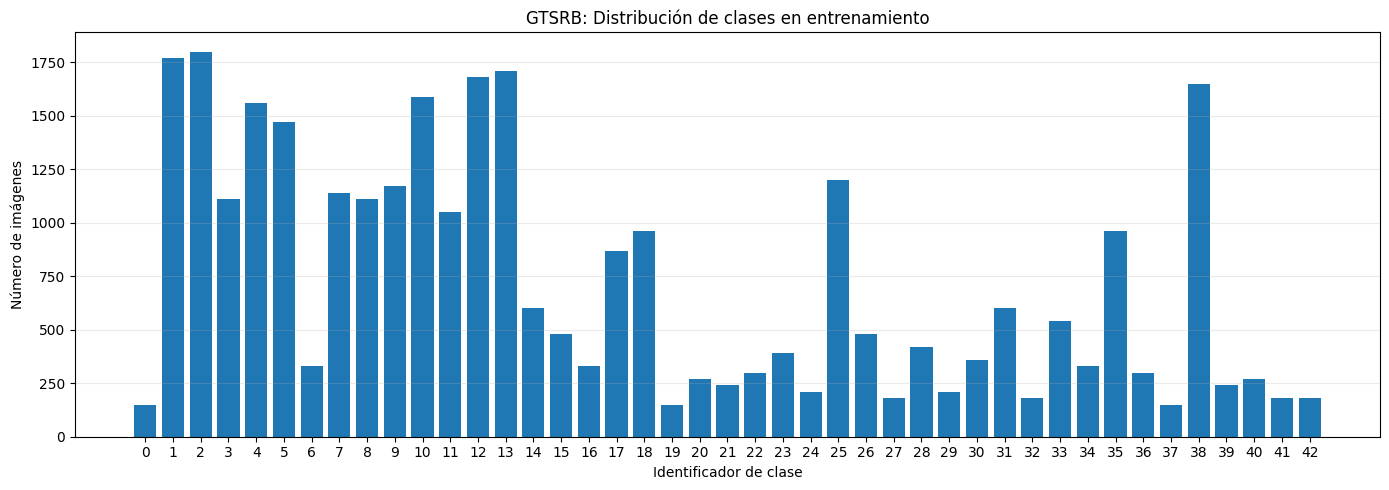

In [24]:

# PASO 20: Análisis de distribución y desbalance de clases
# Los pesos se calculan únicamente con entrenamiento.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Definir el directorio del proyecto.
ROOT = Path("/content/GTSRB-Preprocesamiento")

# 2. Cargar los manifiestos preprocesados.
train_manifest = pd.read_csv(
    ROOT / "data/processed/train_manifest.csv"
)

val_manifest = pd.read_csv(
    ROOT / "data/processed/val_manifest.csv"
)

# 3. Contabilizar imágenes por clase.
# Reindex garantiza que aparezcan las 43 categorías.
clases = np.arange(43)

conteo_train = (
    train_manifest["ClassId"]
    .value_counts()
    .reindex(clases, fill_value=0)
)

conteo_val = (
    val_manifest["ClassId"]
    .value_counts()
    .reindex(clases, fill_value=0)
)

# 4. Crear una tabla comparativa.
distribucion = pd.DataFrame({
    "ClassId": clases,
    "Train": conteo_train.to_numpy(),
    "Validation": conteo_val.to_numpy()
})

# Calcular proporciones por conjunto.
distribucion["Train_%"] = (
    distribucion["Train"] / len(train_manifest) * 100
)

distribucion["Validation_%"] = (
    distribucion["Validation"] / len(val_manifest) * 100
)

# 5. Calcular el desbalance en entrenamiento.
minimo = conteo_train.min()
maximo = conteo_train.max()
razon_desbalance = maximo / minimo

print("RESUMEN DEL DESBALANCE")
print("Clases:", len(clases))
print("Clase minoritaria:", conteo_train.idxmin())
print("Frecuencia mínima:", minimo)
print("Clase mayoritaria:", conteo_train.idxmax())
print("Frecuencia máxima:", maximo)
print("Razón máximo/mínimo:", round(razon_desbalance, 2))

# 6. Mostrar clases minoritarias y mayoritarias.
print("\nCINCO CLASES MENOS REPRESENTADAS")
display(
    distribucion.nsmallest(5, "Train").round(3)
)

print("\nCINCO CLASES MÁS REPRESENTADAS")
display(
    distribucion.nlargest(5, "Train").round(3)
)

# 7. Calcular pesos inversos a la frecuencia.
# La fórmula equilibra la contribución teórica
# de cada clase a la función de pérdida.
#
# w_c = N / (K * n_c)
#
# N: número total de imágenes de entrenamiento.
# K: número de clases.
# n_c: cantidad de imágenes en la clase c.

N = len(train_manifest)
K = len(clases)

pesos_clases = N / (K * conteo_train.to_numpy())

# Verificar que todas las clases tengan muestras.
assert (conteo_train > 0).all()
assert (conteo_val > 0).all()
assert np.isfinite(pesos_clases).all()

print("\nPESOS CANDIDATOS PARA CROSS-ENTROPY")
print("Peso mínimo:", round(pesos_clases.min(), 4))
print("Peso máximo:", round(pesos_clases.max(), 4))

# 8. Visualizar la distribución de entrenamiento.
fig, ax = plt.subplots(figsize=(14, 5))

ax.bar(
    distribucion["ClassId"],
    distribucion["Train"]
)

ax.set_title(
    "GTSRB: Distribución de clases en entrenamiento"
)
ax.set_xlabel("Identificador de clase")
ax.set_ylabel("Número de imágenes")
ax.set_xticks(clases)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


### Interpretación del Paso 20: Desbalance de clases

Se identificó un desbalance de 12:1 entre las clases mayoritarias y minoritarias, con frecuencias de 150 a 1 800 imágenes. Se calcularon pesos candidatos para compensar esta diferencia, aunque inicialmente se utilizará entropía cruzada estándar y métricas macro para comparar los tres modelos.

In [26]:
# PASO 21: Configuración del entorno de entrenamiento
# y control básico de reproducibilidad.

# Corregir error de compatibilidad entre Pillow y torchvision instalando versiones compatibles
import subprocess
import sys

try:
    import torchvision
except ImportError:
    print("Reinstalando Pillow y torchvision para solucionar incompatibilidad...")
    subprocess.run([sys.executable, "-m", "pip", "install", "--upgrade", "Pillow", "torchvision"], check=True)
    import torchvision

import random
import platform
import numpy as np
import torch

# 1. Establecer una semilla para los generadores
# pseudoaleatorios utilizados en el experimento.
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# 2. Configurar CUDA cuando exista una GPU.
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# 3. Configurar cuDNN para favorecer
# resultados reproducibles.
# Algunas operaciones pueden seguir siendo
# no deterministas dependiendo del hardware.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# 4. Seleccionar el dispositivo de ejecución.
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 5. Mostrar versiones del entorno.
print("ENTORNO DE ENTRENAMIENTO")
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Dispositivo:", DEVICE)
print("Semilla:", SEED)

# 6. Obtener información de GPU, si existe.
if DEVICE.type == "cuda":
    propiedades = torch.cuda.get_device_properties(0)
    print("\nINFORMACIÓN DE GPU")
    print("Nombre:", propiedades.name)
    print(
        "Memoria total (GB):",
        round(propiedades.total_memory / 1024**3, 2)
    )
else:
    print("\nGPU no disponible. Se utilizará CPU.")

# 7. Verificar que un tensor pueda procesarse
# en el dispositivo seleccionado.
tensor = torch.randn(
    4, 3, 48, 48,
    device=DEVICE
)

print("\nVERIFICACIÓN")
print("Tensor:", tuple(tensor.shape))
print("Ubicación:", tensor.device)
print("Valores finitos:", torch.isfinite(tensor).all().item())

Reinstalando Pillow y torchvision para solucionar incompatibilidad...
ENTORNO DE ENTRENAMIENTO
Python: 3.13.16
PyTorch: 2.14.1+cu130
Torchvision: 0.29.2+cu132
Dispositivo: cuda
Semilla: 42

INFORMACIÓN DE GPU
Nombre: Tesla T4
Memoria total (GB): 14.56

VERIFICACIÓN
Tensor: (4, 3, 48, 48)
Ubicación: cuda:0
Valores finitos: True


### Interpretación del Paso 21: Configuración del entorno

Se verificó la disponibilidad de una GPU NVIDIA Tesla T4 con 14.56 GB de memoria y soporte CUDA. Se configuró la semilla 42 para favorecer la reproducibilidad de los experimentos y se comprobó correctamente la ejecución de tensores en GPU.

In [27]:

# PASO 22: Comprobar que los datos y las variables
# siguen disponibles después de activar la GPU.

from pathlib import Path
import pandas as pd

ROOT = Path("/content/GTSRB-Preprocesamiento")

# 1. Verificar los archivos esenciales del proyecto.
archivos = {
    "Repositorio": ROOT / "README.md",
    "Train manifest": ROOT / "data/processed/train_manifest.csv",
    "Val manifest": ROOT / "data/processed/val_manifest.csv",
    "Test manifest": ROOT / "data/processed/test_manifest.csv",
    "Configuración": ROOT / "data/processed/preprocessing_config.json"
}

print("ARCHIVOS DEL PROYECTO")

for nombre, ruta in archivos.items():
    estado = "OK" if ruta.is_file() else "NO DISPONIBLE"
    print(f"{nombre}: {estado}")

# 2. Comprobar cantidad de registros por conjunto.
print("\nIMÁGENES PREPROCESADAS")

for conjunto in ["train", "val", "test"]:
    ruta = ROOT / "data/processed" / f"{conjunto}_manifest.csv"

    if ruta.is_file():
        df = pd.read_csv(ruta)
        print(f"{conjunto}: {len(df)} registros")
    else:
        print(f"{conjunto}: no disponible")

# 3. Verificar las variables necesarias para entrenar.
variables = [
    "GTSRBDataset",
    "GTSRBAugmentation",
    "train_loader",
    "val_loader",
    "test_loader",
    "MEAN",
    "STD"
]

print("\nVARIABLES EN MEMORIA")

for nombre in variables:
    estado = "OK" if nombre in globals() else "NO DISPONIBLE"
    print(f"{nombre}: {estado}")


ARCHIVOS DEL PROYECTO
Repositorio: OK
Train manifest: OK
Val manifest: OK
Test manifest: OK
Configuración: OK

IMÁGENES PREPROCESADAS
train: 30869 registros
val: 8340 registros
test: 12630 registros

VARIABLES EN MEMORIA
GTSRBDataset: OK
GTSRBAugmentation: OK
train_loader: OK
val_loader: OK
test_loader: OK
MEAN: OK
STD: OK


### Interpretación del Paso 22: Verificación del entorno

Se recuperó satisfactoriamente el entorno de Google Colab con GPU, verificando los 51 839 registros preprocesados y la disponibilidad de los Dataset, DataLoader y parámetros de normalización. El proyecto está preparado para implementar las arquitecturas de clasificación.

In [28]:

# PASO 23: Definición y verificación de arquitecturas
# CNN personalizada, ResNet18 y MobileNetV2.
# Todas clasifican las 43 categorías de GTSRB.

import torch
import torch.nn as nn
from torchvision import models

NUM_CLASSES = 43
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# 1. CNN personalizada como modelo de referencia.
class CNNPersonalizada(nn.Module):
    """
    Tres bloques convolucionales con BatchNorm,
    ReLU y MaxPooling.

    Global Average Pooling reduce la cantidad de
    parámetros de la cabeza clasificadora.
    """

    def __init__(self, num_classes=43):
        super().__init__()

        self.features = nn.Sequential(
            # Bloque 1: 48x48 -> 24x24
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Bloque 2: 24x24 -> 12x12
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Bloque 3: 12x12 -> 6x6
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Convertir cada mapa en un valor promedio.
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


# 2. ResNet18 adaptada para imágenes pequeñas.
def crear_resnet18():
    """
    Inicializar ResNet18 desde cero.

    Se modifica la primera convolución para evitar
    una reducción espacial excesiva en imágenes
    de 48x48 píxeles.
    """
    modelo = models.resnet18(weights=None)

    # Kernel 3x3 y stride 1 para preservar detalles.
    modelo.conv1 = nn.Conv2d(
        3, 64, kernel_size=3,
        stride=1, padding=1, bias=False
    )

    # Eliminar el MaxPooling inicial.
    modelo.maxpool = nn.Identity()

    # Clasificador de 43 categorías.
    modelo.fc = nn.Linear(
        modelo.fc.in_features, NUM_CLASSES
    )

    return modelo


# 3. MobileNetV2 desde cero.
def crear_mobilenetv2():
    """
    MobileNetV2 emplea bloques residuales invertidos
    y convoluciones separables para reducir costo
    computacional.
    """
    return models.mobilenet_v2(
        weights=None,
        num_classes=NUM_CLASSES
    )


# 4. Instanciar los tres modelos.
modelos = {
    "CNN personalizada": CNNPersonalizada(NUM_CLASSES),
    "ResNet18": crear_resnet18(),
    "MobileNetV2": crear_mobilenetv2()
}


# 5. Verificar parámetros y dimensiones de salida.
# No se realiza ningún entrenamiento.
entrada = torch.randn(2, 3, 48, 48, device=DEVICE)

print("VERIFICACIÓN DE ARQUITECTURAS")

for nombre, modelo in modelos.items():

    # Contabilizar parámetros entrenables.
    parametros = sum(
        p.numel() for p in modelo.parameters()
        if p.requires_grad
    )

    # Comprobar el forward pass en GPU.
    modelo = modelo.to(DEVICE)
    modelo.eval()

    with torch.inference_mode():
        salida = modelo(entrada)

    # CrossEntropyLoss espera logits de 43 clases.
    assert salida.shape == (2, NUM_CLASSES)
    assert torch.isfinite(salida).all()

    print(f"\nModelo: {nombre}")
    print(f"Parámetros: {parametros:,}")
    print(f"Parámetros (millones): {parametros / 1e6:.3f}")
    print(f"Entrada: {tuple(entrada.shape)}")
    print(f"Salida: {tuple(salida.shape)}")

    # Conservar la instancia verificada.
    modelos[nombre] = modelo

print("\nDispositivo utilizado:", DEVICE)


VERIFICACIÓN DE ARQUITECTURAS

Modelo: CNN personalizada
Parámetros: 99,243
Parámetros (millones): 0.099
Entrada: (2, 3, 48, 48)
Salida: (2, 43)

Modelo: ResNet18
Parámetros: 11,190,891
Parámetros (millones): 11.191
Entrada: (2, 3, 48, 48)
Salida: (2, 43)

Modelo: MobileNetV2
Parámetros: 2,278,955
Parámetros (millones): 2.279
Entrada: (2, 3, 48, 48)
Salida: (2, 43)

Dispositivo utilizado: cuda


### Interpretación del Paso 23: Verificación de arquitecturas

Se implementaron y verificaron tres arquitecturas: CNN personalizada, ResNet18 y MobileNetV2, con 99 243, 11 190 891 y 2 278 955 parámetros entrenables, respectivamente. Los tres modelos procesan imágenes RGB de 48×48 y generan 43 salidas, confirmando su compatibilidad con GTSRB.

In [29]:

# PASO 24: Configuración experimental y directorios
# para almacenar los modelos entrenados.

import json
import torch
from pathlib import Path
from google.colab import drive

# 1. Montar Google Drive para conservar checkpoints.
drive.mount("/content/drive")

# 2. Definir el directorio persistente.
PROYECTO_DRIVE = Path(
    "/content/drive/MyDrive/Proyecto_VC_GTSRB"
)

CHECKPOINTS = PROYECTO_DRIVE / "checkpoints"
CHECKPOINTS.mkdir(parents=True, exist_ok=True)

# 3. Establecer el protocolo común de entrenamiento.
CONFIG_TRAIN = {
    "dataset": "GTSRB",
    "num_clases": 43,
    "resolucion": [48, 48],
    "modelos": [
        "CNNPersonalizada",
        "ResNet18",
        "MobileNetV2"
    ],
    "pesos_preentrenados": False,
    "batch_size": 64,
    "max_epochs": 40,
    "learning_rate": 0.001,
    "weight_decay": 0.0001,
    "optimizador": "AdamW",
    "perdida": "CrossEntropyLoss",
    "pesos_clases": False,
    "early_stopping_patience": 7,
    "metrica_seleccion": "val_f1_macro",
    "semilla": 42,
    "normalizacion_media": MEAN.tolist(),
    "normalizacion_std": STD.tolist(),
    "data_augmentation": {
        "rotacion_grados": [-7, 7],
        "brillo": [0.90, 1.10],
        "contraste": [0.90, 1.10],
        "solo_train": True,
        "flips": False
    }
}

# 4. Guardar los hiperparámetros para reproducibilidad.
archivo_config = PROYECTO_DRIVE / "config_entrenamiento.json"

with open(archivo_config, "w", encoding="utf-8") as f:
    json.dump(CONFIG_TRAIN, f, indent=4)

# 5. Verificar el archivo y la GPU disponible.
with open(archivo_config, "r", encoding="utf-8") as f:
    config_verificada = json.load(f)

assert config_verificada == CONFIG_TRAIN
assert torch.cuda.is_available()

print("CONFIGURACIÓN EXPERIMENTAL")
print("Modelos:", ", ".join(CONFIG_TRAIN["modelos"]))
print("Optimizador:", CONFIG_TRAIN["optimizador"])
print("Learning rate:", CONFIG_TRAIN["learning_rate"])
print("Batch size:", CONFIG_TRAIN["batch_size"])
print("Máximo de épocas:", CONFIG_TRAIN["max_epochs"])
print("Métrica de selección:", CONFIG_TRAIN["metrica_seleccion"])
print("GPU:", torch.cuda.get_device_name(0))
print("Configuración guardada:", archivo_config.is_file())
print("Directorio de checkpoints:", CHECKPOINTS)


Mounted at /content/drive
CONFIGURACIÓN EXPERIMENTAL
Modelos: CNNPersonalizada, ResNet18, MobileNetV2
Optimizador: AdamW
Learning rate: 0.001
Batch size: 64
Máximo de épocas: 40
Métrica de selección: val_f1_macro
GPU: Tesla T4
Configuración guardada: True
Directorio de checkpoints: /content/drive/MyDrive/Proyecto_VC_GTSRB/checkpoints


### Interpretación del Paso 24: Configuración experimental

Se estableció un protocolo común para entrenar CNN personalizada, ResNet18 y MobileNetV2, utilizando AdamW, entropía cruzada y una semilla fija de 42. Además, se configuró el almacenamiento de checkpoints en Google Drive para conservar los mejores modelos.

In [ ]:

# PASO 25: Entrenamiento de CNN personalizada
# Dataset: GTSRB, 43 clases.
# Selección del mejor modelo: F1-macro de validación.

import random
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torch.utils.data import DataLoader
from sklearn.metrics import f1_score

# 1. Recuperar la configuración experimental.
SEED = CONFIG_TRAIN["semilla"]
EPOCHS = CONFIG_TRAIN["max_epochs"]
PATIENCE = CONFIG_TRAIN["early_stopping_patience"]

LR = CONFIG_TRAIN["learning_rate"]
WEIGHT_DECAY = CONFIG_TRAIN["weight_decay"]
BATCH_SIZE = CONFIG_TRAIN["batch_size"]

# 2. Fijar las semillas antes de crear el modelo.
# Esto garantiza una inicialización controlada.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Mantener la configuración reproducible de cuDNN.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# 3. Inicializar una nueva CNN desde cero.
# No reutilizamos pesos de pruebas anteriores.
modelo = CNNPersonalizada(
    num_classes=43
).to(DEVICE)

# 4. Reconstruir el DataLoader de entrenamiento
# con un generador de números aleatorios controlado.
def inicializar_worker(worker_id):
    semilla_worker = torch.initial_seed() % (2**32)
    np.random.seed(semilla_worker)
    random.seed(semilla_worker)

generador = torch.Generator().manual_seed(SEED)

loader_train = DataLoader(
    train_dataset_aug,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    worker_init_fn=inicializar_worker,
    generator=generador
)

# Validation conserva su DataLoader sin aumentos.
loader_val = val_loader

# 5. Definir función de pérdida y optimizador.
criterio = nn.CrossEntropyLoss()

optimizador = torch.optim.AdamW(
    modelo.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

# 6. Habilitar precisión mixta para acelerar
# las operaciones compatibles con la GPU Tesla T4.
usar_amp = DEVICE.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=usar_amp
)

# 7. Directorios persistentes del experimento.
CHECKPOINTS.mkdir(parents=True, exist_ok=True)

RESULTADOS = PROYECTO_DRIVE / "resultados"
RESULTADOS.mkdir(parents=True, exist_ok=True)

archivo_modelo = (
    CHECKPOINTS / "CNNPersonalizada_seed42_best.pth"
)

archivo_historial = (
    RESULTADOS / "CNNPersonalizada_seed42_historial.csv"
)

# Evitar sobrescribir accidentalmente
# resultados de un entrenamiento anterior.
if archivo_modelo.exists() or archivo_historial.exists():
    raise FileExistsError(
        "Ya existen resultados de CNNPersonalizada_seed42. "
        "Conservarlos antes de iniciar otro experimento."
    )


# 8. Función para ejecutar una época.
def ejecutar_epoca(modelo, loader, entrenar):

    if entrenar:
        modelo.train()
    else:
        modelo.eval()

    perdida_acumulada = 0.0
    correctas = 0
    total = 0

    etiquetas_reales = []
    etiquetas_predichas = []

    # Los gradientes se calculan solamente
    # durante la fase de entrenamiento.
    with torch.set_grad_enabled(entrenar):

        for imagenes, etiquetas in loader:

            imagenes = imagenes.to(
                DEVICE, non_blocking=True
            )

            etiquetas = etiquetas.to(
                DEVICE, non_blocking=True
            )

            if entrenar:
                optimizador.zero_grad(set_to_none=True)

            # Forward pass con precisión mixta.
            with torch.amp.autocast(
                device_type="cuda",
                enabled=usar_amp
            ):
                salidas = modelo(imagenes)
                perdida = criterio(salidas, etiquetas)

            if entrenar:
                # Retropropagación y actualización
                # de parámetros mediante AdamW.
                scaler.scale(perdida).backward()
                scaler.step(optimizador)
                scaler.update()

            # Predicción de la clase con mayor logit.
            predicciones = salidas.argmax(dim=1)

            cantidad = etiquetas.size(0)

            perdida_acumulada += perdida.item() * cantidad
            correctas += (
                predicciones == etiquetas
            ).sum().item()

            total += cantidad

            # Guardar predicciones para calcular F1-macro.
            etiquetas_reales.extend(
                etiquetas.cpu().tolist()
            )

            etiquetas_predichas.extend(
                predicciones.cpu().tolist()
            )

    # 9. Calcular métricas de toda la época.
    loss = perdida_acumulada / total
    accuracy = correctas / total

    f1_macro = f1_score(
        etiquetas_reales,
        etiquetas_predichas,
        labels=list(range(43)),
        average="macro",
        zero_division=0
    )

    return loss, accuracy, f1_macro


# 10. Inicializar seguimiento del entrenamiento.
historial = []

mejor_f1 = -1.0
mejor_epoca = 0
epocas_sin_mejora = 0

inicio_total = time.perf_counter()

print("ENTRENAMIENTO: CNN PERSONALIZADA")
print("GPU:", torch.cuda.get_device_name(0))
print("Épocas máximas:", EPOCHS)
print("Paciencia:", PATIENCE)
print("Selección: mejor F1-macro de validación")

# 11. Entrenar y validar en cada época.
for epoca in range(1, EPOCHS + 1):

    inicio_epoca = time.perf_counter()

    train_loss, train_acc, train_f1 = ejecutar_epoca(
        modelo, loader_train, entrenar=True
    )

    val_loss, val_acc, val_f1 = ejecutar_epoca(
        modelo, loader_val, entrenar=False
    )

    tiempo_epoca = time.perf_counter() - inicio_epoca

    # 12. Registrar métricas.
    historial.append({
        "epoca": epoca,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_f1_macro": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_f1_macro": val_f1,
        "tiempo_segundos": tiempo_epoca
    })

    # Guardar el historial después de cada época.
    pd.DataFrame(historial).to_csv(
        archivo_historial,
        index=False
    )

    # 13. Guardar el modelo solamente cuando
    # mejora el F1-macro de validación.
    if val_f1 > mejor_f1 + 1e-6:

        mejor_f1 = val_f1
        mejor_epoca = epoca
        epocas_sin_mejora = 0

        checkpoint = {
            "epoca": epoca,
            "modelo": "CNNPersonalizada",
            "seed": SEED,
            "model_state_dict": modelo.state_dict(),
            "optimizer_state_dict": optimizador.state_dict(),
            "val_f1_macro": float(val_f1),
            "val_accuracy": float(val_acc),
            "configuracion": CONFIG_TRAIN
        }

        # Escribir primero un archivo temporal
        # para evitar dejar un checkpoint incompleto.
        temporal = archivo_modelo.with_suffix(".tmp")

        torch.save(checkpoint, temporal)
        temporal.replace(archivo_modelo)

        estado = "MEJOR MODELO"

    else:
        epocas_sin_mejora += 1
        estado = ""

    # 14. Mostrar resultados de cada época.
    print(
        f"Época {epoca:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"{tiempo_epoca:.1f}s {estado}"
    )

    # 15. Detener cuando no mejore F1-macro
    # durante siete épocas consecutivas.
    if epocas_sin_mejora >= PATIENCE:
        print(
            f"\nEarly stopping en época {epoca}"
        )
        break

# 16. Resumen del experimento.
tiempo_total = time.perf_counter() - inicio_total

historial_cnn = pd.DataFrame(historial)

print("\nRESUMEN DEL ENTRENAMIENTO")
print("Épocas ejecutadas:", len(historial_cnn))
print("Mejor época:", mejor_epoca)
print("Mejor F1-macro validación:", round(mejor_f1, 6))
print("Tiempo total (segundos):", round(tiempo_total, 2))
print("Checkpoint disponible:", archivo_modelo.is_file())
print("Historial disponible:", archivo_historial.is_file())


ENTRENAMIENTO: CNN PERSONALIZADA
GPU: Tesla T4
Épocas máximas: 40
Paciencia: 7
Selección: mejor F1-macro de validación
Época 01/40 | Train Loss: 2.4670 | Train Acc: 0.3063 | Val Loss: 2.0134 | Val Acc: 0.3759 | Val F1: 0.2056 | 30.2s MEJOR MODELO
Época 02/40 | Train Loss: 1.5961 | Train Acc: 0.5187 | Val Loss: 1.5548 | Val Acc: 0.5427 | Val F1: 0.3674 | 25.4s MEJOR MODELO
Época 03/40 | Train Loss: 1.1914 | Train Acc: 0.6451 | Val Loss: 1.3245 | Val Acc: 0.5986 | Val F1: 0.4496 | 28.3s MEJOR MODELO
Época 04/40 | Train Loss: 0.9226 | Train Acc: 0.7284 | Val Loss: 1.1010 | Val Acc: 0.6612 | Val F1: 0.5193 | 27.1s MEJOR MODELO
Época 05/40 | Train Loss: 0.7148 | Train Acc: 0.7926 | Val Loss: 1.0082 | Val Acc: 0.6972 | Val F1: 0.6133 | 26.5s MEJOR MODELO
Época 06/40 | Train Loss: 0.5814 | Train Acc: 0.8336 | Val Loss: 0.8270 | Val Acc: 0.7607 | Val F1: 0.6802 | 29.7s MEJOR MODELO
Época 07/40 | Train Loss: 0.4837 | Train Acc: 0.8603 | Val Loss: 0.7417 | Val Acc: 0.7860 | Val F1: 0.7145 | 25.9

### Interpretación del Paso 25: Entrenamiento de la CNN personalizada

Se entrenó una CNN personalizada de 99 243 parámetros durante 40 épocas utilizando la GPU Tesla T4. El mejor modelo se obtuvo en la época 38, con una exactitud de validación del 94.57 % y un F1-macro del 93.48 %. El entrenamiento duró aproximadamente 17 minutos y 46 segundos. Se observó una convergencia progresiva, acompañada de fluctuaciones en las métricas de validación. El mejor checkpoint fue seleccionado y almacenado según el F1-macro, sin utilizar el conjunto de prueba.

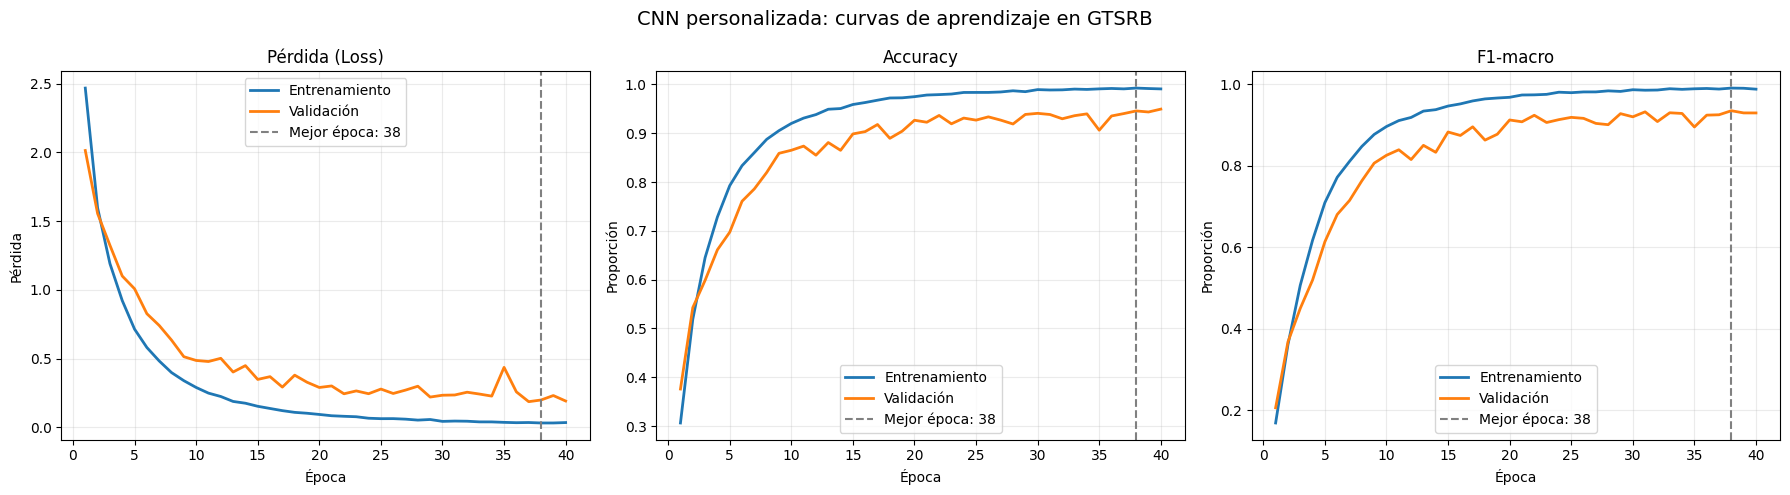

MEJOR CHECKPOINT DE CNN
Época: 38
Train accuracy: 0.992517
Validation accuracy: 0.945683
Validation F1-macro: 0.93481
Checkpoint verificado: True
Figura guardada: True


In [ ]:

# PASO 26: Análisis gráfico del entrenamiento de la CNN
# Utilizamos el historial real guardado en Google Drive.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from pathlib import Path

# 1. Recuperar el historial y el mejor checkpoint.
archivo_historial = (
    PROYECTO_DRIVE
    / "resultados/CNNPersonalizada_seed42_historial.csv"
)

archivo_modelo = (
    PROYECTO_DRIVE
    / "checkpoints/CNNPersonalizada_seed42_best.pth"
)

historial_cnn = pd.read_csv(archivo_historial)

checkpoint = torch.load(
    archivo_modelo,
    map_location="cpu",
    weights_only=True
)

# 2. Identificar la mejor época según F1-macro.
indice_mejor = historial_cnn["val_f1_macro"].idxmax()
mejor_registro = historial_cnn.loc[indice_mejor]

mejor_epoca = int(mejor_registro["epoca"])

# Verificar que el checkpoint corresponde a esa época.
assert checkpoint["epoca"] == mejor_epoca
assert np.isclose(
    checkpoint["val_f1_macro"],
    mejor_registro["val_f1_macro"]
)

# 3. Preparar tres gráficos comparativos.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metricas = [
    ("train_loss", "val_loss", "Pérdida (Loss)"),
    ("train_accuracy", "val_accuracy", "Accuracy"),
    ("train_f1_macro", "val_f1_macro", "F1-macro")
]

for ax, (train_col, val_col, titulo) in zip(
    axes, metricas
):

    ax.plot(
        historial_cnn["epoca"],
        historial_cnn[train_col],
        label="Entrenamiento",
        linewidth=2
    )

    ax.plot(
        historial_cnn["epoca"],
        historial_cnn[val_col],
        label="Validación",
        linewidth=2
    )

    # Marcar la época elegida para el checkpoint.
    ax.axvline(
        mejor_epoca,
        linestyle="--",
        color="gray",
        label=f"Mejor época: {mejor_epoca}"
    )

    ax.set_title(titulo)
    ax.set_xlabel("Época")
    ax.grid(alpha=0.25)
    ax.legend()

axes[0].set_ylabel("Pérdida")
axes[1].set_ylabel("Proporción")
axes[2].set_ylabel("Proporción")

fig.suptitle(
    "CNN personalizada: curvas de aprendizaje en GTSRB",
    fontsize=14
)

plt.tight_layout()

# 4. Guardar la figura para el artículo científico.
ruta_figura = (
    PROYECTO_DRIVE
    / "resultados/CNNPersonalizada_curvas_aprendizaje.png"
)

plt.savefig(ruta_figura, dpi=200, bbox_inches="tight")
plt.show()

# 5. Mostrar el resumen del mejor checkpoint.
print("MEJOR CHECKPOINT DE CNN")
print("Época:", mejor_epoca)
print(
    "Train accuracy:",
    round(mejor_registro["train_accuracy"], 6)
)
print(
    "Validation accuracy:",
    round(mejor_registro["val_accuracy"], 6)
)
print(
    "Validation F1-macro:",
    round(mejor_registro["val_f1_macro"], 6)
)
print("Checkpoint verificado:", archivo_modelo.is_file())
print("Figura guardada:", ruta_figura.is_file())


### Interpretación del Paso 26: Curvas de aprendizaje

Las curvas evidencian una reducción progresiva de la pérdida de entrenamiento y una mejora sostenida de la exactitud y del F1-macro. La validación presenta fluctuaciones y una diferencia respecto al entrenamiento, lo que indica limitaciones de generalización. La época 38 alcanzó el mejor F1-macro de validación (0.93481) y una exactitud de 0.945683, por lo que se seleccionó su checkpoint como modelo de referencia.

CHECKPOINT CARGADO
Modelo: CNNPersonalizada
Época: 38
F1-macro guardado: 0.93481

RESULTADOS GLOBALES EN VALIDACIÓN
Imágenes evaluadas: 8340
Accuracy: 0.945683
F1-macro: 0.93481
Errores: 453

10 CLASES CON MENOR RECALL


,ClassId,Soporte,Precision,Recall,F1
19,19,60,0.6667,0.5667,0.6126
30,30,90,1.0000,0.6889,0.8158
36,36,90,1.0000,0.7000,0.8235
15,15,150,0.9817,0.7133,0.8263
9,9,300,0.9908,0.7167,0.8317
41,41,60,1.0000,0.7500,0.8571
34,34,90,1.0000,0.8111,0.8957
3,3,300,1.0000,0.8800,0.9362
16,16,90,1.0000,0.8889,0.9412
20,20,90,0.9756,0.8889,0.9302



10 CLASES CON MENOR F1


,ClassId,Soporte,Precision,Recall,F1
19,19,60,0.6667,0.5667,0.6126
30,30,90,1.0000,0.6889,0.8158
36,36,90,1.0000,0.7000,0.8235
15,15,150,0.9817,0.7133,0.8263
9,9,300,0.9908,0.7167,0.8317
41,41,60,1.0000,0.7500,0.8571
34,34,90,1.0000,0.8111,0.8957
10,10,420,0.8219,1.0000,0.9023
35,35,240,0.8604,0.9500,0.9030
37,37,60,0.9167,0.9167,0.9167


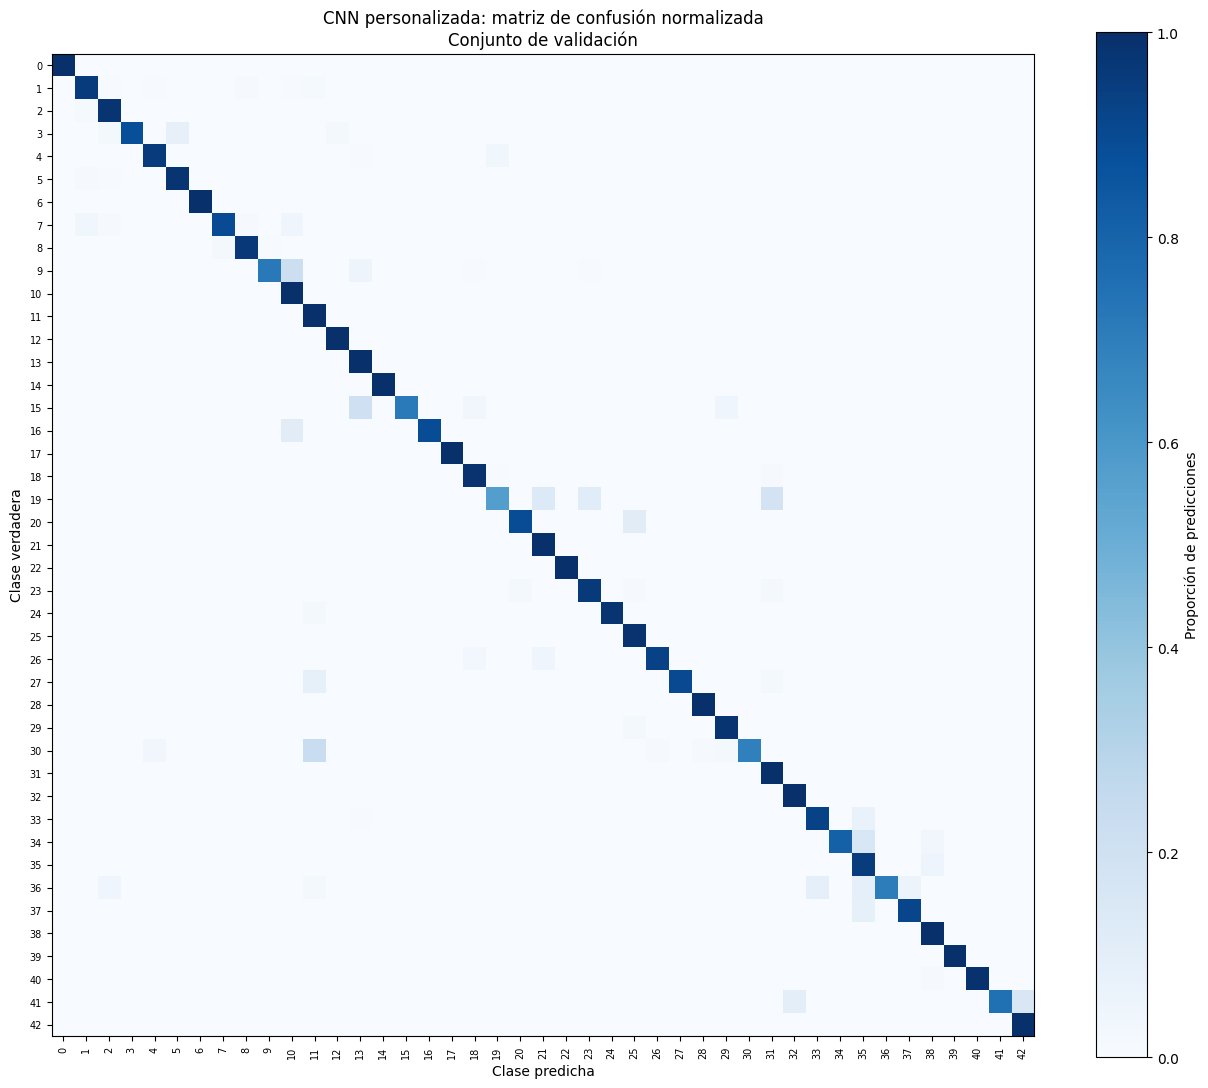


10 CONFUSIONES MÁS FRECUENTES


,Clase_real,Clase_predicha,Errores
34,9,10,65
41,15,13,31
11,3,5,24
65,30,11,21
35,9,13,15
17,4,19,15
71,34,35,14
73,35,38,12
25,7,10,12
22,7,1,11



ARCHIVOS GENERADOS
Matriz de confusión: True
Métricas por clase: True
Matriz numérica: True
Conjunto test utilizado: NO


In [ ]:

# PASO 27: Evaluación detallada de la CNN personalizada
# Se utiliza el mejor checkpoint y solo validación.
# El conjunto test permanece reservado.

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    precision_recall_fscore_support
)

# 1. Cargar el checkpoint seleccionado.
ruta_checkpoint = (
    PROYECTO_DRIVE
    / "checkpoints/CNNPersonalizada_seed42_best.pth"
)

checkpoint = torch.load(
    ruta_checkpoint,
    map_location=DEVICE,
    weights_only=True
)

# 2. Reconstruir la arquitectura.
modelo_cnn = CNNPersonalizada(
    num_classes=43
).to(DEVICE)

modelo_cnn.load_state_dict(
    checkpoint["model_state_dict"]
)

# Desactivar Dropout y usar estadísticas
# aprendidas por las capas BatchNorm.
modelo_cnn.eval()

print("CHECKPOINT CARGADO")
print("Modelo:", checkpoint["modelo"])
print("Época:", checkpoint["epoca"])
print(
    "F1-macro guardado:",
    round(checkpoint["val_f1_macro"], 6)
)


# 3. Obtener predicciones sobre validación.
# Se reproduce el mismo modo de precisión mixta (AMP)
# utilizado durante la validación del Paso 25.

etiquetas_reales = []
etiquetas_predichas = []

usar_amp = DEVICE.type == "cuda"

# inference_mode desactiva los gradientes.
# autocast reproduce la precisión mixta del entrenamiento.
with torch.inference_mode(), torch.amp.autocast(
    device_type="cuda",
    enabled=usar_amp
):

    for imagenes, etiquetas in val_loader:

        imagenes = imagenes.to(
            DEVICE, non_blocking=True
        )

        # Inferencia con la misma configuración de AMP.
        salidas = modelo_cnn(imagenes)

        predicciones = salidas.argmax(dim=1)

        etiquetas_reales.extend(
            etiquetas.numpy().tolist()
        )

        etiquetas_predichas.extend(
            predicciones.cpu().tolist()
        )

y_true = np.array(etiquetas_reales)
y_pred = np.array(etiquetas_predichas)

# 4. Verificar tamaño y rango de clases.
clases = np.arange(43)

assert len(y_true) == 8340
assert len(y_pred) == 8340
assert np.isin(y_true, clases).all()
assert np.isin(y_pred, clases).all()

# 5. Calcular métricas globales.
accuracy = accuracy_score(y_true, y_pred)

f1_macro = f1_score(
    y_true,
    y_pred,
    labels=clases,
    average="macro",
    zero_division=0
)

print("\nRESULTADOS GLOBALES EN VALIDACIÓN")
print("Imágenes evaluadas:", len(y_true))
print("Accuracy:", round(accuracy, 6))
print("F1-macro:", round(f1_macro, 6))
print("Errores:", int((y_true != y_pred).sum()))

# Verificar consistencia con el checkpoint.
assert np.isclose(
    accuracy,
    checkpoint["val_accuracy"],
    atol=1e-6
)

assert np.isclose(
    f1_macro,
    checkpoint["val_f1_macro"],
    atol=1e-6
)

# 6. Calcular Precision, Recall y F1 por clase.
precision, recall, f1, soporte = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=clases,
        zero_division=0
    )
)

metricas_clases = pd.DataFrame({
    "ClassId": clases,
    "Soporte": soporte,
    "Precision": precision,
    "Recall": recall,
    "F1": f1
})

# 7. Mostrar las clases con menor recall.
# El recall mide qué proporción de imágenes
# verdaderas de una clase fue reconocida.
print("\n10 CLASES CON MENOR RECALL")
display(
    metricas_clases
    .sort_values(["Recall", "ClassId"])
    .head(10)
    .round(4)
)

# 8. Mostrar las clases con menor F1.
print("\n10 CLASES CON MENOR F1")
display(
    metricas_clases
    .sort_values(["F1", "ClassId"])
    .head(10)
    .round(4)
)

# 9. Calcular la matriz de confusión.
matriz = confusion_matrix(
    y_true,
    y_pred,
    labels=clases
)

# Normalizar cada fila por el número de
# ejemplos reales de la clase correspondiente.
matriz_normalizada = (
    matriz
    / matriz.sum(axis=1, keepdims=True)
)

# 10. Visualizar la matriz normalizada.
fig, ax = plt.subplots(figsize=(13, 11))

imagen = ax.imshow(
    matriz_normalizada,
    interpolation="nearest",
    cmap="Blues",
    vmin=0,
    vmax=1
)

fig.colorbar(
    imagen,
    ax=ax,
    label="Proporción de predicciones"
)

ax.set_title(
    "CNN personalizada: matriz de confusión normalizada\n"
    "Conjunto de validación"
)

ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase verdadera")

ax.set_xticks(clases)
ax.set_yticks(clases)

ax.tick_params(
    axis="x",
    labelrotation=90,
    labelsize=7
)
ax.tick_params(
    axis="y",
    labelsize=7
)

plt.tight_layout()

# 11. Guardar figura y tablas para el artículo.
RESULTADOS = PROYECTO_DRIVE / "resultados"
RESULTADOS.mkdir(parents=True, exist_ok=True)

ruta_figura = (
    RESULTADOS
    / "CNNPersonalizada_matriz_confusion_val.png"
)

ruta_metricas = (
    RESULTADOS
    / "CNNPersonalizada_metricas_por_clase_val.csv"
)

ruta_matriz = (
    RESULTADOS
    / "CNNPersonalizada_matriz_confusion_val.csv"
)

fig.savefig(
    ruta_figura,
    dpi=220,
    bbox_inches="tight"
)

plt.show()

metricas_clases.to_csv(
    ruta_metricas,
    index=False
)

pd.DataFrame(
    matriz,
    index=clases,
    columns=clases
).to_csv(ruta_matriz)

# 12. Identificar las confusiones más frecuentes.
# Se excluye la diagonal porque representa aciertos.
matriz_errores = matriz.copy()
np.fill_diagonal(matriz_errores, 0)

confusiones = []

for clase_real in clases:
    for clase_predicha in clases:

        cantidad = matriz_errores[
            clase_real, clase_predicha
        ]

        if cantidad > 0:
            confusiones.append({
                "Clase_real": clase_real,
                "Clase_predicha": clase_predicha,
                "Errores": int(cantidad)
            })

tabla_errores = pd.DataFrame(
    confusiones,
    columns=[
        "Clase_real",
        "Clase_predicha",
        "Errores"
    ]
)

print("\n10 CONFUSIONES MÁS FRECUENTES")

if not tabla_errores.empty:
    display(
        tabla_errores
        .sort_values(
            "Errores",
            ascending=False
        )
        .head(10)
    )
else:
    print("No se encontraron errores.")

# 13. Confirmar los archivos generados.
print("\nARCHIVOS GENERADOS")
print("Matriz de confusión:", ruta_figura.is_file())
print("Métricas por clase:", ruta_metricas.is_file())
print("Matriz numérica:", ruta_matriz.is_file())
print("Conjunto test utilizado: NO")


### Interpretación del Paso 27: Evaluación de la CNN personalizada

La CNN personalizada alcanzó una exactitud de 94.57 % y un F1-macro de 93.48 % sobre 8 340 imágenes de validación, con 453 clasificaciones incorrectas. La matriz de confusión muestra un predominio de aciertos, aunque se identificaron dificultades en las clases 19, 30, 36, 15 y 9. La confusión más frecuente ocurrió entre las clases 9 y 10, con 65 errores. Estos resultados constituyen la línea base para comparar las arquitecturas ResNet18 y MobileNetV2.

In [32]:

# PASO 28: Entrenamiento de ResNet18 en GTSRB
# Mismo protocolo experimental que la CNN personalizada.
# El conjunto de prueba permanece reservado.

import random
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from sklearn.metrics import f1_score

# 1. Recuperar hiperparámetros comunes.
SEED = CONFIG_TRAIN["semilla"]
EPOCHS = CONFIG_TRAIN["max_epochs"]
PATIENCE = CONFIG_TRAIN["early_stopping_patience"]
LR = CONFIG_TRAIN["learning_rate"]
WEIGHT_DECAY = CONFIG_TRAIN["weight_decay"]
BATCH_SIZE = CONFIG_TRAIN["batch_size"]

# 2. Restablecer las semillas antes del experimento.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# 3. Reconstruir ResNet18 desde cero.
# La función fue definida en el Paso 23.
modelo_resnet = crear_resnet18().to(DEVICE)

# 4. Preparar DataLoader con el mismo conjunto,
# Data Augmentation y semilla inicial.
generador_resnet = torch.Generator().manual_seed(SEED)

loader_train_resnet = DataLoader(
    train_dataset_aug,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    worker_init_fn=inicializar_worker,
    generator=generador_resnet
)

# Validación sin aumentos.
loader_val_resnet = val_loader

# 5. Definir pérdida y optimizador independientes.
criterio_resnet = nn.CrossEntropyLoss()

optimizador_resnet = torch.optim.AdamW(
    modelo_resnet.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

# 6. Configurar precisión mixta.
usar_amp = DEVICE.type == "cuda"

scaler_resnet = torch.amp.GradScaler(
    "cuda",
    enabled=usar_amp
)

# 7. Crear rutas persistentes en Google Drive.
RESULTADOS = PROYECTO_DRIVE / "resultados"
RESULTADOS.mkdir(parents=True, exist_ok=True)
CHECKPOINTS.mkdir(parents=True, exist_ok=True)

archivo_modelo_resnet = (
    CHECKPOINTS / "ResNet18_seed42_best.pth"
)

archivo_historial_resnet = (
    RESULTADOS / "ResNet18_seed42_historial.csv"
)

# Evitar sobrescribir resultados previos.
if (
    archivo_modelo_resnet.exists()
    or archivo_historial_resnet.exists()
):
    raise FileExistsError(
        "Ya existe un experimento ResNet18_seed42. "
        "No se sobrescribirán sus resultados."
    )

# 8. Función independiente para entrenar o validar.
def ejecutar_epoca_modelo(
    modelo,
    loader,
    criterio,
    optimizador=None,
    scaler=None
):
    entrenar = optimizador is not None

    if entrenar:
        modelo.train()
    else:
        modelo.eval()

    perdida_total = 0.0
    correctas = 0
    total = 0

    reales = []
    predichas = []

    with torch.set_grad_enabled(entrenar):

        for imagenes, etiquetas in loader:

            imagenes = imagenes.to(
                DEVICE, non_blocking=True
            )
            etiquetas = etiquetas.to(
                DEVICE, non_blocking=True
            )

            if entrenar:
                optimizador.zero_grad(set_to_none=True)

            # Utilizar AMP tanto en entrenamiento
            # como en validación para mantener
            # consistencia numérica.
            with torch.amp.autocast(
                device_type="cuda",
                enabled=usar_amp
            ):
                salidas = modelo(imagenes)
                perdida = criterio(salidas, etiquetas)

            if entrenar:
                scaler.scale(perdida).backward()
                scaler.step(optimizador)
                scaler.update()

            predicciones = salidas.argmax(dim=1)
            cantidad = etiquetas.size(0)

            perdida_total += perdida.item() * cantidad

            correctas += (
                predicciones == etiquetas
            ).sum().item()

            total += cantidad

            reales.extend(etiquetas.cpu().tolist())
            predichas.extend(
                predicciones.cpu().tolist()
            )

    loss = perdida_total / total
    accuracy = correctas / total

    f1_macro = f1_score(
        reales,
        predichas,
        labels=list(range(43)),
        average="macro",
        zero_division=0
    )

    return loss, accuracy, f1_macro


# 9. Inicializar el seguimiento.
historial_resnet = []

mejor_f1_resnet = -1.0
mejor_epoca_resnet = 0
epocas_sin_mejora = 0

inicio_total = time.perf_counter()

print("ENTRENAMIENTO: RESNET18")
print("GPU:", torch.cuda.get_device_name(0))
print("Épocas máximas:", EPOCHS)
print("Paciencia:", PATIENCE)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LR)
print("Selección: F1-macro de validación")

# 10. Ejecutar el entrenamiento.
for epoca in range(1, EPOCHS + 1):

    inicio_epoca = time.perf_counter()

    train_loss, train_acc, train_f1 = (
        ejecutar_epoca_modelo(
            modelo_resnet,
            loader_train_resnet,
            criterio_resnet,
            optimizador=optimizador_resnet,
            scaler=scaler_resnet
        )
    )

    val_loss, val_acc, val_f1 = (
        ejecutar_epoca_modelo(
            modelo_resnet,
            loader_val_resnet,
            criterio_resnet
        )
    )

    tiempo_epoca = (
        time.perf_counter() - inicio_epoca
    )

    # Registrar métricas de cada época.
    historial_resnet.append({
        "epoca": epoca,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_f1_macro": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_f1_macro": val_f1,
        "tiempo_segundos": tiempo_epoca
    })

    # Persistir historial en cada época.
    pd.DataFrame(historial_resnet).to_csv(
        archivo_historial_resnet,
        index=False
    )

    # 11. Guardar el mejor checkpoint.
    if val_f1 > mejor_f1_resnet + 1e-6:

        mejor_f1_resnet = val_f1
        mejor_epoca_resnet = epoca
        epocas_sin_mejora = 0

        checkpoint_resnet = {
            "epoca": epoca,
            "modelo": "ResNet18",
            "seed": SEED,
            "model_state_dict": (
                modelo_resnet.state_dict()
            ),
            "optimizer_state_dict": (
                optimizador_resnet.state_dict()
            ),
            "val_f1_macro": float(val_f1),
            "val_accuracy": float(val_acc),
            "configuracion": CONFIG_TRAIN
        }

        temporal = (
            archivo_modelo_resnet.with_suffix(".tmp")
        )

        torch.save(checkpoint_resnet, temporal)
        temporal.replace(archivo_modelo_resnet)

        estado = "MEJOR MODELO"

    else:
        epocas_sin_mejora += 1
        estado = ""

    print(
        f"Época {epoca:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"{tiempo_epoca:.1f}s {estado}",
        flush=True
    )

    # 12. Early stopping según F1-macro.
    if epocas_sin_mejora >= PATIENCE:
        print(
            f"\nEarly stopping en época {epoca}"
        )
        break

# 13. Resumir resultados.
tiempo_total_resnet = (
    time.perf_counter() - inicio_total
)

print("\nRESUMEN DEL ENTRENAMIENTO RESNET18")
print("Épocas ejecutadas:", len(historial_resnet))
print("Mejor época:", mejor_epoca_resnet)
print(
    "Mejor F1-macro validación:",
    round(mejor_f1_resnet, 6)
)
print(
    "Tiempo total (segundos):",
    round(tiempo_total_resnet, 2)
)
print(
    "Checkpoint disponible:",
    archivo_modelo_resnet.is_file()
)
print(
    "Historial disponible:",
    archivo_historial_resnet.is_file()
)


ENTRENAMIENTO: RESNET18
GPU: Tesla T4
Épocas máximas: 40
Paciencia: 7
Batch size: 64
Learning rate: 0.001
Selección: F1-macro de validación
Época 01/40 | Train Loss: 0.8897 | Train Acc: 0.7400 | Val Loss: 0.3658 | Val Acc: 0.9016 | Val F1: 0.8440 | 38.7s MEJOR MODELO
Época 02/40 | Train Loss: 0.0404 | Train Acc: 0.9887 | Val Loss: 0.2275 | Val Acc: 0.9376 | Val F1: 0.9068 | 35.5s MEJOR MODELO
Época 03/40 | Train Loss: 0.0293 | Train Acc: 0.9918 | Val Loss: 0.2765 | Val Acc: 0.9335 | Val F1: 0.9266 | 38.7s MEJOR MODELO
Época 04/40 | Train Loss: 0.0149 | Train Acc: 0.9958 | Val Loss: 0.2135 | Val Acc: 0.9508 | Val F1: 0.9253 | 37.7s 
Época 05/40 | Train Loss: 0.0187 | Train Acc: 0.9943 | Val Loss: 0.1191 | Val Acc: 0.9731 | Val F1: 0.9586 | 37.7s MEJOR MODELO
Época 06/40 | Train Loss: 0.0117 | Train Acc: 0.9966 | Val Loss: 0.2032 | Val Acc: 0.9566 | Val F1: 0.9329 | 37.4s 
Época 07/40 | Train Loss: 0.0123 | Train Acc: 0.9970 | Val Loss: 0.1090 | Val Acc: 0.9848 | Val F1: 0.9736 | 37.5s M

### Interpretación del Paso 28: Entrenamiento de ResNet18

Se entrenó ResNet18 desde cero utilizando AdamW, entropía cruzada y aumentos de datos dinámicos. El entrenamiento finalizó en la época 20 mediante early stopping, seleccionándose el checkpoint de la época 13, con una exactitud de validación del 98.36 % y un F1-macro del 97.43 %. ResNet18 superó a la CNN personalizada en 3.95 puntos porcentuales de F1-macro, aunque requirió mayor tiempo de procesamiento por época y presentó fluctuaciones en la validación.

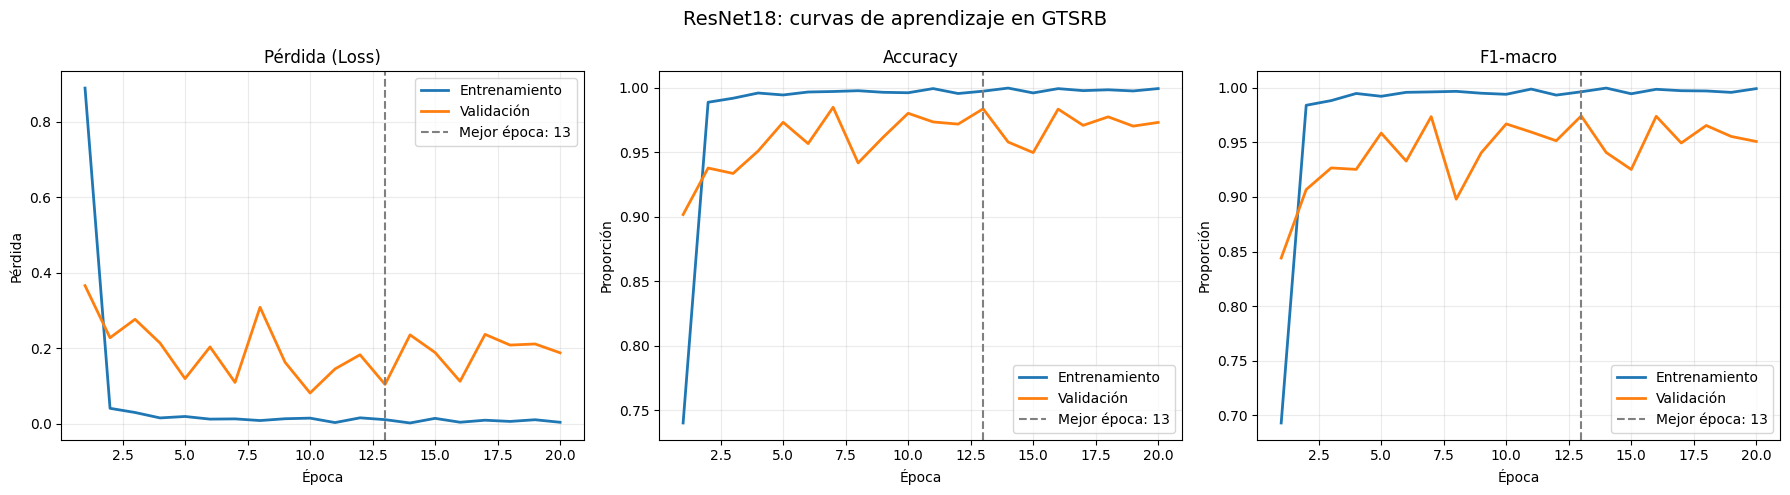

MEJOR CHECKPOINT DE RESNET18
Época: 13
Train accuracy: 0.997246
Validation accuracy: 0.983573
Validation F1-macro: 0.974288
Validation loss: 0.103636
Épocas ejecutadas: 20
Checkpoint verificado: True
Figura guardada: True


In [ ]:

# PASO 29: Análisis de las curvas de aprendizaje
# de ResNet18, usando resultados guardados en Drive.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch

# 1. Localizar historial y checkpoint.
ruta_historial = (
    PROYECTO_DRIVE
    / "resultados/ResNet18_seed42_historial.csv"
)

ruta_checkpoint = (
    PROYECTO_DRIVE
    / "checkpoints/ResNet18_seed42_best.pth"
)

# 2. Cargar resultados del entrenamiento.
historial_resnet = pd.read_csv(ruta_historial)

checkpoint_resnet = torch.load(
    ruta_checkpoint,
    map_location="cpu",
    weights_only=True
)

# 3. Identificar la mejor época por F1-macro.
indice_mejor = historial_resnet["val_f1_macro"].idxmax()
registro_mejor = historial_resnet.loc[indice_mejor]

mejor_epoca = int(registro_mejor["epoca"])

# Comprobar consistencia con el checkpoint.
assert mejor_epoca == checkpoint_resnet["epoca"]

assert np.isclose(
    registro_mejor["val_f1_macro"],
    checkpoint_resnet["val_f1_macro"]
)

assert np.isclose(
    registro_mejor["val_accuracy"],
    checkpoint_resnet["val_accuracy"]
)

# 4. Definir las métricas que visualizaremos.
metricas = [
    ("train_loss", "val_loss", "Pérdida (Loss)"),
    ("train_accuracy", "val_accuracy", "Accuracy"),
    ("train_f1_macro", "val_f1_macro", "F1-macro")
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

# 5. Graficar entrenamiento y validación.
for ax, (train_col, val_col, titulo) in zip(
    axes, metricas
):

    ax.plot(
        historial_resnet["epoca"],
        historial_resnet[train_col],
        linewidth=2,
        label="Entrenamiento"
    )

    ax.plot(
        historial_resnet["epoca"],
        historial_resnet[val_col],
        linewidth=2,
        label="Validación"
    )

    # Señalar la época del mejor checkpoint.
    ax.axvline(
        mejor_epoca,
        color="gray",
        linestyle="--",
        label=f"Mejor época: {mejor_epoca}"
    )

    ax.set_title(titulo)
    ax.set_xlabel("Época")
    ax.grid(alpha=0.25)
    ax.legend()

axes[0].set_ylabel("Pérdida")
axes[1].set_ylabel("Proporción")
axes[2].set_ylabel("Proporción")

fig.suptitle(
    "ResNet18: curvas de aprendizaje en GTSRB",
    fontsize=14
)

plt.tight_layout()

# 6. Guardar la figura para el artículo científico.
ruta_figura = (
    PROYECTO_DRIVE
    / "resultados/ResNet18_curvas_aprendizaje.png"
)

plt.savefig(
    ruta_figura,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# 7. Mostrar métricas de la época seleccionada.
print("MEJOR CHECKPOINT DE RESNET18")
print("Época:", mejor_epoca)

print(
    "Train accuracy:",
    round(registro_mejor["train_accuracy"], 6)
)

print(
    "Validation accuracy:",
    round(registro_mejor["val_accuracy"], 6)
)

print(
    "Validation F1-macro:",
    round(registro_mejor["val_f1_macro"], 6)
)

print(
    "Validation loss:",
    round(registro_mejor["val_loss"], 6)
)

print(
    "Épocas ejecutadas:",
    len(historial_resnet)
)

print(
    "Checkpoint verificado:",
    ruta_checkpoint.is_file()
)

print(
    "Figura guardada:",
    ruta_figura.is_file()
)


### Interpretación del Paso 29: Curvas de aprendizaje de ResNet18

ResNet18 presentó una convergencia rápida, alcanzando valores de exactitud superiores al 99 % durante el entrenamiento. Las métricas de validación mostraron fluctuaciones, especialmente en la pérdida, pero mantuvieron un rendimiento elevado. La época 13 obtuvo el mejor F1-macro de validación (0.974288), con una exactitud de 0.983573 y una pérdida de 0.103636. El entrenamiento terminó en la época 20 mediante early stopping, conservando el checkpoint seleccionado.

CHECKPOINT CARGADO
Modelo: ResNet18
Época: 13
F1-macro guardado: 0.974288

RESULTADOS GLOBALES EN VALIDACIÓN
Imágenes evaluadas: 8340
Accuracy: 0.983573
F1-macro: 0.974288
Errores: 137

10 CLASES CON MENOR RECALL


,ClassId,Soporte,Precision,Recall,F1
19,19,60,0.9677,0.5000,0.6593
15,15,150,1.0000,0.8067,0.8930
37,37,60,1.0000,0.8333,0.9091
3,3,300,1.0000,0.9000,0.9474
30,30,90,1.0000,0.9333,0.9655
32,32,60,1.0000,0.9500,0.9744
29,29,60,0.8788,0.9667,0.9206
20,20,90,1.0000,0.9778,0.9888
1,1,450,0.9932,0.9800,0.9866
7,7,300,1.0000,0.9867,0.9933



10 CLASES CON MENOR F1


,ClassId,Soporte,Precision,Recall,F1
19,19,60,0.9677,0.5000,0.6593
15,15,150,1.0000,0.8067,0.8930
23,23,120,0.8151,0.9917,0.8947
37,37,60,1.0000,0.8333,0.9091
29,29,60,0.8788,0.9667,0.9206
3,3,300,1.0000,0.9000,0.9474
40,40,90,0.9000,1.0000,0.9474
5,5,390,0.9127,0.9923,0.9509
30,30,90,1.0000,0.9333,0.9655
32,32,60,1.0000,0.9500,0.9744


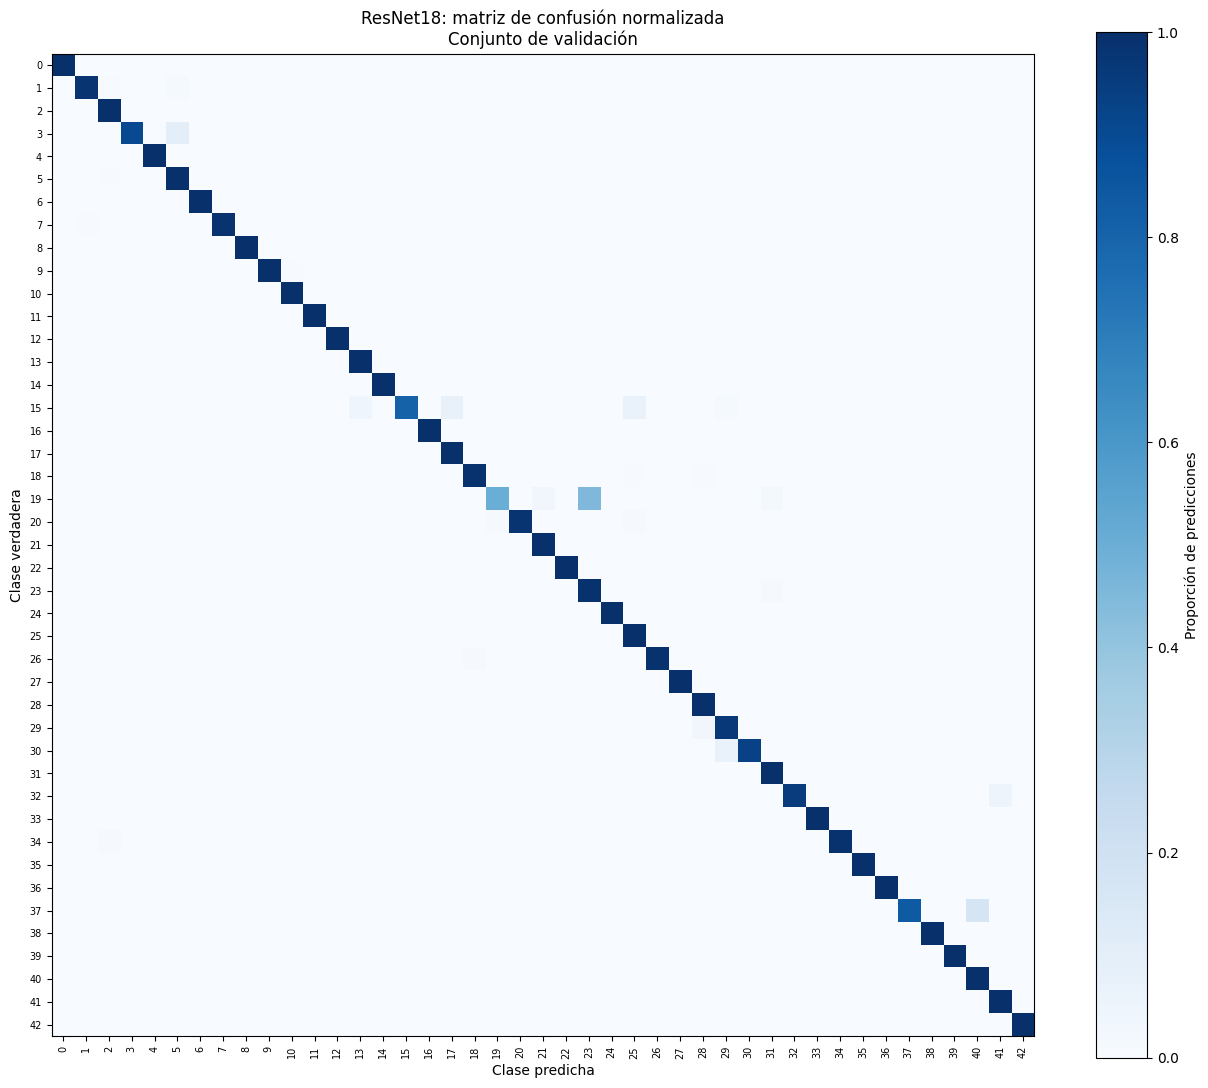


10 CONFUSIONES MÁS FRECUENTES


,Clase_real,Clase_predicha,Errores
4,3,5,29
19,19,23,27
13,15,17,11
14,15,25,10
29,37,40,10
12,15,13,6
26,30,29,6
1,1,5,6
0,1,2,3
27,32,41,3



COMPARACIÓN DE CLASES MÁS DIFÍCILES PARA LA CNN


,ClassId,Recall_CNN,F1_CNN,Recall_ResNet18,F1_ResNet18,Mejora_recall_pp,Mejora_F1_pp
9,9,0.7167,0.8317,0.9933,0.9967,27.6667,16.4934
15,15,0.7133,0.8263,0.8067,0.8930,9.3333,6.6734
19,19,0.5667,0.6126,0.5000,0.6593,-6.6667,4.6728
30,30,0.6889,0.8158,0.9333,0.9655,24.4444,14.9728
36,36,0.7000,0.8235,1.0000,1.0000,30.0000,17.6471



ARCHIVOS GENERADOS
Matriz de confusión: True
Métricas por clase: True
Matriz numérica: True
Comparación con CNN: True
Conjunto test utilizado: NO


In [ ]:

# PASO 30: Evaluación detallada de ResNet18
# Utilizamos el mejor checkpoint y solo validación.
# El conjunto de prueba permanece reservado.

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    precision_recall_fscore_support
)

# 1. Recuperar el checkpoint de la época 13.
ruta_checkpoint = (
    PROYECTO_DRIVE
    / "checkpoints/ResNet18_seed42_best.pth"
)

checkpoint_resnet = torch.load(
    ruta_checkpoint,
    map_location=DEVICE,
    weights_only=True
)

# 2. Crear una instancia limpia de ResNet18
# y cargar los parámetros aprendidos.
modelo_eval = crear_resnet18().to(DEVICE)

modelo_eval.load_state_dict(
    checkpoint_resnet["model_state_dict"]
)

# Desactivar Dropout y utilizar BatchNorm en evaluación.
modelo_eval.eval()

print("CHECKPOINT CARGADO")
print("Modelo:", checkpoint_resnet["modelo"])
print("Época:", checkpoint_resnet["epoca"])
print(
    "F1-macro guardado:",
    round(checkpoint_resnet["val_f1_macro"], 6)
)

# 3. Realizar inferencia sobre validación.
# AMP reproduce las condiciones numéricas
# utilizadas durante el entrenamiento.
reales = []
predichas = []

with torch.inference_mode(), torch.amp.autocast(
    device_type=DEVICE.type,
    enabled=DEVICE.type == "cuda"
):

    for imagenes, etiquetas in val_loader:

        imagenes = imagenes.to(
            DEVICE, non_blocking=True
        )

        salidas = modelo_eval(imagenes)
        predicciones = salidas.argmax(dim=1)

        reales.extend(etiquetas.cpu().tolist())
        predichas.extend(
            predicciones.cpu().tolist()
        )

y_true = np.asarray(reales)
y_pred = np.asarray(predichas)
clases = np.arange(43)

assert len(y_true) == 8340
assert len(y_pred) == 8340

# 4. Calcular las métricas globales.
accuracy = accuracy_score(y_true, y_pred)

f1_macro = f1_score(
    y_true, y_pred,
    labels=clases,
    average="macro",
    zero_division=0
)

errores = int(np.sum(y_true != y_pred))

print("\nRESULTADOS GLOBALES EN VALIDACIÓN")
print("Imágenes evaluadas:", len(y_true))
print("Accuracy:", round(accuracy, 6))
print("F1-macro:", round(f1_macro, 6))
print("Errores:", errores)

# 5. Comprobar coincidencia con el checkpoint.
# Usamos AMP para evitar el problema numérico
# que apareció anteriormente con la CNN.
assert np.isclose(
    accuracy,
    checkpoint_resnet["val_accuracy"],
    atol=1e-6
), "La exactitud no coincide con el checkpoint."

assert np.isclose(
    f1_macro,
    checkpoint_resnet["val_f1_macro"],
    atol=1e-6
), "El F1-macro no coincide con el checkpoint."

# 6. Obtener Precision, Recall y F1 por clase.
precision, recall, f1, soporte = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=clases,
        zero_division=0
    )
)

metricas_resnet = pd.DataFrame({
    "ClassId": clases,
    "Soporte": soporte,
    "Precision": precision,
    "Recall": recall,
    "F1": f1
})

print("\n10 CLASES CON MENOR RECALL")
display(
    metricas_resnet
    .nsmallest(10, "Recall")
    .round(4)
)

print("\n10 CLASES CON MENOR F1")
display(
    metricas_resnet
    .nsmallest(10, "F1")
    .round(4)
)

# 7. Construir matriz de confusión.
matriz = confusion_matrix(
    y_true,
    y_pred,
    labels=clases
)

# Normalizar por filas (clases verdaderas).
matriz_normalizada = (
    matriz / matriz.sum(axis=1, keepdims=True)
)

fig, ax = plt.subplots(figsize=(13, 11))

img = ax.imshow(
    matriz_normalizada,
    cmap="Blues",
    interpolation="nearest",
    vmin=0,
    vmax=1
)

fig.colorbar(
    img,
    ax=ax,
    label="Proporción de predicciones"
)

ax.set_title(
    "ResNet18: matriz de confusión normalizada\n"
    "Conjunto de validación"
)

ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase verdadera")

ax.set_xticks(clases)
ax.set_yticks(clases)

ax.tick_params(axis="x", labelrotation=90, labelsize=7)
ax.tick_params(axis="y", labelsize=7)

plt.tight_layout()

# 8. Guardar figura y métricas en Google Drive.
RESULTADOS = PROYECTO_DRIVE / "resultados"
RESULTADOS.mkdir(parents=True, exist_ok=True)

ruta_figura = (
    RESULTADOS / "ResNet18_matriz_confusion_val.png"
)

ruta_metricas = (
    RESULTADOS / "ResNet18_metricas_por_clase_val.csv"
)

ruta_matriz = (
    RESULTADOS / "ResNet18_matriz_confusion_val.csv"
)

fig.savefig(ruta_figura, dpi=220, bbox_inches="tight")
plt.show()

metricas_resnet.to_csv(ruta_metricas, index=False)

pd.DataFrame(
    matriz,
    index=clases,
    columns=clases
).to_csv(ruta_matriz)

# 9. Identificar las principales confusiones.
matriz_errores = matriz.copy()
np.fill_diagonal(matriz_errores, 0)

filas, columnas = np.where(matriz_errores > 0)

tabla_confusiones = pd.DataFrame({
    "Clase_real": filas,
    "Clase_predicha": columnas,
    "Errores": matriz_errores[filas, columnas]
})

print("\n10 CONFUSIONES MÁS FRECUENTES")
display(
    tabla_confusiones
    .sort_values("Errores", ascending=False)
    .head(10)
)

# 10. Comparar recall con la CNN personalizada.
ruta_cnn = (
    RESULTADOS
    / "CNNPersonalizada_metricas_por_clase_val.csv"
)

metricas_cnn = pd.read_csv(ruta_cnn)

comparacion = metricas_cnn[
    ["ClassId", "Recall", "F1"]
].merge(
    metricas_resnet[["ClassId", "Recall", "F1"]],
    on="ClassId",
    suffixes=("_CNN", "_ResNet18"),
    validate="one_to_one"
)

comparacion["Mejora_recall_pp"] = (
    comparacion["Recall_ResNet18"]
    - comparacion["Recall_CNN"]
) * 100

comparacion["Mejora_F1_pp"] = (
    comparacion["F1_ResNet18"]
    - comparacion["F1_CNN"]
) * 100

print("\nCOMPARACIÓN DE CLASES MÁS DIFÍCILES PARA LA CNN")
display(
    comparacion[
        comparacion["ClassId"].isin([19, 30, 36, 15, 9])
    ].sort_values("ClassId").round(4)
)

# 11. Guardar la comparación para el artículo.
ruta_comparacion = (
    RESULTADOS / "Comparacion_CNN_ResNet18_clases_val.csv"
)

comparacion.to_csv(ruta_comparacion, index=False)

# 12. Verificar archivos y aislamiento de test.
print("\nARCHIVOS GENERADOS")
print("Matriz de confusión:", ruta_figura.is_file())
print("Métricas por clase:", ruta_metricas.is_file())
print("Matriz numérica:", ruta_matriz.is_file())
print("Comparación con CNN:", ruta_comparacion.is_file())
print("Conjunto test utilizado: NO")


### Interpretación del Paso 30: Evaluación detallada de ResNet18

ResNet18 alcanzó una exactitud de 98.36 % y un F1-macro de 97.43 % sobre las 8 340 imágenes de validación, registrando 137 errores frente a los 453 de la CNN personalizada. Se observaron mejoras importantes en las clases 9, 15, 30 y 36. No obstante, el recall de la clase 19 disminuyó de 56.67 % a 50.00 %, identificándose la confusión 19 → 23 como uno de los principales problemas. Los resultados evidencian una mejora global sustancial, aunque persisten dificultades específicas por clase.

In [33]:
# PASO 31: Entrenamiento de MobileNetV2
# Tercer modelo del estudio comparativo GTSRB.
# Mismo protocolo utilizado en CNN y ResNet18.
# No se utiliza el conjunto de prueba.

import random
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

# Definir la función de inicialización de workers faltante para evitar NameError
def inicializar_worker(worker_id):
    semilla_worker = torch.initial_seed() % (2**32)
    np.random.seed(semilla_worker)
    random.seed(semilla_worker)

# 1. Recuperar el protocolo experimental.
SEED = CONFIG_TRAIN["semilla"]
EPOCHS = CONFIG_TRAIN["max_epochs"]
PATIENCE = CONFIG_TRAIN["early_stopping_patience"]
LR = CONFIG_TRAIN["learning_rate"]
WEIGHT_DECAY = CONFIG_TRAIN["weight_decay"]
BATCH_SIZE = CONFIG_TRAIN["batch_size"]

# 2. Establecer semillas para el experimento.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# 3. Crear MobileNetV2 desde cero.
# La función fue definida en el Paso 23.
modelo_mobilenet = crear_mobilenetv2().to(DEVICE)

parametros_mobilenet = sum(
    p.numel()
    for p in modelo_mobilenet.parameters()
    if p.requires_grad
)

assert parametros_mobilenet == 2278955

# 4. Preparar el DataLoader de entrenamiento.
# Conservamos aumentos dinámicos y batch size 64.
generador_mobilenet = (
    torch.Generator().manual_seed(SEED)
)

loader_train_mobilenet = DataLoader(
    train_dataset_aug,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=DEVICE.type == "cuda",
    worker_init_fn=inicializar_worker,
    generator=generador_mobilenet
)

# Validación sin aumentos ni mezcla de muestras.
loader_val_mobilenet = val_loader

# 5. Configurar CrossEntropyLoss y AdamW.
criterio_mobilenet = nn.CrossEntropyLoss()

optimizador_mobilenet = torch.optim.AdamW(
    modelo_mobilenet.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

# 6. Activar precisión mixta en GPU.
# La evaluación también utilizará AMP.
usar_amp = DEVICE.type == "cuda"

scaler_mobilenet = torch.amp.GradScaler(
    "cuda",
    enabled=usar_amp
)

# 7. Definir rutas de almacenamiento en Drive.
RESULTADOS = PROYECTO_DRIVE / "resultados"
RESULTADOS.mkdir(parents=True, exist_ok=True)

CHECKPOINTS = PROYECTO_DRIVE / "checkpoints"
CHECKPOINTS.mkdir(parents=True, exist_ok=True)

archivo_modelo_mobilenet = (
    CHECKPOINTS / "MobileNetV2_seed42_best.pth"
)

archivo_historial_mobilenet = (
    RESULTADOS / "MobileNetV2_seed42_historial.csv"
)

# Proteger resultados de ejecuciones anteriores.
if (
    archivo_modelo_mobilenet.exists()
    or archivo_historial_mobilenet.exists()
):
    raise FileExistsError(
        "Ya existen resultados de MobileNetV2_seed42. "
        "No se sobrescribirá el experimento."
    )

# 8. Inicializar seguimiento del entrenamiento.
historial_mobilenet = []

mejor_f1_mobilenet = -1.0
mejor_epoca_mobilenet = 0
epocas_sin_mejora = 0

inicio_total = time.perf_counter()

print("ENTRENAMIENTO: MOBILENETV2")
print("GPU:", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "No disponible")
print("Parámetros:", parametros_mobilenet)
print("Épocas máximas:", EPOCHS)
print("Paciencia:", PATIENCE)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LR)
print("Selección: F1-macro de validación")

# 9. Entrenar y validar después de cada época.
# Reutilizamos la función independiente del Paso 28.
for epoca in range(1, EPOCHS + 1):

    inicio_epoca = time.perf_counter()

    train_loss, train_acc, train_f1 = (
        ejecutar_epoca_modelo(
            modelo_mobilenet,
            loader_train_mobilenet,
            criterio_mobilenet,
            optimizador=optimizador_mobilenet,
            scaler=scaler_mobilenet
        )
    )

    val_loss, val_acc, val_f1 = (
        ejecutar_epoca_modelo(
            modelo_mobilenet,
            loader_val_mobilenet,
            criterio_mobilenet
        )
    )

    tiempo_epoca = (
        time.perf_counter() - inicio_epoca
    )

    # 10. Registrar los resultados de la época.
    historial_mobilenet.append({
        "epoca": epoca,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_f1_macro": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_f1_macro": val_f1,
        "tiempo_segundos": tiempo_epoca
    })

    # Guardar historial en Google Drive.
    pd.DataFrame(historial_mobilenet).to_csv(
        archivo_historial_mobilenet,
        index=False
    )

    # 11. Seleccionar el mejor checkpoint por F1-macro.
    if val_f1 > mejor_f1_mobilenet + 1e-6:

        mejor_f1_mobilenet = val_f1
        mejor_epoca_mobilenet = epoca
        epocas_sin_mejora = 0

        checkpoint_mobilenet = {
            "epoca": epoca,
            "modelo": "MobileNetV2",
            "seed": SEED,
            "model_state_dict": (
                modelo_mobilenet.state_dict()
            ),
            "optimizer_state_dict": (
                optimizador_mobilenet.state_dict()
            ),
            "val_f1_macro": float(val_f1),
            "val_accuracy": float(val_acc),
            "configuracion": CONFIG_TRAIN
        }

        # Guardar primero en archivo temporal.
        temporal = (
            archivo_modelo_mobilenet.with_suffix(".tmp")
        )

        torch.save(checkpoint_mobilenet, temporal)
        temporal.replace(archivo_modelo_mobilenet)

        estado = "MEJOR MODELO"

    else:
        epocas_sin_mejora += 1
        estado = ""

    # 12. Mostrar las métricas de cada época.
    print(
        f"Época {epoca:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"{tiempo_epoca:.1f}s {estado}",
        flush=True
    )

    # 13. Detener tras siete épocas sin mejoras.
    if epocas_sin_mejora >= PATIENCE:
        print(
            f"\nEarly stopping en época {epoca}"
        )
        break

# 14. Resumen del experimento.
tiempo_total_mobilenet = (
    time.perf_counter() - inicio_total
)

historial_mobilenet = pd.DataFrame(
    historial_mobilenet
)

print("\nRESUMEN DEL ENTRENAMIENTO MOBILENETV2")
print("Épocas ejecutadas:", len(historial_mobilenet))
print("Mejor época:", mejor_epoca_mobilenet)

print(
    "Mejor F1-macro validación:",
    round(mejor_f1_mobilenet, 6)
)

print(
    "Tiempo total (segundos):",
    round(tiempo_total_mobilenet, 2)
)

print(
    "Checkpoint disponible:",
    archivo_modelo_mobilenet.is_file()
)

print(
    "Historial disponible:",
    archivo_historial_mobilenet.is_file()
)

print("Conjunto test utilizado: NO")

ENTRENAMIENTO: MOBILENETV2
GPU: Tesla T4
Parámetros: 2278955
Épocas máximas: 40
Paciencia: 7
Batch size: 64
Learning rate: 0.001
Selección: F1-macro de validación
Época 01/40 | Train Loss: 1.6632 | Train Acc: 0.4971 | Val Loss: 0.9584 | Val Acc: 0.7088 | Val F1: 0.5851 | 41.7s MEJOR MODELO
Época 02/40 | Train Loss: 0.4123 | Train Acc: 0.8707 | Val Loss: 0.5642 | Val Acc: 0.8345 | Val F1: 0.7525 | 45.4s MEJOR MODELO
Época 03/40 | Train Loss: 0.1983 | Train Acc: 0.9402 | Val Loss: 0.4210 | Val Acc: 0.8735 | Val F1: 0.8153 | 39.3s MEJOR MODELO
Época 04/40 | Train Loss: 0.1313 | Train Acc: 0.9604 | Val Loss: 0.4786 | Val Acc: 0.8747 | Val F1: 0.8400 | 38.4s MEJOR MODELO
Época 05/40 | Train Loss: 0.1046 | Train Acc: 0.9688 | Val Loss: 0.3710 | Val Acc: 0.9133 | Val F1: 0.8710 | 39.6s MEJOR MODELO
Época 06/40 | Train Loss: 0.0906 | Train Acc: 0.9735 | Val Loss: 0.3125 | Val Acc: 0.9212 | Val F1: 0.8877 | 39.3s MEJOR MODELO
Época 07/40 | Train Loss: 0.0690 | Train Acc: 0.9801 | Val Loss: 0.39

### Interpretación del Paso 31: Entrenamiento de MobileNetV2

Se entrenó MobileNetV2 desde cero sobre GTSRB, utilizando AdamW, entropía cruzada y aumentos de datos dinámicos. El entrenamiento finalizó en la época 36 mediante early stopping, seleccionándose el checkpoint de la época 29 con una exactitud de validación del 96.73 % y un F1-macro del 95.37 %. El tiempo acumulado fue de 1 422.30 segundos. MobileNetV2 superó a la CNN personalizada en F1-macro, aunque obtuvo un resultado inferior al de ResNet18. Su menor número de parámetros representa una ventaja potencial en eficiencia que deberá evaluarse mediante pruebas de inferencia.

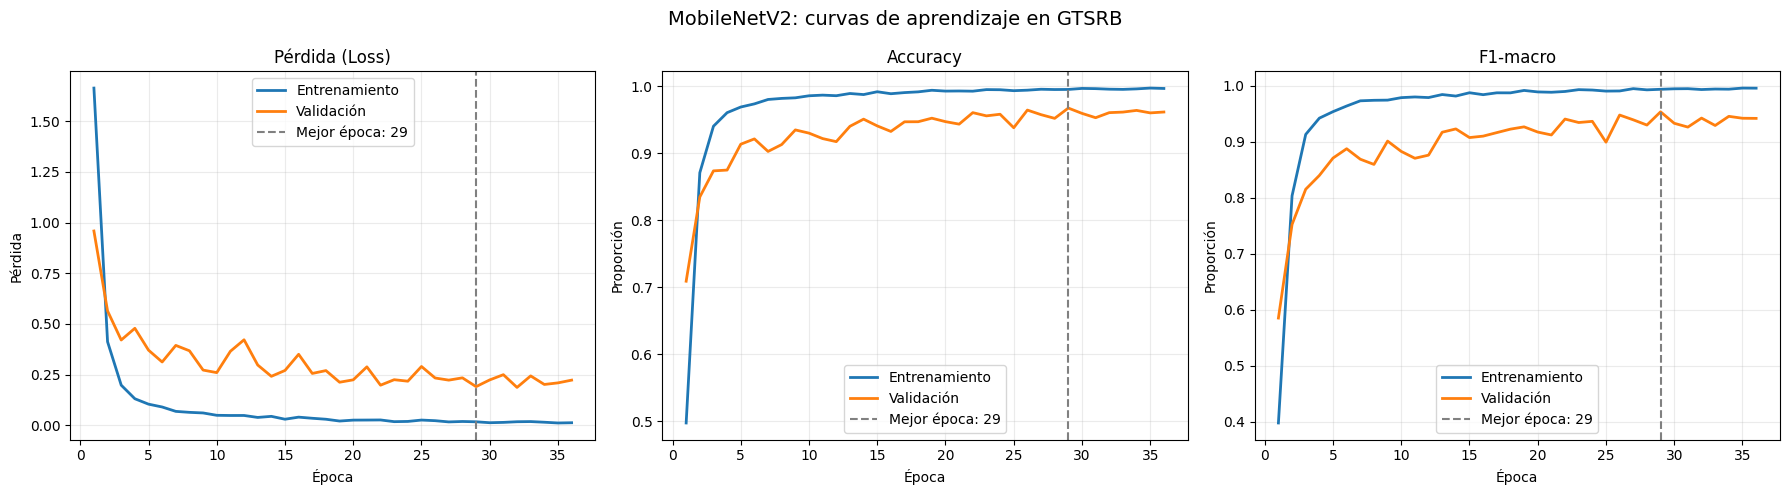

MEJOR CHECKPOINT DE MOBILENETV2
Época: 29
Train accuracy: 0.995076
Validation accuracy: 0.967266
Validation F1-macro: 0.953674
Validation loss: 0.191054
Épocas ejecutadas: 36
Checkpoint verificado: True
Figura guardada: True


In [34]:

# PASO 32: Curvas de aprendizaje de MobileNetV2.
# Se utiliza el historial del entrenamiento ya completado.

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# 1. Localizar resultados en Google Drive.
PROYECTO_DRIVE = Path(
    "/content/drive/MyDrive/Proyecto_VC_GTSRB"
)

RESULTADOS = PROYECTO_DRIVE / "resultados"

ruta_historial = (
    RESULTADOS / "MobileNetV2_seed42_historial.csv"
)

ruta_checkpoint = (
    PROYECTO_DRIVE
    / "checkpoints/MobileNetV2_seed42_best.pth"
)

assert ruta_historial.is_file(), "Falta el historial."
assert ruta_checkpoint.is_file(), "Falta el checkpoint."

# 2. Recuperar historial y mejor checkpoint.
historial = pd.read_csv(ruta_historial)

checkpoint = torch.load(
    ruta_checkpoint,
    map_location="cpu",
    weights_only=True
)

# 3. Comprobar la mejor época.
mejor_fila = historial.loc[
    historial["val_f1_macro"].idxmax()
]

mejor_epoca = int(mejor_fila["epoca"])

assert len(historial) == 36
assert mejor_epoca == checkpoint["epoca"]
assert np.isclose(
    mejor_fila["val_f1_macro"],
    checkpoint["val_f1_macro"]
)

# 4. Crear curvas de loss, accuracy y F1-macro.
metricas = [
    ("train_loss", "val_loss", "Pérdida (Loss)"),
    ("train_accuracy", "val_accuracy", "Accuracy"),
    ("train_f1_macro", "val_f1_macro", "F1-macro")
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (col_train, col_val, titulo) in zip(
    axes, metricas
):

    ax.plot(
        historial["epoca"],
        historial[col_train],
        label="Entrenamiento",
        linewidth=2
    )

    ax.plot(
        historial["epoca"],
        historial[col_val],
        label="Validación",
        linewidth=2
    )

    ax.axvline(
        mejor_epoca,
        color="gray",
        linestyle="--",
        label=f"Mejor época: {mejor_epoca}"
    )

    ax.set_title(titulo)
    ax.set_xlabel("Época")
    ax.grid(alpha=0.25)
    ax.legend()

axes[0].set_ylabel("Pérdida")
axes[1].set_ylabel("Proporción")
axes[2].set_ylabel("Proporción")

fig.suptitle(
    "MobileNetV2: curvas de aprendizaje en GTSRB",
    fontsize=14
)

plt.tight_layout()

# 5. Guardar figura en Drive.
ruta_figura = (
    RESULTADOS / "MobileNetV2_curvas_aprendizaje.png"
)

fig.savefig(
    ruta_figura,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# 6. Presentar métricas del mejor checkpoint.
print("MEJOR CHECKPOINT DE MOBILENETV2")
print("Época:", mejor_epoca)
print(
    "Train accuracy:",
    round(mejor_fila["train_accuracy"], 6)
)
print(
    "Validation accuracy:",
    round(mejor_fila["val_accuracy"], 6)
)
print(
    "Validation F1-macro:",
    round(mejor_fila["val_f1_macro"], 6)
)
print(
    "Validation loss:",
    round(mejor_fila["val_loss"], 6)
)
print("Épocas ejecutadas:", len(historial))
print("Checkpoint verificado:", ruta_checkpoint.is_file())
print("Figura guardada:", ruta_figura.is_file())


### Interpretación del Paso 32: Curvas de aprendizaje de MobileNetV2

MobileNetV2 presentó una convergencia progresiva, con una reducción considerable de la pérdida de entrenamiento y mejoras en accuracy y F1-macro. Las métricas de validación mostraron fluctuaciones y una diferencia respecto al entrenamiento, evidenciando limitaciones de generalización. La época 29 registró el mejor F1-macro de validación (0.953674), con una exactitud de 0.967266 y una pérdida de 0.191054. El entrenamiento finalizó en la época 36 mediante early stopping, conservándose correctamente el checkpoint seleccionado.

CHECKPOINT CARGADO
Modelo: MobileNetV2
Época: 29
F1-macro guardado: 0.953674

RESULTADOS GLOBALES EN VALIDACIÓN
Imágenes evaluadas: 8340
Accuracy: 0.967266
F1-macro: 0.953674
Errores: 273
Aciertos: 8067

10 CLASES CON MENOR RECALL


,ClassId,Soporte,Precision,Recall,F1
19,19,60,0.8788,0.4833,0.6237
30,30,90,0.9848,0.7222,0.8333
29,29,60,0.9020,0.7667,0.8288
32,32,60,0.9787,0.7667,0.8598
15,15,150,1.0000,0.7933,0.8848
9,9,300,0.9808,0.8533,0.9127
3,3,300,0.9313,0.9033,0.9171
20,20,90,0.9881,0.9222,0.9540
36,36,90,1.0000,0.9444,0.9714
41,41,60,0.7917,0.9500,0.8636



10 CLASES CON MENOR F1


,ClassId,Soporte,Precision,Recall,F1
19,19,60,0.8788,0.4833,0.6237
29,29,60,0.9020,0.7667,0.8288
30,30,90,0.9848,0.7222,0.8333
32,32,60,0.9787,0.7667,0.8598
23,23,120,0.7785,0.9667,0.8625
41,41,60,0.7917,0.9500,0.8636
15,15,150,1.0000,0.7933,0.8848
9,9,300,0.9808,0.8533,0.9127
3,3,300,0.9313,0.9033,0.9171
5,5,390,0.9082,0.9641,0.9353


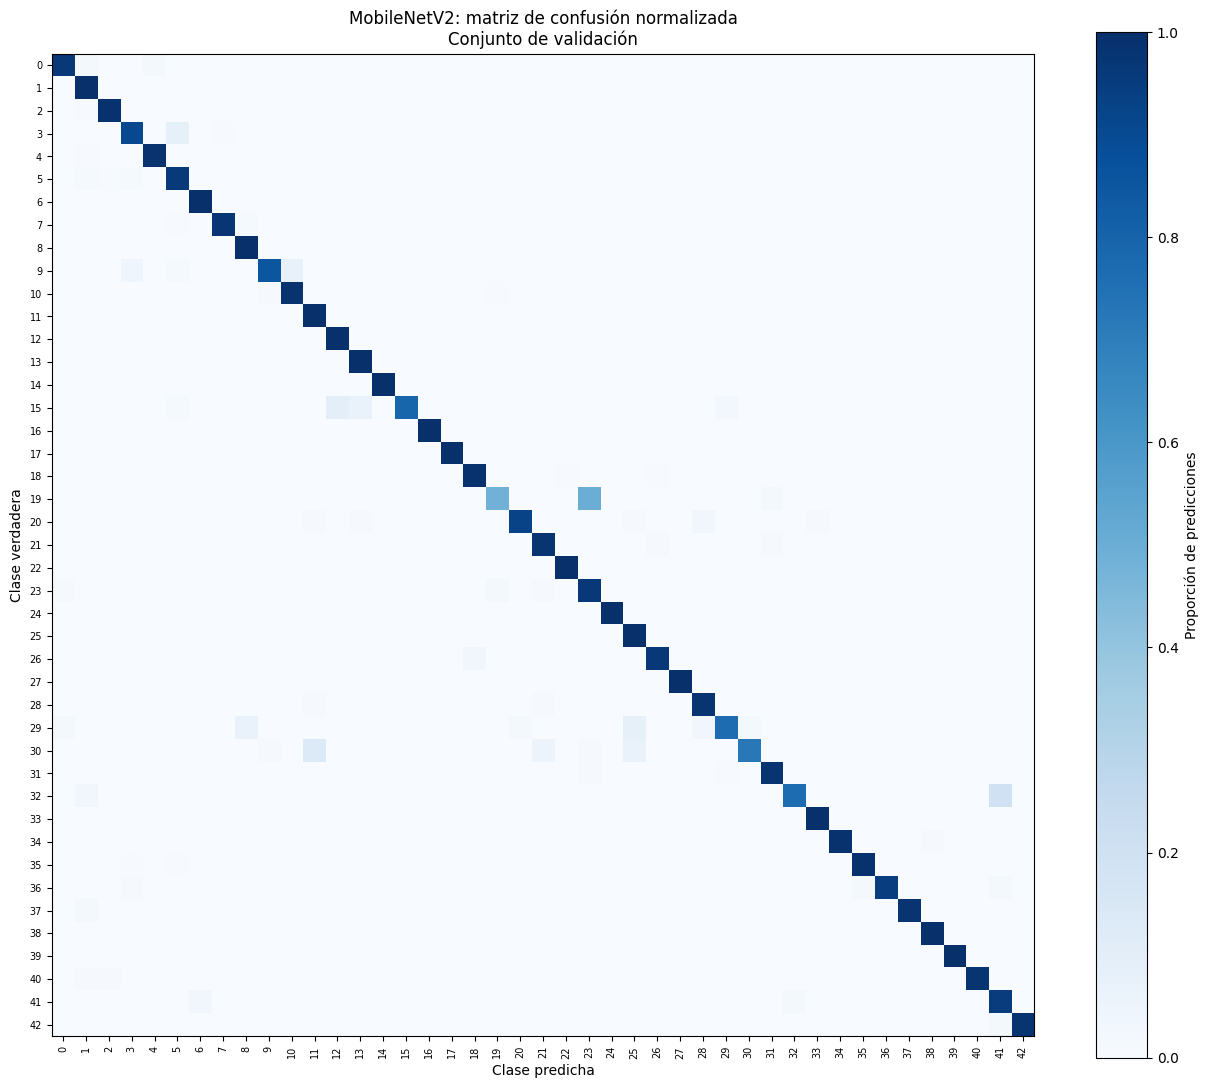


10 CONFUSIONES MÁS FRECUENTES


,Clase_real,Clase_predicha,Errores
41,19,23,30
6,3,5,25
28,9,10,23
36,15,12,15
25,9,3,12
70,32,41,12
63,30,11,12
37,15,13,10
66,30,25,6
16,5,3,6



CLASES DE INTERÉS


,ClassId,Soporte,Precision,Recall,F1
9,9,300,0.9808,0.8533,0.9127
15,15,150,1.0000,0.7933,0.8848
19,19,60,0.8788,0.4833,0.6237
30,30,90,0.9848,0.7222,0.8333
36,36,90,1.0000,0.9444,0.9714



ARCHIVOS GENERADOS
Matriz de confusión: True
Métricas por clase: True
Matriz numérica: True
Conjunto test utilizado: NO


In [35]:

# PASO 33: Evaluación detallada de MobileNetV2
# Mejor checkpoint: época 29.
# Evaluación exclusiva sobre validación.
# No se utiliza el conjunto de prueba.

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from torchvision import models
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    precision_recall_fscore_support
)

# 1. Definir dispositivo y rutas.
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

PROYECTO_DRIVE = Path(
    "/content/drive/MyDrive/Proyecto_VC_GTSRB"
)

RESULTADOS = PROYECTO_DRIVE / "resultados"
RESULTADOS.mkdir(parents=True, exist_ok=True)

ruta_checkpoint = (
    PROYECTO_DRIVE
    / "checkpoints/MobileNetV2_seed42_best.pth"
)

assert ruta_checkpoint.is_file(), (
    "No se encontró el checkpoint de MobileNetV2."
)

# 2. Recuperar el checkpoint de la mejor época.
checkpoint = torch.load(
    ruta_checkpoint,
    map_location=DEVICE,
    weights_only=True
)

# 3. Reconstruir la arquitectura exacta
# utilizada durante el entrenamiento.
modelo_eval = models.mobilenet_v2(
    weights=None,
    num_classes=43
).to(DEVICE)

modelo_eval.load_state_dict(
    checkpoint["model_state_dict"]
)

# Activar modo evaluación para BatchNorm y Dropout.
modelo_eval.eval()

print("CHECKPOINT CARGADO")
print("Modelo:", checkpoint["modelo"])
print("Época:", checkpoint["epoca"])
print(
    "F1-macro guardado:",
    round(checkpoint["val_f1_macro"], 6)
)

# 4. Obtener predicciones sobre validación.
# Utilizamos AMP en GPU para reproducir
# las condiciones numéricas del entrenamiento.
reales = []
predichas = []

with torch.inference_mode(), torch.amp.autocast(
    device_type=DEVICE.type,
    enabled=DEVICE.type == "cuda"
):

    for imagenes, etiquetas in val_loader:

        imagenes = imagenes.to(
            DEVICE,
            non_blocking=DEVICE.type == "cuda"
        )

        salidas = modelo_eval(imagenes)
        predicciones = salidas.argmax(dim=1)

        reales.extend(
            etiquetas.cpu().tolist()
        )

        predichas.extend(
            predicciones.cpu().tolist()
        )

y_true = np.asarray(reales)
y_pred = np.asarray(predichas)

clases = np.arange(43)

# 5. Verificar el tamaño y las etiquetas.
assert len(y_true) == 8340
assert len(y_pred) == 8340
assert np.isin(y_true, clases).all()
assert np.isin(y_pred, clases).all()

# 6. Calcular métricas globales.
accuracy = accuracy_score(y_true, y_pred)

f1_macro = f1_score(
    y_true,
    y_pred,
    labels=clases,
    average="macro",
    zero_division=0
)

errores = int((y_true != y_pred).sum())

print("\nRESULTADOS GLOBALES EN VALIDACIÓN")
print("Imágenes evaluadas:", len(y_true))
print("Accuracy:", round(accuracy, 6))
print("F1-macro:", round(f1_macro, 6))
print("Errores:", errores)
print("Aciertos:", len(y_true) - errores)

# 7. Verificar coincidencia con el checkpoint.
assert np.isclose(
    accuracy,
    checkpoint["val_accuracy"],
    atol=1e-6
), "El accuracy no coincide con el checkpoint."

assert np.isclose(
    f1_macro,
    checkpoint["val_f1_macro"],
    atol=1e-6
), "El F1-macro no coincide con el checkpoint."

# 8. Calcular Precision, Recall y F1 por clase.
precision, recall, f1, soporte = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=clases,
        zero_division=0
    )
)

metricas_mobilenet = pd.DataFrame({
    "ClassId": clases,
    "Soporte": soporte,
    "Precision": precision,
    "Recall": recall,
    "F1": f1
})

print("\n10 CLASES CON MENOR RECALL")
display(
    metricas_mobilenet
    .sort_values(["Recall", "ClassId"])
    .head(10)
    .round(4)
)

print("\n10 CLASES CON MENOR F1")
display(
    metricas_mobilenet
    .sort_values(["F1", "ClassId"])
    .head(10)
    .round(4)
)

# 9. Construir la matriz de confusión.
matriz = confusion_matrix(
    y_true,
    y_pred,
    labels=clases
)

# Normalizar cada fila por el soporte real.
matriz_normalizada = (
    matriz / matriz.sum(axis=1, keepdims=True)
)

fig, ax = plt.subplots(figsize=(13, 11))

imagen = ax.imshow(
    matriz_normalizada,
    cmap="Blues",
    interpolation="nearest",
    vmin=0,
    vmax=1
)

fig.colorbar(
    imagen,
    ax=ax,
    label="Proporción de predicciones"
)

ax.set_title(
    "MobileNetV2: matriz de confusión normalizada\n"
    "Conjunto de validación"
)

ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase verdadera")

ax.set_xticks(clases)
ax.set_yticks(clases)

ax.tick_params(
    axis="x",
    labelrotation=90,
    labelsize=7
)

ax.tick_params(
    axis="y",
    labelsize=7
)

plt.tight_layout()

# 10. Guardar la figura para el artículo.
ruta_figura = (
    RESULTADOS
    / "MobileNetV2_matriz_confusion_val.png"
)

fig.savefig(
    ruta_figura,
    dpi=220,
    bbox_inches="tight"
)

plt.show()

# 11. Guardar métricas por clase y matriz numérica.
ruta_metricas = (
    RESULTADOS
    / "MobileNetV2_metricas_por_clase_val.csv"
)

ruta_matriz = (
    RESULTADOS
    / "MobileNetV2_matriz_confusion_val.csv"
)

metricas_mobilenet.to_csv(
    ruta_metricas,
    index=False
)

pd.DataFrame(
    matriz,
    index=clases,
    columns=clases
).to_csv(ruta_matriz)

# 12. Identificar confusiones más frecuentes.
matriz_errores = matriz.copy()

# Excluir aciertos de la diagonal.
np.fill_diagonal(matriz_errores, 0)

filas, columnas = np.where(
    matriz_errores > 0
)

tabla_confusiones = pd.DataFrame({
    "Clase_real": filas,
    "Clase_predicha": columnas,
    "Errores": matriz_errores[filas, columnas]
})

print("\n10 CONFUSIONES MÁS FRECUENTES")

display(
    tabla_confusiones
    .sort_values(
        "Errores",
        ascending=False
    )
    .head(10)
)

# 13. Examinar las clases que fueron
# problemáticas para los modelos anteriores.
clases_interes = [9, 15, 19, 30, 36]

print("\nCLASES DE INTERÉS")
display(
    metricas_mobilenet[
        metricas_mobilenet["ClassId"].isin(
            clases_interes
        )
    ].sort_values("ClassId").round(4)
)

# 14. Confirmar la generación de archivos.
print("\nARCHIVOS GENERADOS")
print("Matriz de confusión:", ruta_figura.is_file())
print("Métricas por clase:", ruta_metricas.is_file())
print("Matriz numérica:", ruta_matriz.is_file())
print("Conjunto test utilizado: NO")


### Interpretación del Paso 33: Evaluación detallada de MobileNetV2

MobileNetV2 alcanzó una exactitud de 96.73 % y un F1-macro de 95.37 % sobre 8 340 imágenes de validación, registrando 273 errores. La matriz de confusión evidencia un desempeño elevado en la mayoría de las clases, aunque persisten dificultades en las clases 19, 30, 29, 32 y 15. La clase 19 presentó el menor recall (48.33 %), con una confusión predominante hacia la clase 23. En la comparación global, MobileNetV2 superó a la CNN personalizada, pero obtuvo resultados inferiores a ResNet18. El conjunto de prueba independiente permaneció sin utilizar.

In [36]:

# PASO 34: Exportar los resultados de MobileNetV2
# para reunirlos con CNN personalizada y ResNet18.

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files
import hashlib

# 1. Directorio del experimento en Google Drive.
BASE = Path(
    "/content/drive/MyDrive/Proyecto_VC_GTSRB"
)

# 2. Archivos que necesitamos conservar.
archivos = [
    "config_entrenamiento.json",
    "checkpoints/MobileNetV2_seed42_best.pth",
    "resultados/MobileNetV2_seed42_historial.csv",
    "resultados/MobileNetV2_curvas_aprendizaje.png",
    "resultados/MobileNetV2_matriz_confusion_val.png",
    "resultados/MobileNetV2_metricas_por_clase_val.csv",
    "resultados/MobileNetV2_matriz_confusion_val.csv"
]

# 3. Verificar archivos antes de comprimir.
faltantes = [
    nombre for nombre in archivos
    if not (BASE / nombre).is_file()
]

if faltantes:
    raise FileNotFoundError(
        f"Faltan archivos: {faltantes}"
    )

# 4. Crear archivo ZIP en el entorno de Colab.
RUTA_ZIP = Path(
    "/content/GTSRB_MobileNetV2_resultados.zip"
)

with ZipFile(RUTA_ZIP, "w", ZIP_DEFLATED) as zipf:

    for nombre in archivos:
        zipf.write(
            BASE / nombre,
            arcname=nombre
        )

# 5. Verificar integridad del archivo comprimido.
with ZipFile(RUTA_ZIP) as zipf:
    assert zipf.testzip() is None
    assert set(zipf.namelist()) == set(archivos)

# 6. Calcular huella SHA-256 para integridad.
sha256 = hashlib.sha256()

with open(RUTA_ZIP, "rb") as f:
    for bloque in iter(lambda: f.read(1024 * 1024), b""):
        sha256.update(bloque)

print("EXPORTACIÓN COMPLETADA")
print("Archivos incluidos:", len(archivos))
print(
    "Tamaño ZIP (MB):",
    round(RUTA_ZIP.stat().st_size / 1024**2, 2)
)
print("SHA-256:", sha256.hexdigest())
print("Integridad ZIP: OK")

# 7. Descargar el paquete a tu computadora.
files.download(str(RUTA_ZIP))


EXPORTACIÓN COMPLETADA
Archivos incluidos: 7
Tamaño ZIP (MB): 24.54
SHA-256: 8f17dbc8c9dc69bd5890772c4d1ca9e343cb6cf4d4134be0f6b0c94d1e3780a6
Integridad ZIP: OK


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:

# PASO 36: Unificación de los tres modelos GTSRB.
# No entrena modelos ni utiliza el conjunto de prueba.

from pathlib import Path, PurePosixPath
from zipfile import ZipFile
from google.colab import drive
import shutil
import hashlib
import json
import torch
import pandas as pd

# 1. Montar Google Drive.
drive.mount("/content/drive")

BASE = Path(
    "/content/drive/MyDrive/Proyecto_VC_GTSRB"
)

RESPALDOS = BASE / "respaldos_modelos"
CONSOLIDADO = BASE / "modelos_consolidados"

# 2. Localizar los archivos ZIP subidos.
zip_anteriores = (
    RESPALDOS / "GTSRB_CNN_ResNet18_resultados.zip"
)

zip_mobilenet = (
    RESPALDOS / "GTSRB_MobileNetV2_resultados.zip"
)

for ruta in [zip_anteriores, zip_mobilenet]:
    assert ruta.is_file(), f"No se encontró: {ruta.name}"

print("ARCHIVOS ZIP LOCALIZADOS")

for ruta in [zip_anteriores, zip_mobilenet]:
    print(
        ruta.name,
        f"({ruta.stat().st_size / 1024**2:.2f} MB)"
    )

# 3. Verificar la integridad de ambos ZIP.
with ZipFile(zip_anteriores) as z1, \
     ZipFile(zip_mobilenet) as z2:

    assert z1.testzip() is None
    assert z2.testzip() is None

    # Confirmar los checkpoints esperados.
    requeridos_1 = {
        "checkpoints/CNNPersonalizada_seed42_best.pth",
        "checkpoints/ResNet18_seed42_best.pth",
        "resultados/CNNPersonalizada_seed42_historial.csv",
        "resultados/ResNet18_seed42_historial.csv"
    }

    requeridos_2 = {
        "checkpoints/MobileNetV2_seed42_best.pth",
        "resultados/MobileNetV2_seed42_historial.csv"
    }

    assert requeridos_1.issubset(set(z1.namelist()))
    assert requeridos_2.issubset(set(z2.namelist()))

    # Comparar las configuraciones cuando ambas existen.
    if (
        "config_entrenamiento.json" in z1.namelist()
        and "config_entrenamiento.json" in z2.namelist()
    ):
        config_1 = json.loads(
            z1.read("config_entrenamiento.json")
        )
        config_2 = json.loads(
            z2.read("config_entrenamiento.json")
        )

        assert config_1 == config_2, (
            "Las configuraciones experimentales difieren. "
            "Revisarlas antes de unificar."
        )

    print("\nINTEGRIDAD DE LOS ZIP: OK")
    print("Archivos obligatorios: OK")
    print("Configuración experimental: verificada")

# 4. Función para calcular SHA-256 de un archivo.
def sha256_archivo(ruta):
    h = hashlib.sha256()

    with open(ruta, "rb") as f:
        for bloque in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(bloque)

    return h.hexdigest()

# 5. Extraer los resultados sin sobrescribir archivos.
CONSOLIDADO.mkdir(parents=True, exist_ok=True)

def incorporar_zip(ruta_zip, incluir_config=True):

    with ZipFile(ruta_zip) as zf:

        for miembro in zf.infolist():

            if miembro.is_dir():
                continue

            nombre = miembro.filename
            ruta_relativa = PurePosixPath(nombre)

            # Impedir rutas inseguras.
            assert (
                not ruta_relativa.is_absolute()
                and ".." not in ruta_relativa.parts
            ), f"Ruta insegura: {nombre}"

            # Usar la configuración del primer ZIP.
            if (
                nombre == "config_entrenamiento.json"
                and not incluir_config
            ):
                continue

            destino = (
                CONSOLIDADO / Path(*ruta_relativa.parts)
            )

            destino.parent.mkdir(
                parents=True, exist_ok=True
            )

            # Extraer primero en un archivo temporal.
            temporal = destino.with_name(
                destino.name + ".temporal"
            )

            with zf.open(miembro) as origen, \
                 open(temporal, "wb") as salida:
                shutil.copyfileobj(origen, salida)

            if destino.exists():

                # Si ya existe, exigir contenido idéntico.
                if (
                    sha256_archivo(destino)
                    != sha256_archivo(temporal)
                ):
                    temporal.unlink()

                    raise FileExistsError(
                        f"Conflicto: {destino}. "
                        "No se sobrescribió."
                    )

                temporal.unlink()

            else:
                temporal.replace(destino)

# Importar CNN y ResNet18 desde la cuenta anterior.
incorporar_zip(zip_anteriores)

# Importar MobileNetV2 desde la cuenta nueva.
incorporar_zip(
    zip_mobilenet,
    incluir_config=False
)

print("\nRESULTADOS UNIFICADOS")

# 6. Abrir y verificar los tres checkpoints.
modelos = {
    "CNN personalizada": {
        "archivo": "CNNPersonalizada_seed42_best.pth",
        "nombre_interno": "CNNPersonalizada",
        "epoca": 38,
        "f1": 0.934810
    },
    "ResNet18": {
        "archivo": "ResNet18_seed42_best.pth",
        "nombre_interno": "ResNet18",
        "epoca": 13,
        "f1": 0.974288
    },
    "MobileNetV2": {
        "archivo": "MobileNetV2_seed42_best.pth",
        "nombre_interno": "MobileNetV2",
        "epoca": 29,
        "f1": 0.953674
    }
}

resumen = []

for nombre, esperado in modelos.items():

    ruta = (
        CONSOLIDADO
        / "checkpoints"
        / esperado["archivo"]
    )

    assert ruta.is_file()

    checkpoint = torch.load(
        ruta,
        map_location="cpu",
        weights_only=True
    )

    assert (
        checkpoint["modelo"]
        == esperado["nombre_interno"]
    )

    assert checkpoint["epoca"] == esperado["epoca"]

    assert abs(
        checkpoint["val_f1_macro"] - esperado["f1"]
    ) < 1e-5

    assert "model_state_dict" in checkpoint

    # Verificar también que exista el historial.
    ruta_historial = (
        CONSOLIDADO
        / "resultados"
        / f'{esperado["nombre_interno"]}_seed42_historial.csv'
    )

    assert ruta_historial.is_file()

    resumen.append({
        "Modelo": nombre,
        "Mejor época": checkpoint["epoca"],
        "Accuracy": checkpoint["val_accuracy"],
        "F1-macro": checkpoint["val_f1_macro"],
        "Checkpoint": "OK",
        "Historial": "OK"
    })

# 7. Presentar los resultados verificados.
tabla = pd.DataFrame(resumen)

display(tabla.round(6))

print("\nVERIFICACIÓN FINAL")
print("Modelos recuperados:", len(resumen))
print("Checkpoints legibles:", True)
print("Historiales disponibles:", True)
print("Conjunto de prueba utilizado: NO")
print("Entrenamientos repetidos: NO")
print("Carpeta consolidada:", CONSOLIDADO)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ARCHIVOS ZIP LOCALIZADOS
GTSRB_CNN_ResNet18_resultados.zip (118.93 MB)
GTSRB_MobileNetV2_resultados.zip (24.54 MB)

INTEGRIDAD DE LOS ZIP: OK
Archivos obligatorios: OK
Configuración experimental: verificada

RESULTADOS UNIFICADOS


,Modelo,Mejor época,Accuracy,F1-macro,Checkpoint,Historial
0,CNN personalizada,38,0.945683,0.934810,OK,OK
1,ResNet18,13,0.983573,0.974288,OK,OK
2,MobileNetV2,29,0.967266,0.953674,OK,OK



VERIFICACIÓN FINAL
Modelos recuperados: 3
Checkpoints legibles: True
Historiales disponibles: True
Conjunto de prueba utilizado: NO
Entrenamientos repetidos: NO
Carpeta consolidada: /content/drive/MyDrive/Proyecto_VC_GTSRB/modelos_consolidados


### Interpretación del Paso 36: Consolidación de modelos

Se recuperaron y consolidaron satisfactoriamente los checkpoints, historiales y resultados de las tres arquitecturas: CNN personalizada, ResNet18 y MobileNetV2. Se verificó la integridad de los archivos y la consistencia de las configuraciones experimentales. La comparación preliminar sobre validación identificó a ResNet18 como el modelo con mayor F1-macro (97.43 %), seguido de MobileNetV2 (95.37 %) y la CNN personalizada (93.48 %). No fue necesario repetir los entrenamientos.

In [38]:

# PASO 37: Verificación del conjunto de prueba GTSRB.
# No se realiza entrenamiento ni inferencia.

from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image

# 1. Directorios del proyecto.
ROOT = Path("/content/GTSRB-Preprocesamiento")

CONSOLIDADO = Path(
    "/content/drive/MyDrive/Proyecto_VC_GTSRB/modelos_consolidados"
)

# 2. Verificar los tres checkpoints consolidados.
checkpoints = {
    "CNN personalizada": (
        "CNNPersonalizada_seed42_best.pth"
    ),
    "ResNet18": (
        "ResNet18_seed42_best.pth"
    ),
    "MobileNetV2": (
        "MobileNetV2_seed42_best.pth"
    )
}

print("VERIFICACIÓN DE MODELOS")

for nombre, archivo in checkpoints.items():

    ruta = CONSOLIDADO / "checkpoints" / archivo

    print(
        f"{nombre}:",
        "OK" if ruta.is_file() else "FALTANTE"
    )

    assert ruta.is_file()

# 3. Localizar el manifiesto oficial preprocesado.
ruta_manifest = (
    ROOT / "data/processed/test_manifest.csv"
)

print("\nVERIFICACIÓN DEL DATASET TEST")

if not ruta_manifest.is_file():
    print("Manifiesto test: NO DISPONIBLE")
    print(
        "Es necesario recuperar el conjunto de prueba "
        "antes de realizar la evaluación final."
    )

else:
    test_manifest = pd.read_csv(ruta_manifest)

    print("Manifiesto test: OK")
    print("Registros:", len(test_manifest))
    print("Columnas:", test_manifest.columns.tolist())

    # 4. Comprobar cantidades y etiquetas.
    assert len(test_manifest) == 12630
    assert test_manifest["ClassId"].notna().all()

    etiquetas = test_manifest["ClassId"].astype(int)

    assert etiquetas.between(0, 42).all()
    assert etiquetas.nunique() == 43

    print("Clases:", etiquetas.nunique())
    print("Etiquetas válidas: True")

    # 5. Comprobar existencia de todas las imágenes.
    rutas = [
        ROOT / ruta
        for ruta in test_manifest["RutaProcesada"]
    ]

    faltantes = [
        ruta for ruta in rutas
        if not ruta.is_file()
    ]

    print("Imágenes encontradas:",
          len(rutas) - len(faltantes))
    print("Imágenes faltantes:", len(faltantes))

    # 6. Verificar formato en muestras distribuidas.
    if not faltantes:

        indices = np.linspace(
            0, len(rutas) - 1,
            20, dtype=int
        )

        formatos_correctos = True

        for indice in indices:

            with Image.open(rutas[indice]) as imagen:

                if (
                    imagen.size != (48, 48)
                    or imagen.mode != "RGB"
                ):
                    formatos_correctos = False
                    break

        print(
            "Formato RGB 48x48 verificado:",
            formatos_correctos
        )

        assert formatos_correctos

    # 7. Verificación final.
    print("\nRESUMEN")
    print("Checkpoints consolidados: 3")
    print("Test manifest:", len(test_manifest))
    print("Imágenes faltantes:", len(faltantes))
    print("Conjunto test evaluado: NO")


VERIFICACIÓN DE MODELOS
CNN personalizada: OK
ResNet18: OK
MobileNetV2: OK

VERIFICACIÓN DEL DATASET TEST
Manifiesto test: OK
Registros: 12630
Columnas: ['Conjunto', 'RutaOriginal', 'RutaProcesada', 'ClassId']
Clases: 43
Etiquetas válidas: True
Imágenes encontradas: 12630
Imágenes faltantes: 0
Formato RGB 48x48 verificado: True

RESUMEN
Checkpoints consolidados: 3
Test manifest: 12630
Imágenes faltantes: 0
Conjunto test evaluado: NO


### Interpretación del Paso 37: Verificación del conjunto de prueba

Se verificó satisfactoriamente la disponibilidad de los tres checkpoints consolidados y la integridad del conjunto de prueba independiente de GTSRB. Se comprobaron 12 630 imágenes preprocesadas, pertenecientes a 43 clases, sin archivos faltantes ni problemas en las muestras verificadas. El conjunto de prueba permaneció sin evaluar durante el entrenamiento y la selección de modelos.

EVALUACIÓN FINAL GTSRB
Dispositivo: cuda

EVALUANDO: CNNPersonalizada
Accuracy: 0.956849
F1-macro: 0.939788
Errores: 545

Cinco clases con menor recall:


,ClassId,Soporte,Precision,Recall,F1
39,39,90,1.0000,0.6667,0.8000
30,30,150,0.9912,0.7467,0.8517
22,22,120,1.0000,0.7500,0.8571
27,27,60,1.0000,0.7833,0.8785
19,19,60,0.9074,0.8167,0.8596



EVALUANDO: ResNet18
Accuracy: 0.981156
F1-macro: 0.975291
Errores: 238

Cinco clases con menor recall:


,ClassId,Soporte,Precision,Recall,F1
30,30,150,1.0000,0.6600,0.7952
26,26,180,0.9871,0.8500,0.9134
21,21,90,0.9643,0.9000,0.9310
22,22,120,1.0000,0.9167,0.9565
3,3,450,1.0000,0.9267,0.9619



EVALUANDO: MobileNetV2
Accuracy: 0.955899
F1-macro: 0.931028
Errores: 557

Cinco clases con menor recall:


,ClassId,Soporte,Precision,Recall,F1
27,27,60,0.8710,0.4500,0.5934
30,30,150,0.9787,0.6133,0.7541
21,21,90,0.6588,0.6222,0.6400
42,42,90,1.0000,0.7111,0.8312
0,0,60,1.0000,0.8333,0.9091



COMPARACIÓN FINAL EN TEST


,Modelo,Parametros,Accuracy,Precision_macro,Recall_macro,F1_macro,Errores,Aciertos,Tiempo_forward_s,ms_por_imagen_en_lote,Dispositivo,Precision_numerica
0,ResNet18,11190891,0.981156,0.978277,0.975706,0.975291,238,12392,2.895217,0.229233,cuda,AMP
1,CNNPersonalizada,99243,0.956849,0.956621,0.929932,0.939788,545,12085,0.938424,0.074301,cuda,AMP
2,MobileNetV2,2278955,0.955899,0.946519,0.925058,0.931028,557,12073,5.375730,0.425632,cuda,AMP


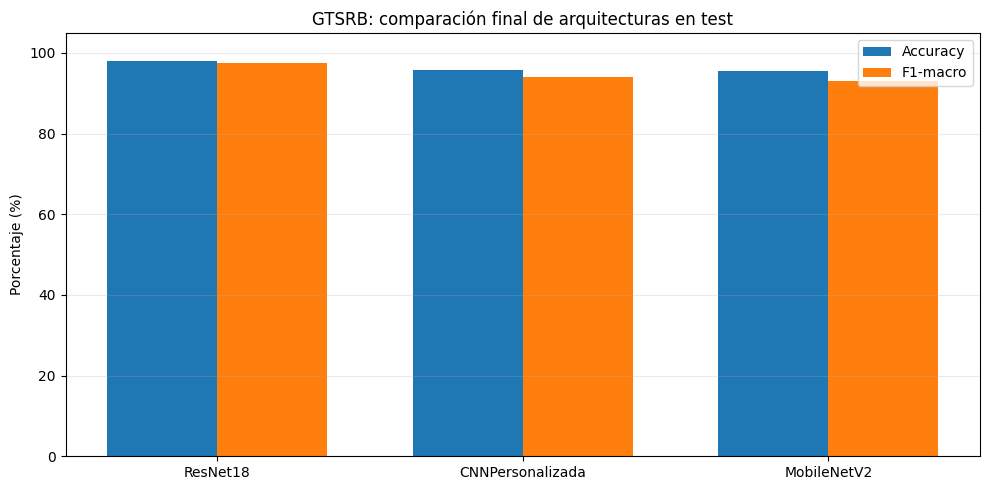

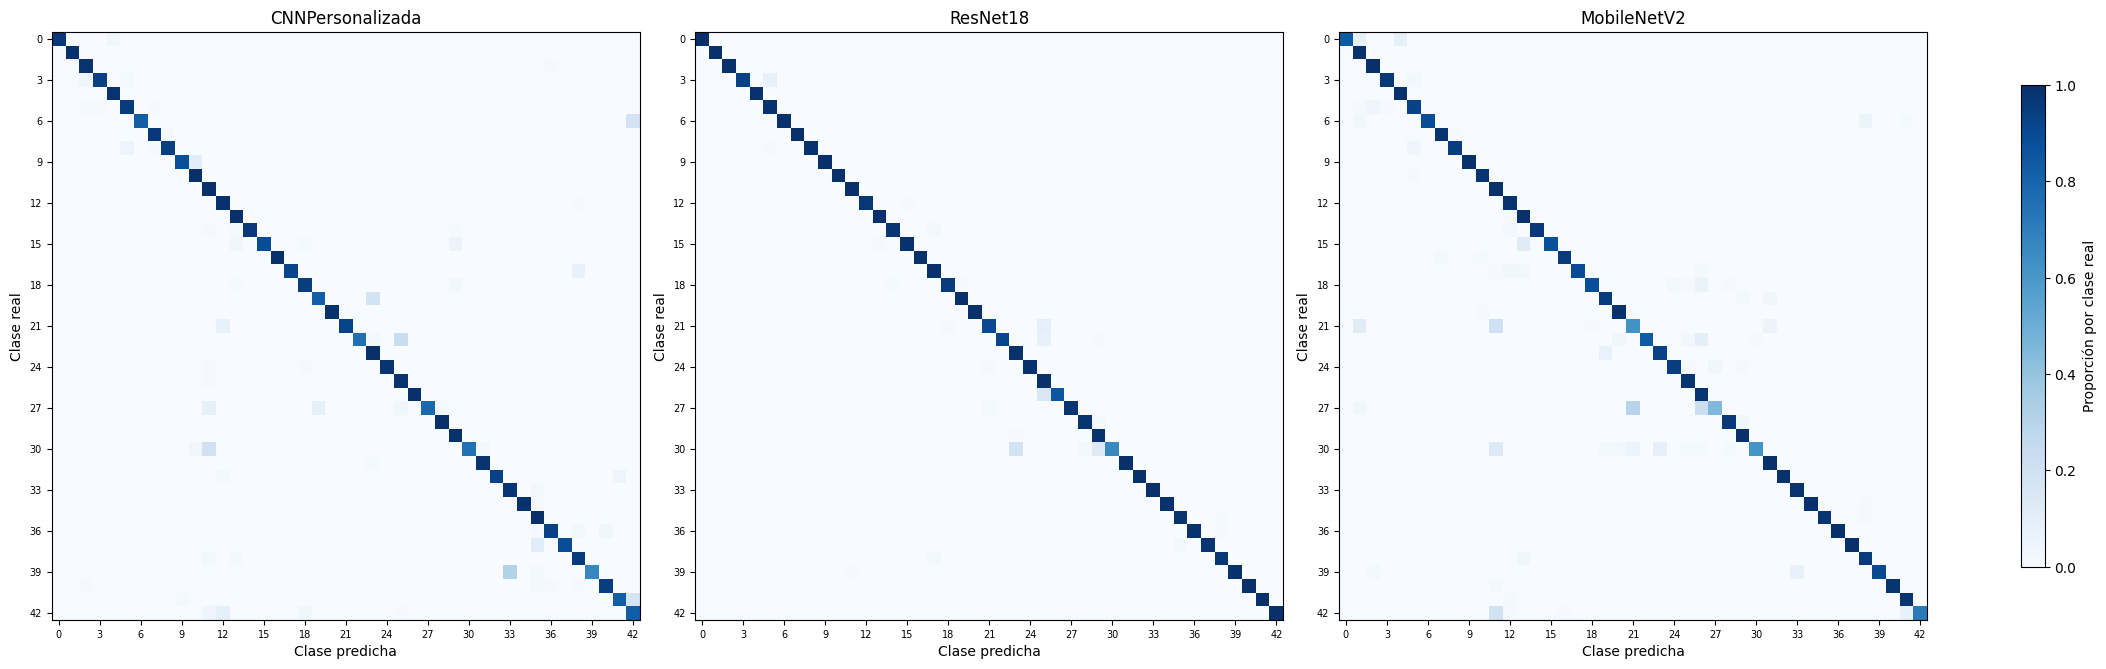


EVALUACIÓN FINAL COMPLETADA
Modelos evaluados: 3
Imágenes por modelo: 12630
Resultados guardados: /content/drive/MyDrive/Proyecto_VC_GTSRB/evaluacion_final_test
Entrenamientos realizados en este paso: 0


In [39]:

# PASO 38: Evaluación final de tres arquitecturas en GTSRB.
# No realiza entrenamiento ni modifica los checkpoints.
# Se utiliza el mismo test, normalización y dispositivo.

import os
import json
import time
import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from torchvision import models
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support,
    confusion_matrix
)

# 1. Configurar rutas y dispositivo.
ROOT = Path("/content/GTSRB-Preprocesamiento")

BASE = Path(
    "/content/drive/MyDrive/Proyecto_VC_GTSRB"
)

CONSOLIDADO = BASE / "modelos_consolidados"
RESULTADOS_TEST = BASE / "evaluacion_final_test"

RESULTADOS_TEST.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if DEVICE.type == "cpu":
    torch.set_num_threads(min(2, os.cpu_count() or 2))

print("EVALUACIÓN FINAL GTSRB")
print("Dispositivo:", DEVICE)

# 2. Recuperar la configuración original.
with open(
    CONSOLIDADO / "config_entrenamiento.json",
    encoding="utf-8"
) as f:
    config = json.load(f)

MEAN = np.asarray(
    config["normalizacion_media"],
    dtype=np.float32
)

STD = np.asarray(
    config["normalizacion_std"],
    dtype=np.float32
)

NUM_CLASSES = 43
BATCH_SIZE = config["batch_size"]
CLASES = np.arange(NUM_CLASSES)

# 3. Dataset independiente, sin Data Augmentation.
class GTSRBTestDataset(Dataset):

    def __init__(self, manifest_path):
        self.df = pd.read_csv(manifest_path)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, indice):

        registro = self.df.iloc[indice]

        ruta = ROOT / registro["RutaProcesada"]
        etiqueta = int(registro["ClassId"])

        with Image.open(ruta) as img:
            imagen = np.asarray(
                img.convert("RGB"),
                dtype=np.float32
            ) / 255.0

        # Normalización calculada solo con train.
        imagen = (imagen - MEAN) / STD

        # Convertir HWC a CHW para PyTorch.
        imagen = np.transpose(
            imagen, (2, 0, 1)
        ).copy()

        return torch.from_numpy(imagen), etiqueta


# 4. Crear DataLoader sin aumentos ni shuffle.
test_dataset = GTSRBTestDataset(
    ROOT / "data/processed/test_manifest.csv"
)

assert len(test_dataset) == 12630

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2 if DEVICE.type == "cuda" else 0,
    pin_memory=DEVICE.type == "cuda"
)

# 5. Reconstruir la CNN personalizada original.
class CNNPersonalizada(nn.Module):

    def __init__(self, num_classes=43):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


# 6. Reconstruir ResNet18 adaptada a 48x48.
def crear_resnet18():

    modelo = models.resnet18(weights=None)

    modelo.conv1 = nn.Conv2d(
        3, 64,
        kernel_size=3,
        stride=1,
        padding=1,
        bias=False
    )

    modelo.maxpool = nn.Identity()

    modelo.fc = nn.Linear(
        modelo.fc.in_features,
        NUM_CLASSES
    )

    return modelo


# 7. Definir las tres arquitecturas y checkpoints.
arquitecturas = {
    "CNNPersonalizada": {
        "constructor": lambda: CNNPersonalizada(43),
        "archivo": "CNNPersonalizada_seed42_best.pth",
        "epoca": 38
    },
    "ResNet18": {
        "constructor": crear_resnet18,
        "archivo": "ResNet18_seed42_best.pth",
        "epoca": 13
    },
    "MobileNetV2": {
        "constructor": lambda: models.mobilenet_v2(
            weights=None,
            num_classes=43
        ),
        "archivo": "MobileNetV2_seed42_best.pth",
        "epoca": 29
    }
}

# Verificar los tres checkpoints antes de evaluar.
for nombre, datos in arquitecturas.items():
    ruta = CONSOLIDADO / "checkpoints" / datos["archivo"]
    assert ruta.is_file(), f"Checkpoint faltante: {nombre}"

# 8. Preparar resultados.
resumen = []
matrices = {}

usar_amp = DEVICE.type == "cuda"

# 9. Evaluar cada modelo secuencialmente.
for nombre, datos in arquitecturas.items():

    print(f"\nEVALUANDO: {nombre}")

    ruta_checkpoint = (
        CONSOLIDADO / "checkpoints" / datos["archivo"]
    )

    checkpoint = torch.load(
        ruta_checkpoint,
        map_location="cpu",
        weights_only=True
    )

    assert checkpoint["modelo"] == nombre
    assert checkpoint["epoca"] == datos["epoca"]

    modelo = datos["constructor"]()

    modelo.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    modelo = modelo.to(DEVICE)
    modelo.eval()

    parametros = sum(
        p.numel() for p in modelo.parameters()
        if p.requires_grad
    )

    # 10. Calentamiento previo para reducir
    # el efecto de inicialización en las mediciones.
    muestra = torch.zeros(
        BATCH_SIZE, 3, 48, 48,
        device=DEVICE
    )

    with torch.inference_mode(), torch.amp.autocast(
        device_type=DEVICE.type,
        enabled=usar_amp
    ):
        for _ in range(5):
            _ = modelo(muestra)

    if usar_amp:
        torch.cuda.synchronize()

    reales = []
    predichas = []

    # Mediremos solo el tiempo de forward,
    # excluyendo lectura y transferencia de datos.
    tiempo_forward = 0.0

    # 11. Inferencia con el conjunto test completo.
    with torch.inference_mode(), torch.amp.autocast(
        device_type=DEVICE.type,
        enabled=usar_amp
    ):

        for imagenes, etiquetas in test_loader:

            imagenes = imagenes.to(
                DEVICE,
                non_blocking=usar_amp
            )

            if usar_amp:
                torch.cuda.synchronize()

            inicio = time.perf_counter()

            salidas = modelo(imagenes)

            if usar_amp:
                torch.cuda.synchronize()

            tiempo_forward += (
                time.perf_counter() - inicio
            )

            predicciones = salidas.argmax(dim=1)

            reales.extend(
                etiquetas.cpu().tolist()
            )

            predichas.extend(
                predicciones.cpu().tolist()
            )

    y_true = np.asarray(reales)
    y_pred = np.asarray(predichas)

    assert len(y_true) == 12630
    assert len(y_pred) == 12630

    # 12. Calcular métricas globales.
    accuracy = accuracy_score(y_true, y_pred)

    precision, recall, f1, soporte = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=CLASES,
            zero_division=0
        )
    )

    precision_macro = float(precision.mean())
    recall_macro = float(recall.mean())
    f1_macro = f1_score(
        y_true,
        y_pred,
        labels=CLASES,
        average="macro",
        zero_division=0
    )

    errores = int((y_true != y_pred).sum())

    # Tiempo promedio por imagen procesada en lotes.
    ms_imagen_lote = (
        tiempo_forward / len(y_true) * 1000
    )

    resumen.append({
        "Modelo": nombre,
        "Parametros": parametros,
        "Accuracy": accuracy,
        "Precision_macro": precision_macro,
        "Recall_macro": recall_macro,
        "F1_macro": f1_macro,
        "Errores": errores,
        "Aciertos": len(y_true) - errores,
        "Tiempo_forward_s": tiempo_forward,
        "ms_por_imagen_en_lote": ms_imagen_lote,
        "Dispositivo": str(DEVICE),
        "Precision_numerica": (
            "AMP" if usar_amp else "FP32"
        )
    })

    # 13. Guardar métricas por clase.
    tabla_clases = pd.DataFrame({
        "ClassId": CLASES,
        "Soporte": soporte,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

    tabla_clases.to_csv(
        RESULTADOS_TEST
        / f"{nombre}_metricas_por_clase_test.csv",
        index=False
    )

    # 14. Construir y guardar matriz de confusión.
    matriz = confusion_matrix(
        y_true,
        y_pred,
        labels=CLASES
    )

    matrices[nombre] = matriz

    pd.DataFrame(
        matriz,
        index=CLASES,
        columns=CLASES
    ).to_csv(
        RESULTADOS_TEST
        / f"{nombre}_matriz_confusion_test.csv"
    )

    # 15. Guardar predicciones individuales.
    # Servirán para análisis posteriores sin
    # repetir inferencia ni modificar el modelo.
    pd.DataFrame({
        "Indice_test": np.arange(len(y_true)),
        "Clase_real": y_true,
        "Clase_predicha": y_pred,
        "Correcto": y_true == y_pred
    }).to_csv(
        RESULTADOS_TEST
        / f"{nombre}_predicciones_test.csv",
        index=False
    )

    print("Accuracy:", round(accuracy, 6))
    print("F1-macro:", round(f1_macro, 6))
    print("Errores:", errores)

    print("\nCinco clases con menor recall:")
    display(
        tabla_clases.nsmallest(
            5, "Recall"
        ).round(4)
    )

    # Liberar memoria antes de evaluar
    # la siguiente arquitectura.
    del modelo, checkpoint, muestra
    gc.collect()

    if usar_amp:
        torch.cuda.empty_cache()

# 16. Tabla comparativa final.
tabla_final = pd.DataFrame(resumen)

tabla_final = tabla_final.sort_values(
    "F1_macro",
    ascending=False
).reset_index(drop=True)

tabla_final.to_csv(
    RESULTADOS_TEST / "comparacion_final_tres_modelos.csv",
    index=False
)

print("\nCOMPARACIÓN FINAL EN TEST")
display(tabla_final.round(6))

# 17. Gráfico comparativo de métricas globales.
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(tabla_final))
ancho = 0.36

ax.bar(
    x - ancho / 2,
    tabla_final["Accuracy"] * 100,
    ancho,
    label="Accuracy"
)

ax.bar(
    x + ancho / 2,
    tabla_final["F1_macro"] * 100,
    ancho,
    label="F1-macro"
)

ax.set_xticks(x)
ax.set_xticklabels(tabla_final["Modelo"])

ax.set_ylabel("Porcentaje (%)")
ax.set_title(
    "GTSRB: comparación final de arquitecturas en test"
)
ax.set_ylim(0, 105)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

fig.savefig(
    RESULTADOS_TEST / "comparacion_final_test.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()

# 18. Generar las tres matrices normalizadas.
fig, axes = plt.subplots(
    1, 3,
    figsize=(21, 7),
    constrained_layout=True
)

for ax, (nombre, matriz) in zip(
    axes, matrices.items()
):

    suma_filas = matriz.sum(
        axis=1,
        keepdims=True
    )

    normalizada = np.divide(
        matriz,
        suma_filas,
        out=np.zeros_like(
            matriz,
            dtype=np.float64
        ),
        where=suma_filas != 0
    )

    img = ax.imshow(
        normalizada,
        cmap="Blues",
        vmin=0,
        vmax=1
    )

    ax.set_title(nombre)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")

    ax.set_xticks(range(0, 43, 3))
    ax.set_yticks(range(0, 43, 3))

    ax.tick_params(labelsize=7)

fig.colorbar(
    img,
    ax=axes,
    shrink=0.7,
    label="Proporción por clase real"
)

fig.savefig(
    RESULTADOS_TEST / "matrices_confusion_tres_modelos_test.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()

print("\nEVALUACIÓN FINAL COMPLETADA")
print("Modelos evaluados:", len(tabla_final))
print("Imágenes por modelo:", len(test_dataset))
print("Resultados guardados:", RESULTADOS_TEST)
print("Entrenamientos realizados en este paso: 0")


### Interpretación del Paso 38: Evaluación final de las tres arquitecturas

Se evaluaron CNN personalizada, ResNet18 y MobileNetV2 sobre 12 630 imágenes independientes del conjunto de prueba GTSRB. ResNet18 obtuvo el mejor rendimiento, con una exactitud de 98.12 %, F1-macro de 97.53 % y 238 errores. La CNN personalizada alcanzó un F1-macro de 93.98 %, superando ligeramente a MobileNetV2, que obtuvo 93.10 %. Se observaron diferencias entre los resultados de validación y prueba, particularmente en MobileNetV2, así como dificultades específicas en la clase 30. La evaluación confirmó que el número de parámetros no determina por sí solo el rendimiento ni la velocidad de inferencia.

In [40]:

# PASO 39: Comparación estadística de las arquitecturas.
# Se reutilizan las predicciones del Paso 38.
# No se entrena, evalúa ni modifica ningún modelo.

from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd

from scipy.stats import binomtest

# 1. Recuperar las predicciones del test.
RESULTADOS_TEST = Path(
    "/content/drive/MyDrive/Proyecto_VC_GTSRB/"
    "evaluacion_final_test"
)

nombres = [
    "CNNPersonalizada",
    "ResNet18",
    "MobileNetV2"
]

predicciones = {}
y_true = None
N = 12630
K = 43

for nombre in nombres:

    ruta = (
        RESULTADOS_TEST
        / f"{nombre}_predicciones_test.csv"
    )

    assert ruta.is_file(), f"Falta: {ruta.name}"

    df = pd.read_csv(ruta)

    # Ordenar por índice para garantizar
    # que comparamos las mismas imágenes.
    df = df.sort_values("Indice_test")

    assert np.array_equal(
        df["Indice_test"].to_numpy(),
        np.arange(N)
    )

    etiquetas = df["Clase_real"].to_numpy(
        dtype=np.int64
    )

    if y_true is None:
        y_true = etiquetas
    else:
        assert np.array_equal(
            y_true, etiquetas
        ), "Las etiquetas de test no coinciden."

    predicciones[nombre] = (
        df["Clase_predicha"]
        .to_numpy(dtype=np.int64)
    )

print("PREDICCIONES VERIFICADAS")
print("Modelos:", len(predicciones))
print("Imágenes alineadas:", len(y_true))
print("Clases:", np.unique(y_true).size)

# 2. Calcular F1-macro directamente desde
# la matriz de confusión, de forma eficiente.
def calcular_f1_macro(reales, predichas):

    matriz = np.bincount(
        reales * K + predichas,
        minlength=K * K
    ).reshape(K, K)

    tp = np.diag(matriz)

    denominador = (
        matriz.sum(axis=0)
        + matriz.sum(axis=1)
    )

    f1 = np.divide(
        2 * tp,
        denominador,
        out=np.zeros(K, dtype=float),
        where=denominador > 0
    )

    return float(f1.mean())


# 3. Recuperar los F1-macro originales.
f1_original = {
    nombre: calcular_f1_macro(
        y_true,
        predicciones[nombre]
    )
    for nombre in nombres
}

print("\nF1-MACRO ORIGINAL")

for nombre, valor in f1_original.items():
    print(nombre, round(valor, 6))

# 4. Bootstrap pareado.
# Se seleccionan las mismas imágenes en
# cada repetición para los tres modelos.
B = 1000

rng = np.random.default_rng(42)

bootstrap_f1 = np.empty(
    (B, len(nombres)),
    dtype=float
)

for b in range(B):

    indices = rng.integers(
        0, N, size=N
    )

    reales_b = y_true[indices]

    for j, nombre in enumerate(nombres):

        pred_b = predicciones[nombre][indices]

        bootstrap_f1[b, j] = (
            calcular_f1_macro(
                reales_b,
                pred_b
            )
        )

# 5. Intervalos de confianza por modelo.
filas_ic = []

for j, nombre in enumerate(nombres):

    inferior, superior = np.quantile(
        bootstrap_f1[:, j],
        [0.025, 0.975]
    )

    filas_ic.append({
        "Modelo": nombre,
        "F1_macro": f1_original[nombre],
        "IC95_inferior": inferior,
        "IC95_superior": superior
    })

tabla_ic = pd.DataFrame(filas_ic)

print("\nINTERVALOS DE CONFIANZA DEL F1-MACRO")
display(tabla_ic.round(6))

# 6. Comparaciones pareadas.
pares = [
    ("ResNet18", "CNNPersonalizada"),
    ("ResNet18", "MobileNetV2"),
    ("CNNPersonalizada", "MobileNetV2")
]

filas_comparacion = []

for modelo_a, modelo_b in pares:

    indice_a = nombres.index(modelo_a)
    indice_b = nombres.index(modelo_b)

    # Diferencias F1-macro en puntos porcentuales.
    delta = (
        f1_original[modelo_a]
        - f1_original[modelo_b]
    ) * 100

    diferencias_bootstrap = (
        bootstrap_f1[:, indice_a]
        - bootstrap_f1[:, indice_b]
    ) * 100

    ic_inferior, ic_superior = np.quantile(
        diferencias_bootstrap,
        [0.025, 0.975]
    )

    # McNemar: comparar clasificaciones correctas
    # e incorrectas sobre las mismas imágenes.
    aciertos_a = predicciones[modelo_a] == y_true
    aciertos_b = predicciones[modelo_b] == y_true

    solo_a = int(np.sum(
        aciertos_a & ~aciertos_b
    ))

    solo_b = int(np.sum(
        ~aciertos_a & aciertos_b
    ))

    discordantes = solo_a + solo_b

    if discordantes > 0:
        p_valor = binomtest(
            solo_a,
            discordantes,
            p=0.5
        ).pvalue
    else:
        p_valor = 1.0

    filas_comparacion.append({
        "Modelo_A": modelo_a,
        "Modelo_B": modelo_b,
        "Diferencia_F1_pp": delta,
        "IC95_diferencia_inferior_pp": ic_inferior,
        "IC95_diferencia_superior_pp": ic_superior,
        "Solo_A_correcto": solo_a,
        "Solo_B_correcto": solo_b,
        "McNemar_p": p_valor
    })

tabla_pares = pd.DataFrame(filas_comparacion)

# 7. Corrección de Holm para tres pruebas.
orden = np.argsort(
    tabla_pares["McNemar_p"].to_numpy()
)

p_originales = (
    tabla_pares["McNemar_p"].to_numpy()
)

p_ajustados = np.zeros(len(p_originales))
maximo_anterior = 0.0

for posicion, indice in enumerate(orden):

    factor = len(p_originales) - posicion

    ajustado = min(
        1.0,
        factor * p_originales[indice]
    )

    maximo_anterior = max(
        maximo_anterior,
        ajustado
    )

    p_ajustados[indice] = maximo_anterior

tabla_pares["McNemar_p_Holm"] = p_ajustados

print("\nCOMPARACIONES ESTADÍSTICAS")
display(tabla_pares.round(6))

# 8. Guardar resultados para el artículo.
ruta_ic = (
    RESULTADOS_TEST
    / "intervalos_confianza_f1_test.csv"
)

ruta_pares = (
    RESULTADOS_TEST
    / "comparaciones_estadisticas_test.csv"
)

tabla_ic.to_csv(
    ruta_ic,
    index=False
)

tabla_pares.to_csv(
    ruta_pares,
    index=False
)

print("\nVERIFICACIÓN FINAL")
print("Repeticiones bootstrap:", B)
print("Comparaciones pareadas:", len(tabla_pares))
print("Intervalos guardados:", ruta_ic.is_file())
print("Comparaciones guardadas:", ruta_pares.is_file())
print("Entrenamientos realizados: 0")


PREDICCIONES VERIFICADAS
Modelos: 3
Imágenes alineadas: 12630
Clases: 43

F1-MACRO ORIGINAL
CNNPersonalizada 0.939788
ResNet18 0.975291
MobileNetV2 0.931028

INTERVALOS DE CONFIANZA DEL F1-MACRO


,Modelo,F1_macro,IC95_inferior,IC95_superior
0,CNNPersonalizada,0.939788,0.933120,0.945275
1,ResNet18,0.975291,0.971810,0.978653
2,MobileNetV2,0.931028,0.924029,0.936835



COMPARACIONES ESTADÍSTICAS


,Modelo_A,Modelo_B,Diferencia_F1_pp,IC95_diferencia_inferior_pp,IC95_diferencia_superior_pp,Solo_A_correcto,Solo_B_correcto,McNemar_p,McNemar_p_Holm
0,ResNet18,CNNPersonalizada,3.550333,2.946700,4.204104,437,130,0.000000,0.000000
1,ResNet18,MobileNetV2,4.426304,3.787335,5.108938,440,121,0.000000,0.000000
2,CNNPersonalizada,MobileNetV2,0.875971,0.102507,1.624269,305,293,0.652874,0.652874



VERIFICACIÓN FINAL
Repeticiones bootstrap: 1000
Comparaciones pareadas: 3
Intervalos guardados: True
Comparaciones guardadas: True
Entrenamientos realizados: 0


### Interpretación del Paso 39: Análisis estadístico comparativo

Se aplicó bootstrap pareado con 1 000 repeticiones para estimar intervalos de confianza del 95 % del F1-macro y sus diferencias, complementado con la prueba de McNemar y corrección de Holm. ResNet18 obtuvo un F1-macro de 0.975291 y superó a la CNN personalizada en 3.55 puntos porcentuales y a MobileNetV2 en 4.43 puntos porcentuales, con intervalos de confianza de las diferencias que excluyen cero. La comparación entre CNN personalizada y MobileNetV2 mostró una diferencia menor de F1-macro de 0.88 puntos porcentuales, mientras que McNemar no identificó una diferencia significativa en accuracy (p ajustado = 0.652874). Estos resultados respaldan la superioridad global de ResNet18 bajo las condiciones evaluadas, considerando las limitaciones del remuestreo por imagen y del uso de una sola semilla.

RECALL DE CLASES DE INTERÉS


,ClassId,Soporte,Recall_CNNPersonalizada,Recall_ResNet18,Recall_MobileNetV2
3,3,450,0.9356,0.9267,0.9689
9,9,480,0.8812,1.0000,0.9958
15,15,210,0.8905,0.9905,0.8762
19,19,60,0.8167,1.0000,0.9500
21,21,90,0.9222,0.9000,0.6222
27,27,60,0.7833,0.9833,0.4500
30,30,150,0.7467,0.6600,0.6133
36,36,120,0.9333,0.9917,1.0000
39,39,90,0.6667,0.9889,0.9000
42,42,90,0.8222,1.0000,0.7111



10 CLASES CON MENOR RECALL MEDIO


,ClassId,Soporte,Recall_medio
30,30,150,0.6733
27,27,60,0.7389
21,21,90,0.8148
22,22,120,0.8333
42,42,90,0.8444
39,39,90,0.8519
6,6,150,0.9000
15,15,210,0.9190
19,19,60,0.9222
18,18,390,0.9274



CLASES CON MEJOR RECALL POR MODELO
CNNPersonalizada : 10
ResNet18 : 32
MobileNetV2 : 5
Los empates se contabilizan para cada modelo.


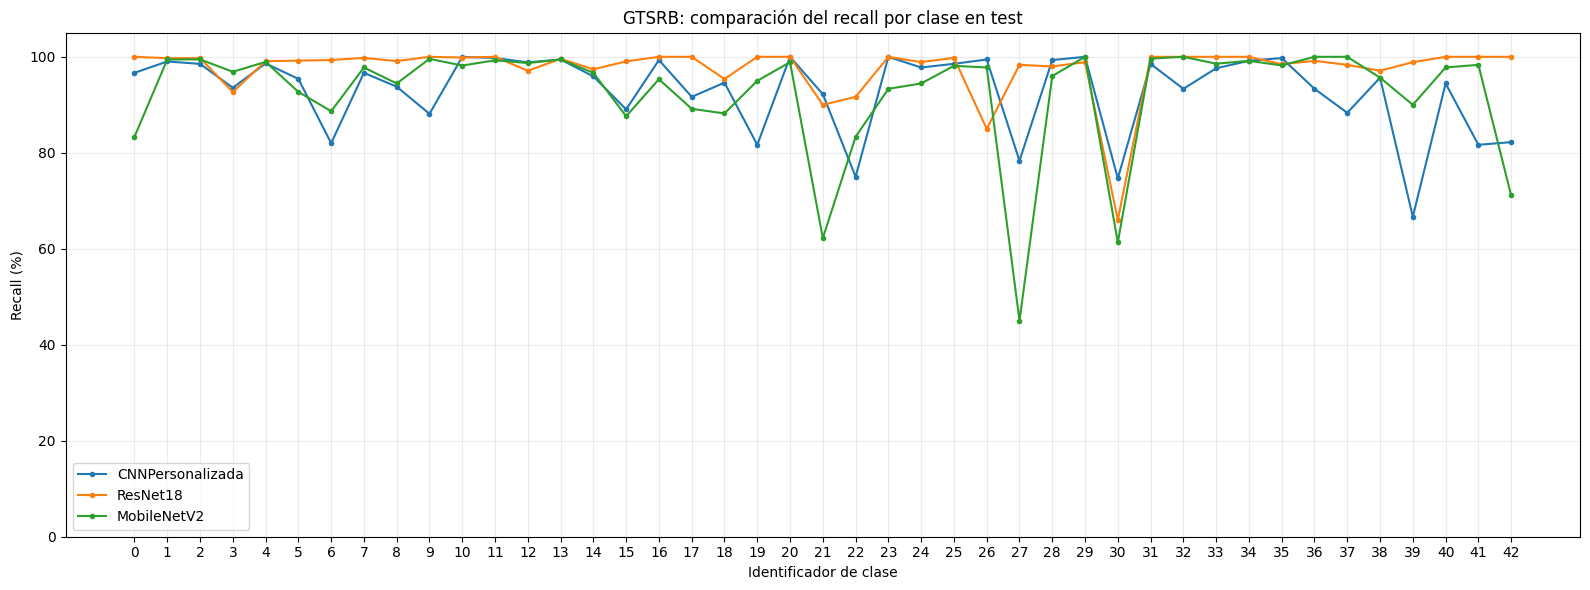


TABLA PARA EL ARTÍCULO CIENTÍFICO


,Modelo,Parametros,Accuracy,Precision_macro,Recall_macro,F1_macro,Errores,ms_por_imagen_en_lote
0,ResNet18,11190891,0.981156,0.978277,0.975706,0.975291,238,0.229233
1,CNNPersonalizada,99243,0.956849,0.956621,0.929932,0.939788,545,0.074301
2,MobileNetV2,2278955,0.955899,0.946519,0.925058,0.931028,557,0.425632



ARCHIVOS GENERADOS
Comparación por clase: True
Tabla para artículo: True
Figura recall: True
Síntesis Markdown: True
Entrenamientos realizados: 0


In [41]:

# PASO 40: Síntesis experimental de las tres arquitecturas.
# Utiliza exclusivamente resultados guardados.
# No realiza entrenamiento ni inferencia.

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Recuperar archivos de evaluación final.
BASE = Path(
    "/content/drive/MyDrive/Proyecto_VC_GTSRB"
)

RESULTADOS_TEST = BASE / "evaluacion_final_test"

resumen = pd.read_csv(
    RESULTADOS_TEST / "comparacion_final_tres_modelos.csv"
)

nombres = [
    "CNNPersonalizada",
    "ResNet18",
    "MobileNetV2"
]

# 2. Recuperar métricas por clase de los tres modelos.
tablas = {}

for nombre in nombres:

    ruta = (
        RESULTADOS_TEST
        / f"{nombre}_metricas_por_clase_test.csv"
    )

    df = pd.read_csv(ruta).sort_values("ClassId")

    assert np.array_equal(
        df["ClassId"].to_numpy(),
        np.arange(43)
    )

    tablas[nombre] = df.reset_index(drop=True)

# 3. Construir una comparación por clase.
comparacion = pd.DataFrame({
    "ClassId": np.arange(43),
    "Soporte": tablas[nombres[0]]["Soporte"]
})

for nombre in nombres:

    assert np.array_equal(
        comparacion["Soporte"].to_numpy(),
        tablas[nombre]["Soporte"].to_numpy()
    )

    comparacion[f"Recall_{nombre}"] = (
        tablas[nombre]["Recall"]
    )

    comparacion[f"F1_{nombre}"] = (
        tablas[nombre]["F1"]
    )

# 4. Revisar clases de interés.
clases_interes = [3, 9, 15, 19, 21, 27, 30, 36, 39, 42]

print("RECALL DE CLASES DE INTERÉS")

columnas_recall = [
    "ClassId",
    "Soporte"
] + [
    f"Recall_{nombre}" for nombre in nombres
]

display(
    comparacion.loc[
        comparacion["ClassId"].isin(clases_interes),
        columnas_recall
    ].round(4)
)

# 5. Identificar las clases más difíciles
# considerando el recall medio de los tres modelos.
columnas = [
    f"Recall_{nombre}" for nombre in nombres
]

comparacion["Recall_medio"] = (
    comparacion[columnas].mean(axis=1)
)

print("\n10 CLASES CON MENOR RECALL MEDIO")

display(
    comparacion[
        ["ClassId", "Soporte", "Recall_medio"]
    ].nsmallest(
        10, "Recall_medio"
    ).round(4)
)

# 6. Contar las clases en que cada arquitectura
# alcanza el mejor recall, incluyendo empates.
print("\nCLASES CON MEJOR RECALL POR MODELO")

maximos = comparacion[columnas].max(axis=1)

for nombre in nombres:

    ganadas = np.isclose(
        comparacion[f"Recall_{nombre}"],
        maximos
    )

    print(nombre, ":", int(ganadas.sum()))

print("Los empates se contabilizan para cada modelo.")

# 7. Representar recall por clase.
fig, ax = plt.subplots(figsize=(16, 6))

for nombre in nombres:

    ax.plot(
        comparacion["ClassId"],
        comparacion[f"Recall_{nombre}"] * 100,
        marker=".",
        linewidth=1.5,
        label=nombre
    )

ax.set_title(
    "GTSRB: comparación del recall por clase en test"
)

ax.set_xlabel("Identificador de clase")
ax.set_ylabel("Recall (%)")

ax.set_xticks(np.arange(43))
ax.set_ylim(0, 105)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()

ruta_figura = (
    RESULTADOS_TEST
    / "comparacion_recall_por_clase_test.png"
)

fig.savefig(
    ruta_figura,
    dpi=220,
    bbox_inches="tight"
)

plt.show()

# 8. Preparar tabla resumen para el artículo.
columnas_resumen = [
    "Modelo",
    "Parametros",
    "Accuracy",
    "Precision_macro",
    "Recall_macro",
    "F1_macro",
    "Errores",
    "ms_por_imagen_en_lote"
]

tabla_articulo = (
    resumen[columnas_resumen]
    .sort_values("F1_macro", ascending=False)
    .reset_index(drop=True)
)

print("\nTABLA PARA EL ARTÍCULO CIENTÍFICO")
display(tabla_articulo.round(6))

# 9. Guardar datos comparativos.
ruta_clases = (
    RESULTADOS_TEST
    / "comparacion_final_metricas_por_clase.csv"
)

ruta_tabla = (
    RESULTADOS_TEST
    / "tabla_resumen_articulo.csv"
)

comparacion.to_csv(ruta_clases, index=False)
tabla_articulo.to_csv(ruta_tabla, index=False)

# 10. Generar un resumen Markdown inicial.
mejor = tabla_articulo.iloc[0]

texto = f"""# Síntesis experimental GTSRB

## Protocolo

Se compararon tres arquitecturas entrenadas desde cero
sobre GTSRB, con 43 clases, imágenes RGB de 48x48,
particiones de entrenamiento y validación previamente
establecidas y 12 630 imágenes de prueba independientes.

## Resultado principal

La arquitectura con mayor F1-macro en prueba fue
{mejor['Modelo']}, con F1-macro de
{mejor['F1_macro']:.6f} y accuracy de
{mejor['Accuracy']:.6f}.

## Hallazgos

- La comparación principal favoreció a ResNet18.
- La CNN personalizada destacó por su tamaño reducido.
- MobileNetV2 no superó a la CNN personalizada
  en el conjunto de prueba de esta ejecución.
- El rendimiento varió entre clases, por lo que
  el accuracy global no resume todas las dificultades.

## Limitaciones

- Se utilizó una sola semilla de entrenamiento.
- Los intervalos bootstrap remuestrearon imágenes
  individualmente y no grupos de captura.
- Los tiempos de inferencia proceden de una medición
  en lotes sobre una Tesla T4 con AMP.
- Los resultados corresponden a este protocolo
  experimental y no garantizan igual rendimiento
  en otras condiciones de adquisición.

## Recomendación

Utilizar ResNet18 como mejor arquitectura global
entre las tres evaluadas, sin modificar los
checkpoints basándose en el conjunto de prueba.
"""

ruta_markdown = (
    RESULTADOS_TEST / "sintesis_experimental.md"
)

ruta_markdown.write_text(
    texto,
    encoding="utf-8"
)

print("\nARCHIVOS GENERADOS")
print("Comparación por clase:", ruta_clases.is_file())
print("Tabla para artículo:", ruta_tabla.is_file())
print("Figura recall:", ruta_figura.is_file())
print("Síntesis Markdown:", ruta_markdown.is_file())
print("Entrenamientos realizados: 0")


### Interpretación del Paso 40: Análisis final por clase

El análisis comparativo de recall sobre las 43 clases del conjunto de prueba confirmó la superioridad global de ResNet18, que alcanzó o igualó el mayor recall en 32 categorías. La clase 30 presentó el menor recall promedio entre las tres arquitecturas (67.33 %), evidenciando una dificultad compartida. Se identificaron diferencias importantes en las clases 19, 21, 27 y 39, lo que demuestra la necesidad de complementar las métricas globales con evaluaciones por clase. Estos resultados respaldan la selección de ResNet18 como la arquitectura con mejor rendimiento general bajo las condiciones experimentales establecidas.

In [42]:

# PASO 41: Respaldo final de los experimentos GTSRB.
# No realiza entrenamiento ni inferencia.
# Conserva los tres modelos y sus resultados.

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files
import hashlib
import shutil
import pandas as pd

# 1. Definir rutas de origen y destino.
BASE = Path(
    "/content/drive/MyDrive/Proyecto_VC_GTSRB"
)

CONSOLIDADO = BASE / "modelos_consolidados"
RESULTADOS_TEST = BASE / "evaluacion_final_test"

ENTREGABLES = BASE / "entregables"
ENTREGABLES.mkdir(parents=True, exist_ok=True)

ZIP_LOCAL = Path(
    "/content/GTSRB_Experimentos_Finales.zip"
)

ZIP_DRIVE = (
    ENTREGABLES / ZIP_LOCAL.name
)

# 2. Verificar los tres checkpoints obligatorios.
checkpoints = [
    "CNNPersonalizada_seed42_best.pth",
    "ResNet18_seed42_best.pth",
    "MobileNetV2_seed42_best.pth"
]

for nombre in checkpoints:
    ruta = CONSOLIDADO / "checkpoints" / nombre
    assert ruta.is_file(), f"Checkpoint faltante: {nombre}"

# 3. Verificar archivos científicos esenciales.
obligatorios = [
    CONSOLIDADO / "config_entrenamiento.json",
    RESULTADOS_TEST / "comparacion_final_tres_modelos.csv",
    RESULTADOS_TEST / "intervalos_confianza_f1_test.csv",
    RESULTADOS_TEST / "comparaciones_estadisticas_test.csv",
    RESULTADOS_TEST / "tabla_resumen_articulo.csv",
    RESULTADOS_TEST / "sintesis_experimental.md"
]

for ruta in obligatorios:
    assert ruta.is_file(), f"Archivo faltante: {ruta.name}"

# 4. Seleccionar archivos de ambas carpetas.
# Solo incluimos resultados científicos y modelos.
extensiones = {
    ".pth", ".csv", ".png",
    ".json", ".md"
}

archivos = []

for carpeta in [CONSOLIDADO, RESULTADOS_TEST]:

    for ruta in sorted(carpeta.rglob("*")):

        if ruta.is_file() and ruta.suffix.lower() in extensiones:

            nombre_zip = (
                Path(carpeta.name)
                / ruta.relative_to(carpeta)
            )

            archivos.append((ruta, nombre_zip.as_posix()))

# 5. Calcular huellas de integridad por archivo.
def calcular_sha256(ruta):

    h = hashlib.sha256()

    with open(ruta, "rb") as f:

        for bloque in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(bloque)

    return h.hexdigest()


manifiesto = []

for ruta, nombre_zip in archivos:

    manifiesto.append({
        "Archivo": nombre_zip,
        "Bytes": ruta.stat().st_size,
        "SHA256": calcular_sha256(ruta)
    })

tabla_manifiesto = pd.DataFrame(manifiesto)

# 6. Crear un documento informativo.
leeme = """# Proyecto GTSRB: Experimentos finales

## Modelos evaluados
- CNN personalizada: 99 243 parámetros.
- ResNet18: 11 190 891 parámetros.
- MobileNetV2: 2 278 955 parámetros.

## Metodología
- Dataset: GTSRB, 43 clases.
- Resolución de entrada: 48x48 RGB.
- Modelos entrenados desde cero.
- Optimizador: AdamW.
- Función de pérdida: CrossEntropyLoss.
- Mejor checkpoint seleccionado por F1-macro de validación.
- Prueba independiente: 12 630 imágenes.
- Semilla de entrenamiento: 42.

## Resultados finales en prueba
Modelo | Accuracy | F1-macro | Errores
CNN personalizada | 0.956849 | 0.939788 | 545
ResNet18 | 0.981156 | 0.975291 | 238
MobileNetV2 | 0.955899 | 0.931028 | 557

## Resultado principal
ResNet18 presentó el mayor rendimiento global.

## Limitaciones
- Se utilizó una sola semilla de entrenamiento.
- Los intervalos bootstrap se calcularon por imagen.
- Las mediciones de inferencia corresponden a lotes
  sobre Tesla T4, no a latencia individual.
- No se realizó optimización posterior usando test.

## Contenido
- modelos_consolidados/checkpoints: pesos entrenados.
- modelos_consolidados/resultados: validación e historiales.
- evaluacion_final_test: métricas, figuras y estadísticas.
- MANIFIESTO_SHA256.csv: integridad de archivos.

Los datos originales y el notebook ejecutado
se conservan por separado.
"""

# 7. Comprimir los resultados.
with ZipFile(
    ZIP_LOCAL,
    "w",
    ZIP_DEFLATED,
    compresslevel=6
) as zipf:

    for ruta, nombre_zip in archivos:

        zipf.write(
            ruta,
            arcname=nombre_zip
        )

    zipf.writestr(
        "MANIFIESTO_SHA256.csv",
        tabla_manifiesto.to_csv(index=False)
    )

    zipf.writestr(
        "LEEME_RESULTADOS.md",
        leeme
    )

# 8. Verificar el ZIP recién generado.
with ZipFile(ZIP_LOCAL) as zipf:

    assert zipf.testzip() is None

    nombres_incluidos = set(zipf.namelist())

    for nombre in checkpoints:

        esperado = (
            "modelos_consolidados/checkpoints/"
            + nombre
        )

        assert esperado in nombres_incluidos

print("RESPALDO FINAL DEL PROYECTO")

print("Checkpoints incluidos:", len(checkpoints))
print("Archivos científicos:", len(archivos))

print(
    "Tamaño ZIP (MB):",
    round(
        ZIP_LOCAL.stat().st_size / 1024**2,
        2
    )
)

print("Integridad ZIP: OK")

# 9. Conservar el paquete en Google Drive.
# Evitar sustituir un respaldo diferente.
if ZIP_DRIVE.is_file():

    assert (
        calcular_sha256(ZIP_DRIVE)
        == calcular_sha256(ZIP_LOCAL)
    ), "Ya existe otro respaldo con ese nombre."

else:
    shutil.copy2(ZIP_LOCAL, ZIP_DRIVE)

assert ZIP_DRIVE.is_file()

print("Respaldo guardado en Drive:", True)
print("Ruta:", ZIP_DRIVE)
print("Entrenamientos ejecutados: 0")

# 10. Descargar una copia a la computadora.
files.download(str(ZIP_LOCAL))


RESPALDO FINAL DEL PROYECTO
Checkpoints incluidos: 3
Archivos científicos: 38
Tamaño ZIP (MB): 143.96
Integridad ZIP: OK
Respaldo guardado en Drive: True
Ruta: /content/drive/MyDrive/Proyecto_VC_GTSRB/entregables/GTSRB_Experimentos_Finales.zip
Entrenamientos ejecutados: 0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Conclusiones generales del proyecto GTSRB

## 1. Resumen del experimento

Se desarrolló un sistema de clasificación de señales de tránsito utilizando el dataset German Traffic Sign Recognition Benchmark (GTSRB), compuesto por 43 categorías.

Se trabajó con 30 869 imágenes de entrenamiento, 8 340 de validación y 12 630 de prueba. Las imágenes se preprocesaron mediante recorte de la región de interés, redimensionamiento a 48 × 48 píxeles y normalización RGB.

Durante el entrenamiento se aplicaron aumentos dinámicos moderados de rotación, brillo y contraste. Las tres arquitecturas fueron entrenadas desde cero bajo un protocolo común, utilizando AdamW, entropía cruzada y selección del mejor checkpoint mediante F1-macro de validación.

## 2. Resultados finales

Los mejores checkpoints fueron evaluados sobre el conjunto independiente de 12 630 imágenes de prueba.

| Arquitectura | Parámetros | Accuracy | F1-macro | Errores |
|---|---:|---:|---:|---:|
| CNN personalizada | 99 243 | 95.68 % | 93.98 % | 545 |
| ResNet18 | 11 190 891 | **98.12 %** | **97.53 %** | **238** |
| MobileNetV2 | 2 278 955 | 95.59 % | 93.10 % | 557 |

ResNet18 obtuvo el mejor rendimiento global, superando a la CNN personalizada en 3.55 puntos porcentuales de F1-macro y a MobileNetV2 en 4.43 puntos porcentuales.

## 3. Análisis estadístico

Se realizó un análisis mediante bootstrap pareado con 1 000 repeticiones, complementado con la prueba de McNemar y corrección de Holm.

El intervalo de confianza del 95 % para el F1-macro de ResNet18 fue [97.18 %, 97.87 %]. Los intervalos de confianza de sus diferencias frente a las otras dos arquitecturas excluyeron cero.

Entre la CNN personalizada y MobileNetV2 se identificó una diferencia menor de F1-macro. La prueba de McNemar no encontró una diferencia estadísticamente significativa en la proporción de aciertos entre ambos modelos (p ajustado = 0.652874).

## 4. Análisis por clase

ResNet18 alcanzó o igualó el mejor recall en 32 de las 43 categorías, considerando los empates.

La clase 30 presentó el menor recall promedio entre las tres arquitecturas, con 67.33 %. En esta clase, la CNN personalizada obtuvo un recall de 74.67 %, ResNet18 de 66.00 % y MobileNetV2 de 61.33 %.

Estos resultados demuestran que un rendimiento global elevado no garantiza un reconocimiento uniforme de todas las categorías.

## 5. Conclusiones

1. **ResNet18 fue la arquitectura con mejor rendimiento general**, alcanzando un F1-macro de 97.53 % y un accuracy de 98.12 % en el conjunto independiente de prueba.

2. **La CNN personalizada demostró ser una alternativa compacta**, logrando un F1-macro de 93.98 % con solamente 99 243 parámetros entrenables.

3. **MobileNetV2 no superó a las otras arquitecturas en esta evaluación**, pese a contar con un diseño orientado a la eficiencia.

4. La evaluación mediante F1-macro, recall por clase y matrices de confusión permitió identificar diferencias que no serían evidentes utilizando únicamente accuracy.

5. El preprocesamiento controlado, el aislamiento de los conjuntos de datos y la selección de checkpoints mediante validación permitieron establecer una comparación experimental bajo condiciones documentadas.

## 6. Limitaciones y trabajo futuro

Los experimentos se realizaron utilizando una única semilla de entrenamiento. Por ello, los resultados no representan la variabilidad entre múltiples inicializaciones.

Los intervalos bootstrap se calcularon mediante remuestreo individual de imágenes, sin modelar explícitamente posibles dependencias entre capturas relacionadas.

Asimismo, los tiempos de inferencia registrados corresponden al procesamiento en lotes sobre una GPU Tesla T4 con precisión mixta; no representan necesariamente la latencia en dispositivos de producción.

Como trabajo futuro se propone repetir los entrenamientos con diferentes semillas, evaluar la robustez frente a condiciones adversas y analizar especialmente las clases con menor recall.

## 7. Resultado final del proyecto

Se completaron satisfactoriamente el preprocesamiento, entrenamiento, validación, evaluación independiente y análisis estadístico de tres arquitecturas convolucionales para clasificación de señales de tránsito.

Los checkpoints, historiales, métricas, matrices de confusión y figuras fueron respaldados en Google Drive mediante el archivo `GTSRB_Experimentos_Finales.zip`.

**Arquitectura seleccionada por rendimiento global: ResNet18.**